In [4]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [5]:
# 1 Import Libraries 

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import zipfile 

from pathlib import Path 
from scipy.stats import chi2_contingency 

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [7]:
# 2.0 Locate the RavenPack Dataset

file_path = Path("News Ml Project Data .csv")

print("File name:", file_path.name)
print("File exists:", file_path.exists())

if file_path.exists():
    print("File size (GB):", round(file_path.stat().st_size / 1e9, 2))

File name: News Ml Project Data .csv
File exists: True
File size (GB): 22.18


In [8]:
# 2.1 Initial Data Inspection

df_sample = pd.read_csv(file_path, nrows=1000)

print("Number of columns:", len(df_sample.columns))

display(df_sample.head())

Number of columns: 55


,cusip,rpa_date_utc,rpa_time_utc,timestamp_utc,rp_story_id,rp_entity_id,entity_type,entity_name,country_code,relevance,event_sentiment_score,event_relevance,event_similarity_key,event_similarity_days,topic,group,type,sub_type,property,fact_level,rp_position_id,position_name,evaluation_method,maturity,earnings_type,event_start_date_utc,event_end_date_utc,reporting_period,reporting_start_date_utc,reporting_end_date_utc,related_entity,relationship,category,event_text,news_type,rp_source_id,source_name,css,nip,peq,bee,bmq,bam,bca,ber,anl_chg,mcq,rp_story_event_index,rp_story_event_count,product_key,provider_id,provider_story_id,headline,ticker,isin
0,806857108,2025-01-01,05:01:00,2025-01-01 05:01:00.054,F34301F473827FD559413FD969C3F311,164D72,COMP,SLB Ltd.,US,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FULL-ARTICLE,B5569E,Dow Jones Newswires,0.00,0.14,0,0,0,0,0,0,0,0,1,12,RPA,DJ,DN20250101000005,SLB's Depressed Shares Don't Reflect the Compa...,SLB,AN8068571086
1,444859102,2023-01-03,22:00:56,2023-01-03 22:00:56.038,93B7F6DC0BD518EC6A966F4A26B0345C,00067A,COMP,Humana Inc.,US,100,-0.11,100.0,E5925043882D948857491BD8949E96EA,365.00000,business,stock-prices,stock-price,loss,NaN,fact,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2023-01-03 00:00:00,2023-01-04 00:00:00,NaN,NaN,stock-loss,Shares of Humana Inc. (HUM) shed 2.28% to $500.49,FULL-ARTICLE,1E5E35,MarketWatch,-0.22,-0.14,-1,0,-1,0,-1,-1,0,-1,1,8,RPA,DJ,SN20230103008029,"Humana Inc. Stock Falls Tuesday, Underperforms...",0J6Z,US4448591028
2,444859102,2023-01-04,21:15:00,2023-01-04 21:15:00.305,D453C0A5FBD5A3E68E98B162412E7E33,00067A,COMP,Humana Inc.,US,100,0.00,100.0,5F637CCC11251CDAED56A9610AA2AA88,44.59491,business,earnings,earnings,NaN,NaN,fact,NaN,NaN,NaN,NaN,NaN,2023-02-01 00:00:00,2023-02-02 00:00:00,2022-Q4,2022-10-01 00:00:00,2023-01-01 00:00:00,NaN,NaN,earnings,Humana Inc. to Release Fourth Quarter 2022 Res...,PRESS-RELEASE,A51917,Business Wire,0.00,-0.12,0,0,0,0,0,0,0,0,1,5,RPA,DJ,SN20230104009138,Humana Inc. to Release Fourth Quarter 2022 Res...,0J6Z,US4448591028
3,444859102,2023-01-04,21:15:00,2023-01-04 21:15:00.305,D453C0A5FBD5A3E68E98B162412E7E33,00067A,COMP,Humana Inc.,US,100,0.00,80.0,34DB5129E3F21B9A4EFFAF468F23B10A,63.44001,business,investor-relations,conference-call,NaN,NaN,fact,NaN,NaN,NaN,NaN,NaN,2023-01-04 09:00:00,2023-01-04 09:01:00,NaN,NaN,NaN,NaN,NaN,conference-call,Humana Inc.: The company will host a conferenc...,PRESS-RELEASE,A51917,Business Wire,0.00,-0.12,0,0,0,0,0,0,0,0,2,5,RPA,DJ,SN20230104009138,Humana Inc. to Release Fourth Quarter 2022 Res...,0J6Z,US4448591028
4,444859102,2023-01-04,21:16:33,2023-01-04 21:16:32.88,7B58E67D1854C56D3E36709ADA1C093D,00067A,COMP,Humana Inc.,US,100,0.00,100.0,5F637CCC11251CDAED56A9610AA2AA88,0.00102,business,earnings,earnings,NaN,NaN,fact,NaN,NaN,NaN,NaN,NaN,2023-02-01 00:00:00,2023-02-02 00:00:00,2022-Q4,2022-10-01 00:00:00,2023-01-01 00:00:00,NaN,NaN,earnings,Humana Inc. to Release Fourth Quarter 2022 Res...,PRESS-RELEASE,B5569E,Dow Jones Newswires,0.00,-0.14,0,0,0,0,0,0,0,0,1,4,RPA,DJ,DN20230104007399,Press Release: Humana Inc. to Release Fourth Q...,0J6Z,US4448591028


## 3.0 Initial Data Inspection

Before preprocessing the RavenPack dataset, we examine
its structure, variable types, missing values, and
unique observations. Due to the size of the original
dataset, the initial analysis is conducted using a
sample of 1,000 observations.

This inspection will help identify relevant variables,
potentially redundant information, and the appropriate
methods for processing numerical and categorical data.

### 3.1 Column Summary and Data Types

Each variable is examined based on its data type,
number of unique values, and percentage of missing
observations. This provides an initial understanding
of the information contained within each column.

In [10]:
# 3.1 Column Summary and Data Types

column_summary = pd.DataFrame({
    "Column": df_sample.columns,
    "Data Type": df_sample.dtypes.astype(str).values,
    "Non-Missing": df_sample.notna().sum().values,
    "Missing": df_sample.isna().sum().values,
    "Missing (%)": (
        df_sample.isna().mean().values * 100
    ).round(2),
    "Unique Values": df_sample.nunique().values
})

column_summary.index = range(1, len(column_summary) + 1)

display(column_summary)

,Column,Data Type,Non-Missing,Missing,Missing (%),Unique Values
1,cusip,object,1000,0,0.0,6
2,rpa_date_utc,object,1000,0,0.0,195
3,rpa_time_utc,object,1000,0,0.0,502
4,timestamp_utc,object,1000,0,0.0,695
5,rp_story_id,object,1000,0,0.0,695
6,rp_entity_id,object,1000,0,0.0,6
7,entity_type,object,1000,0,0.0,1
8,entity_name,object,1000,0,0.0,6
9,country_code,object,1000,0,0.0,1
10,relevance,int64,1000,0,0.0,11


### 3.2 Classification of Numerical and Categorical Variables

The RavenPack dataset contains different types of
information, including numerical scores, categorical
news classifications, company identifiers, timestamps,
and textual information.

Variables are classified according to the information
they represent rather than solely relying on the data
types assigned by Python. This distinction is important
because numerical and categorical variables require
different preprocessing and statistical analysis
methods.

The classification will also help determine which
variables are relevant for model construction and
which are necessary for data identification and merging.

In [11]:
# 3.2 Classification of Numerical and Categorical Variables

variable_groups = {

    "Numerical Scores": [
        "relevance",
        "event_sentiment_score",
        "event_relevance",
        "event_similarity_days",
        "css",
        "nip"
    ],

    "Discrete Signals": [
        "peq",
        "bee",
        "bmq",
        "bam",
        "bca",
        "ber",
        "anl_chg",
        "mcq"
    ],

    "Categorical Variables": [
        "entity_type",
        "country_code",
        "topic",
        "group",
        "type",
        "sub_type",
        "property",
        "fact_level",
        "position_name",
        "evaluation_method",
        "maturity",
        "earnings_type",
        "reporting_period",
        "related_entity",
        "relationship",
        "category",
        "news_type",
        "source_name"
    ],

    "Identifiers": [
        "cusip",
        "rp_story_id",
        "rp_entity_id",
        "entity_name",
        "event_similarity_key",
        "rp_position_id",
        "rp_source_id",
        "product_key",
        "provider_id",
        "provider_story_id",
        "ticker",
        "isin"
    ],

    "Date and Time Variables": [
        "rpa_date_utc",
        "rpa_time_utc",
        "timestamp_utc",
        "event_start_date_utc",
        "event_end_date_utc",
        "reporting_start_date_utc",
        "reporting_end_date_utc"
    ],

    "Text Variables": [
        "event_text",
        "headline"
    ],

    "Count and Index Variables": [
        "rp_story_event_index",
        "rp_story_event_count"
    ]
}

In [12]:
# 3.2.1 Variable Classification Summary

classification_summary = pd.DataFrame([
    {
        "Variable Group": group,
        "Number of Variables": len(columns)
    }
    for group, columns in variable_groups.items()
])

display(classification_summary)

print(
    "Total classified variables:",
    classification_summary["Number of Variables"].sum()
)

,Variable Group,Number of Variables
0,Numerical Scores,6
1,Discrete Signals,8
2,Categorical Variables,18
3,Identifiers,12
4,Date and Time Variables,7
5,Text Variables,2
6,Count and Index Variables,2


Total classified variables: 55


In [13]:
# 3.2.2 Validate Variable Classification

classified_columns = [
    column
    for columns in variable_groups.values()
    for column in columns
]

unclassified_columns = (
    set(df_sample.columns) - set(classified_columns)
)

unknown_columns = (
    set(classified_columns) - set(df_sample.columns)
)

duplicate_columns = pd.Series(classified_columns)
duplicate_columns = duplicate_columns[
    duplicate_columns.duplicated()
].tolist()

print("Original columns:", len(df_sample.columns))
print("Classified columns:", len(classified_columns))
print("Unclassified columns:", unclassified_columns)
print("Unknown columns:", unknown_columns)
print("Duplicate classifications:", duplicate_columns)

Original columns: 55
Classified columns: 55
Unclassified columns: set()
Unknown columns: set()
Duplicate classifications: []


The 55 original variables were successfully classified into
seven groups based on the type of information they represent.
The validation confirmed that all variables were accounted
for without any missing or duplicate classifications.

This classification provides a framework for analyzing the
relationships between numerical and categorical variables,
identifying redundant information, and selecting relevant
predictors for the machine learning models.

### 3.3 Full Dataset Inspection Using Chunk-Based Processing

Due to the size of the original RavenPack dataset, the
data is processed in chunks of 100,000 observations.
This approach allows us to examine the entire dataset
without loading all observations into memory at once.

The objective is to determine the total number of
observations, identify the percentage of missing values
for each variable, and establish the time coverage of
the dataset. These results will provide a more accurate
representation of the data than the initial sample.

In [14]:
# 3.3.1 Full Dataset Dimensions and Missing Values

chunk_size = 100_000

total_rows = 0
missing_counts = pd.Series(0, index=df_sample.columns, dtype="int64")

min_date = None
max_date = None

for i, chunk in enumerate(
    pd.read_csv(
        file_path,
        chunksize=chunk_size,
        dtype="string"
    ),
    start=1
):

    # Count observations
    total_rows += len(chunk)

    # Count missing values
    missing_counts += chunk.isna().sum()

    # Identify date coverage
    dates = pd.to_datetime(
        chunk["rpa_date_utc"],
        errors="coerce"
    )

    if dates.notna().any():

        chunk_min = dates.min()
        chunk_max = dates.max()

        if min_date is None or chunk_min < min_date:
            min_date = chunk_min

        if max_date is None or chunk_max > max_date:
            max_date = chunk_max

    # Display processing progress
    if i % 10 == 0:
        print(f"Observations processed: {total_rows:,}")

print("\nFull Dataset Summary")
print("Total observations:", f"{total_rows:,}")
print("Total columns:", len(df_sample.columns))
print("Start date:", min_date)
print("End date:", max_date)

Observations processed: 1,000,000
Observations processed: 2,000,000
Observations processed: 3,000,000
Observations processed: 4,000,000
Observations processed: 5,000,000
Observations processed: 6,000,000
Observations processed: 7,000,000
Observations processed: 8,000,000
Observations processed: 9,000,000
Observations processed: 10,000,000
Observations processed: 11,000,000
Observations processed: 12,000,000
Observations processed: 13,000,000
Observations processed: 14,000,000
Observations processed: 15,000,000
Observations processed: 16,000,000
Observations processed: 17,000,000
Observations processed: 18,000,000
Observations processed: 19,000,000
Observations processed: 20,000,000
Observations processed: 21,000,000
Observations processed: 22,000,000
Observations processed: 23,000,000
Observations processed: 24,000,000
Observations processed: 25,000,000
Observations processed: 26,000,000
Observations processed: 27,000,000
Observations processed: 28,000,000
Observations processed: 29,00

In [15]:
# 3.3.2 Full Dataset Missing-Value Summary

full_missing_summary = pd.DataFrame({
    "Column": missing_counts.index,
    "Total Observations": total_rows,
    "Non-Missing": (total_rows - missing_counts).values,
    "Missing": missing_counts.values,
    "Missing (%)": (
        missing_counts.values / total_rows * 100
    ).round(2)
})

full_missing_summary = full_missing_summary.sort_values(
    by="Missing (%)",
    ascending=False
).reset_index(drop=True)

full_missing_summary.index += 1

display(full_missing_summary)

,Column,Total Observations,Non-Missing,Missing,Missing (%)
1,maturity,50999638,9693,50989945,99.98
2,evaluation_method,50999638,94120,50905518,99.82
3,relationship,50999638,758669,50240969,98.51
4,related_entity,50999638,758669,50240969,98.51
5,earnings_type,50999638,836104,50163534,98.36
6,position_name,50999638,1455896,49543742,97.15
7,rp_position_id,50999638,1455896,49543742,97.15
8,event_end_date_utc,50999638,1768622,49231016,96.53
9,event_start_date_utc,50999638,1768622,49231016,96.53
10,reporting_period,50999638,2836576,48163062,94.44


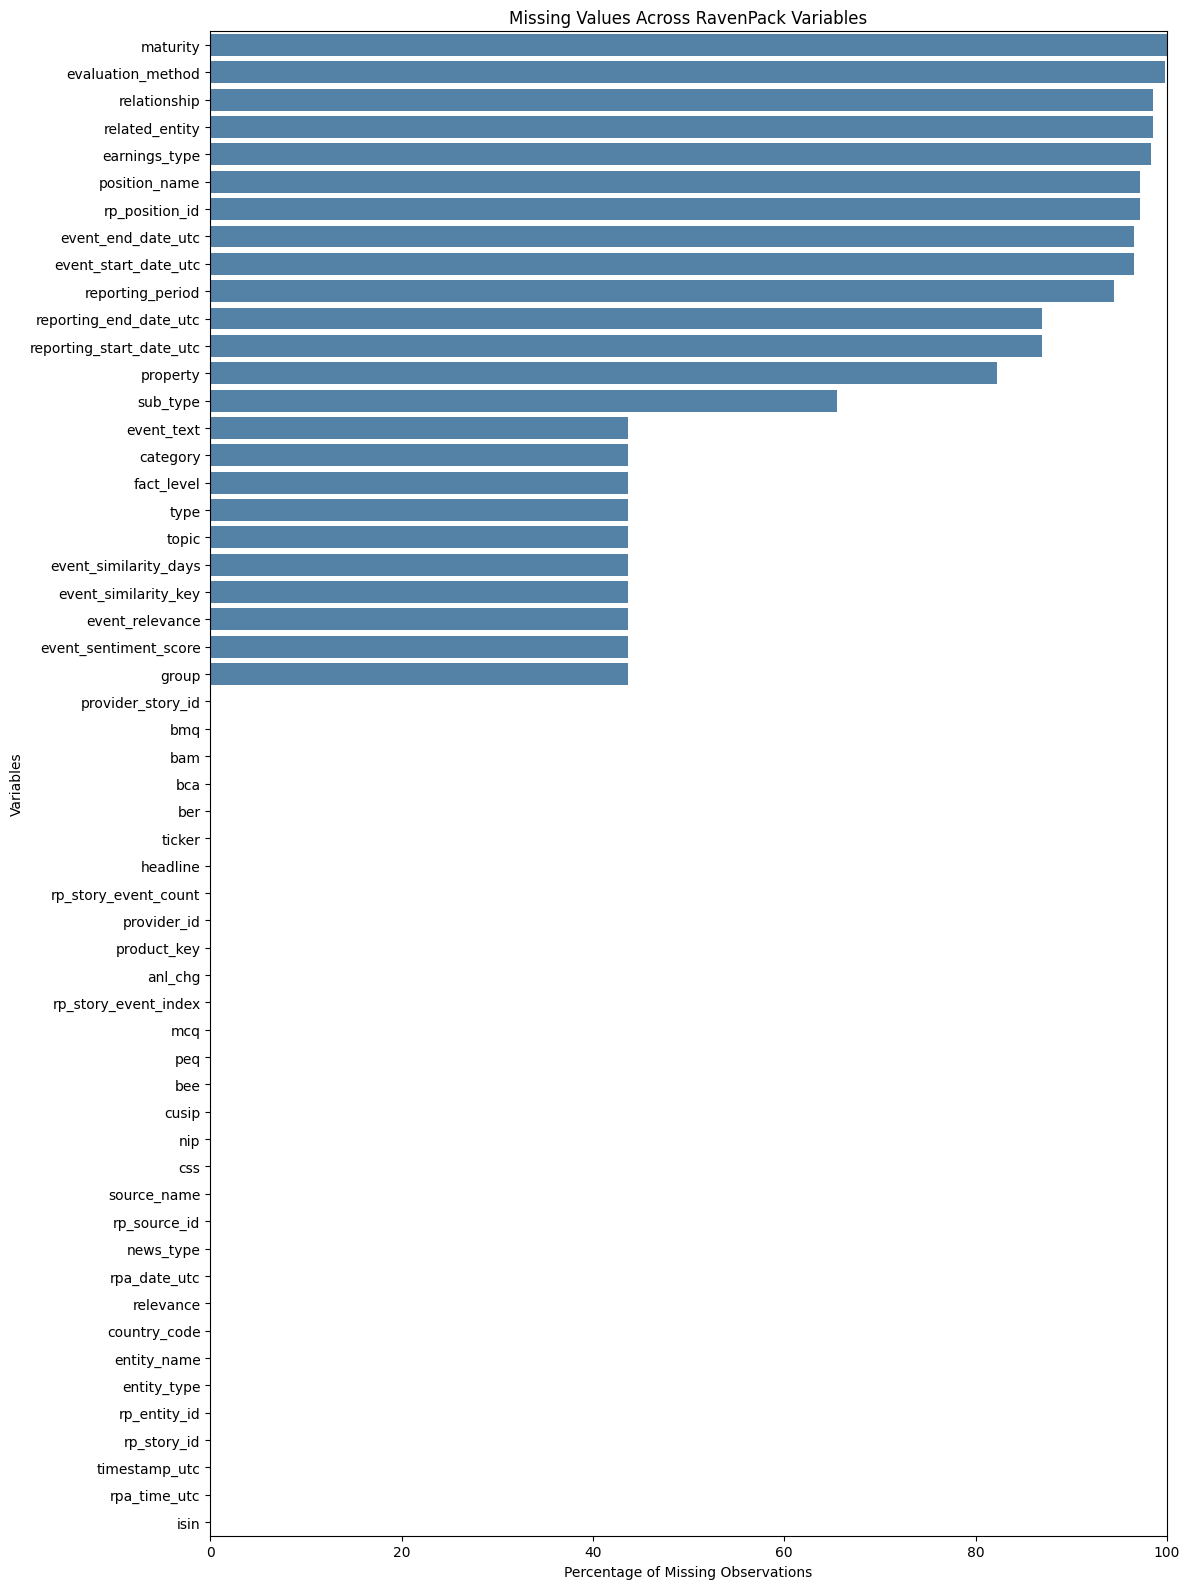

In [16]:
# 3.3.3 Missing-Value Visualization

plt.figure(figsize=(12, 16))

sns.barplot(
    data=full_missing_summary,
    x="Missing (%)",
    y="Column",
    color="steelblue"
)

plt.title("Missing Values Across RavenPack Variables")
plt.xlabel("Percentage of Missing Observations")
plt.ylabel("Variables")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

### 3.3.4 Interpretation of Results

The original RavenPack dataset contains 50,999,638
observations and 55 variables, covering the period
from January 1, 2020, to January 1, 2025.

The full dataset analysis revealed significant
differences in missing values compared to the initial
sample of 1,000 observations. Approximately 43.64%
of the observations do not contain an assigned event
category, leaving 28,744,999 observations with
classified event information.

Several variables contain a high percentage of missing
values. However, these variables may provide information
specific to certain news categories. Therefore, variables
will not be removed solely based on their percentage
of missing observations.

Further analysis will examine the number of unique
values, relationships between variables, and the
information each variable contributes before making
final preprocessing decisions.

### 3.4 Unique Values and Constant Columns

The categorical variables are examined to determine
the number of unique classifications and the frequency
of each classification across the entire dataset.

This analysis will help identify constant variables,
understand the RavenPack classification structure,
and determine whether certain variables contain
redundant information.

The results will also provide a foundation for mapping
the original RavenPack classifications to the news
categories used in the machine learning models.

In [17]:
# 3.4.1 Unique Values and Category Frequencies

from collections import Counter

analysis_columns = [
    "entity_type",
    "country_code",
    "topic",
    "group",
    "type",
    "sub_type",
    "property",
    "category",
    "fact_level",
    "earnings_type",
    "evaluation_method",
    "maturity",
    "relationship",
    "news_type",
    "source_name",
    "product_key",
    "provider_id",
    "peq",
    "bee",
    "bmq",
    "bam",
    "bca",
    "ber",
    "anl_chg",
    "mcq"
]

category_counts = {
    col: Counter() for col in analysis_columns
}

rows_processed = 0

for i, chunk in enumerate(
    pd.read_csv(
        file_path,
        usecols=analysis_columns,
        chunksize=100_000,
        dtype="string"
    ),
    start=1
):

    rows_processed += len(chunk)

    for col in analysis_columns:
        category_counts[col].update(
            chunk[col].value_counts().to_dict()
        )

    if i % 50 == 0:
        print(f"Observations processed: {rows_processed:,}")

print("\nAnalysis complete.")
print(f"Total observations processed: {rows_processed:,}")

Observations processed: 5,000,000
Observations processed: 10,000,000
Observations processed: 15,000,000
Observations processed: 20,000,000
Observations processed: 25,000,000
Observations processed: 30,000,000
Observations processed: 35,000,000
Observations processed: 40,000,000
Observations processed: 45,000,000
Observations processed: 50,000,000

Analysis complete.
Total observations processed: 50,999,638


In [18]:
# 3.4.2 Unique Values Summary

unique_summary = pd.DataFrame([
    {
        "Column": col,
        "Unique Values": len(category_counts[col]),
        "Most Frequent Value": (
            category_counts[col].most_common(1)[0][0]
            if category_counts[col] else None
        ),
        "Frequency": (
            category_counts[col].most_common(1)[0][1]
            if category_counts[col] else 0
        )
    }
    for col in analysis_columns
])

unique_summary = unique_summary.sort_values(
    by="Unique Values",
    ascending=False
).reset_index(drop=True)

unique_summary.index += 1

display(unique_summary)

,Column,Unique Values,Most Frequent Value,Frequency
1,category,1007,stock-loss,2844626
2,type,295,stock-price,5464425
3,sub_type,110,loss,2862857
4,group,51,stock-prices,5464425
5,property,32,rater,6495751
6,source_name,24,Dow Jones Newswires,25916544
7,country_code,12,US,50163061
8,news_type,10,PRESS-RELEASE,22215372
9,earnings_type,9,ex-exceptionals,373246
10,topic,5,business,27873670


In [19]:
# 3.4.3 Identify Constant Columns

constant_columns = unique_summary[
    unique_summary["Unique Values"] == 1
]

display(constant_columns)

print(
    "Number of constant columns among those analyzed:",
    len(constant_columns)
)

,Column,Unique Values,Most Frequent Value,Frequency
22,entity_type,1,COMP,50999638
23,provider_id,1,DJ,50999638
24,product_key,1,RPA,50999638
25,relationship,1,PRODUCT,758669


Number of constant columns among those analyzed: 4


In [20]:
# 3.4.4 Examine RavenPack News Classifications

taxonomy_columns = [
    "topic",
    "group",
    "type",
    "sub_type",
    "property",
    "category",
    "fact_level"
]

for col in taxonomy_columns:

    print(f"\n{col.upper()}")
    print("Unique values:", len(category_counts[col]))

    frequency_table = pd.DataFrame(
        category_counts[col].most_common(20),
        columns=["Classification", "Frequency"]
    )

    display(frequency_table)


TOPIC
Unique values: 5


,Classification,Frequency
0,business,27873670
1,society,836513
2,economy,25827
3,politics,8367
4,environment,622



GROUP
Unique values: 51


,Classification,Frequency
0,stock-prices,5464425
1,price-targets,4088888
2,analyst-ratings,3927244
3,earnings,3243088
4,products-services,1888045
5,revenues,1876277
6,partnerships,1321471
7,insider-trading,1111089
8,equity-actions,912504
9,marketing,890860



TYPE
Unique values: 295


,Classification,Frequency
0,stock-price,5464425
1,price-target,4088888
2,analyst-ratings-change,3608559
3,earnings,1645584
4,partnership,1309803
5,revenue,1292332
6,conference,873897
7,earnings-per-share,625474
8,product-release,511592
9,insider-sell,442151


... (4 outputs left out)


CATEGORY
Unique values: 1007


,Classification,Frequency
0,stock-loss,2844626
1,stock-gain,2513338
2,analyst-ratings-change-neutral-rater,1908129
3,price-target-upgrade-rater,1424058
4,price-target-downgrade-rater,1369647
5,partnership,1280416
6,earnings,948625
7,conference-organizer,801570
8,analyst-ratings-change-neutral,642713
9,revenues,595205



FACT_LEVEL
Unique values: 3


,Classification,Frequency
0,fact,27612568
1,forecast,791635
2,opinion,340796


### 3.4.5 Interpretation of Results

The full dataset contains five news topics, 51 news
groups, 295 event types, 110 event subtypes, and
1,007 distinct event categories. These results indicate
that RavenPack provides a detailed classification
structure for company news.

Business-related news represents approximately 97%
of classified observations. Stock prices, analyst price
targets, analyst ratings, and earnings are among the
most frequently observed news groups.

The analysis also identified three variables that are
constant across all observations: entity_type,
provider_id, and product_key. These variables do not
provide variation that could contribute directly to
the machine learning models.

The relationship variable contains only one non-missing
classification but is retained for further examination
because its missingness may contain information.

The original RavenPack classifications will be examined
further to establish relationships between variables
and develop a consistent mapping to the news categories
used in the machine learning models.

## 4.0 Redundancy Analysis and Data Cleaning

The RavenPack dataset contains several variables that
may represent overlapping information. Before removing
or combining variables, their relationships are examined
to determine whether they provide unique information.

The analysis focuses on categorical classifications,
company identifiers, news sources, and timestamps.

### 4.1 Identify Overlapping News Classifications

The relationships between the original RavenPack
classification variables are examined to determine
whether each event category corresponds to a consistent
combination of topic, group, type, subtype, and property.

In [21]:
# 4.1.1 Construct the Classification Mapping

taxonomy_columns = [
    "topic",
    "group",
    "type",
    "sub_type",
    "property",
    "category"
]

taxonomy_counts = Counter()

rows_processed = 0

for i, chunk in enumerate(
    pd.read_csv(
        file_path,
        usecols=taxonomy_columns,
        chunksize=100_000,
        dtype="string"
    ),
    start=1
):

    rows_processed += len(chunk)

    # Retain observations with a classified event
    classified = chunk.dropna(subset=["category"])

    # Preserve missing classification levels
    classified = classified[taxonomy_columns].fillna(
        "<MISSING>"
    )

    # Count unique classification combinations
    combinations = classified.value_counts()

    taxonomy_counts.update(combinations.to_dict())

    if i % 50 == 0:
        print(f"Observations processed: {rows_processed:,}")

print("\nAnalysis complete.")
print(f"Total observations processed: {rows_processed:,}")
print("Unique taxonomy combinations:", len(taxonomy_counts))

Observations processed: 5,000,000
Observations processed: 10,000,000
Observations processed: 15,000,000
Observations processed: 20,000,000
Observations processed: 25,000,000
Observations processed: 30,000,000
Observations processed: 35,000,000
Observations processed: 40,000,000
Observations processed: 45,000,000
Observations processed: 50,000,000

Analysis complete.
Total observations processed: 50,999,638
Unique taxonomy combinations: 1007


In [22]:
# 4.1.2 Create the RavenPack Taxonomy Dictionary

taxonomy_dictionary = pd.DataFrame(
    [
        (*classification, frequency)
        for classification, frequency
        in taxonomy_counts.items()
    ],
    columns=taxonomy_columns + ["frequency"]
)

taxonomy_dictionary = taxonomy_dictionary.sort_values(
    "frequency",
    ascending=False
).reset_index(drop=True)

display(taxonomy_dictionary.head(30))

print(
    "Total classified observations:",
    f"{taxonomy_dictionary['frequency'].sum():,}"
)

print(
    "Unique categories:",
    taxonomy_dictionary["category"].nunique()
)

,topic,group,type,sub_type,property,category,frequency
0,business,stock-prices,stock-price,loss,<MISSING>,stock-loss,2844626
1,business,stock-prices,stock-price,gain,<MISSING>,stock-gain,2513338
2,business,analyst-ratings,analyst-ratings-change,neutral,rater,analyst-ratings-change-neutral-rater,1908129
3,business,price-targets,price-target,upgrade,rater,price-target-upgrade-rater,1424058
4,business,price-targets,price-target,downgrade,rater,price-target-downgrade-rater,1369647
5,business,partnerships,partnership,<MISSING>,<MISSING>,partnership,1280416
6,business,earnings,earnings,<MISSING>,<MISSING>,earnings,948625
7,business,marketing,conference,<MISSING>,organizer,conference-organizer,801570
8,business,analyst-ratings,analyst-ratings-change,neutral,<MISSING>,analyst-ratings-change-neutral,642713
9,business,revenues,revenue,<MISSING>,<MISSING>,revenues,595205


Total classified observations: 28,744,999
Unique categories: 1007


In [23]:
# 4.1.3 Test Categorical Redundancy

redundancy_results = []

for col in taxonomy_columns:

    if col == "category":
        continue

    mappings = (
        taxonomy_dictionary
        .groupby("category")[col]
        .nunique()
    )

    redundancy_results.append({
        "Variable": col,
        "Total Categories": len(mappings),
        "Unique Mapping": (mappings == 1).sum(),
        "Multiple Mappings": (mappings > 1).sum(),
        "Unique Mapping (%)": round(
            (mappings == 1).mean() * 100, 2
        )
    })

redundancy_summary = pd.DataFrame(
    redundancy_results
)

display(redundancy_summary)

,Variable,Total Categories,Unique Mapping,Multiple Mappings,Unique Mapping (%)
0,topic,1007,1007,0,100.0
1,group,1007,1007,0,100.0
2,type,1007,1007,0,100.0
3,sub_type,1007,1007,0,100.0
4,property,1007,1007,0,100.0


In [24]:
# 4.1.4 Validate Taxonomy Coverage

expected_classified_rows = (
    total_rows - missing_counts["category"]
)

actual_classified_rows = (
    taxonomy_dictionary["frequency"].sum()
)

print("Expected classified observations:",
      f"{expected_classified_rows:,}")

print("Actual classified observations:",
      f"{actual_classified_rows:,}")

print("Coverage matches:",
      expected_classified_rows == actual_classified_rows)

print("Expected unique categories:",
      len(category_counts["category"]))

print("Actual unique categories:",
      taxonomy_dictionary["category"].nunique())

Expected classified observations: 28,744,999
Actual classified observations: 28,744,999
Coverage matches: True
Expected unique categories: 1007
Actual unique categories: 1007


### 4.1.5 Interpretation of Results

The redundancy analysis identified 1,007 unique event
categories and 1,007 corresponding taxonomy combinations.

Each event category has a unique mapping to topic, group,
type, subtype, and property. All five classification
variables achieved a unique mapping of 100%, indicating
that their information can be recovered from the category
variable using the constructed taxonomy dictionary.

The validation also confirmed that all 28,744,999
classified observations were accounted for.

These findings suggest that the classification structure
can be simplified without losing taxonomy information
for classified events. However, the original classification
variables will be retained during the preprocessing stage
to assist with the construction of the news categories
used in the machine learning models.

### 4.1.5 Interpretation of Results

The redundancy analysis identified 1,007 unique event
categories and 1,007 corresponding taxonomy combinations.

Each event category has a unique mapping to topic, group,
type, subtype, and property. All five classification
variables achieved a unique mapping of 100%, indicating
that their information can be recovered from the category
variable using the constructed taxonomy dictionary.

The validation also confirmed that all 28,744,999
classified observations were accounted for.

These findings suggest that the classification structure
can be simplified without losing taxonomy information
for classified events. However, the original classification
variables will be retained during the preprocessing stage
to assist with the construction of the news categories
used in the machine learning models.

In [26]:
# 4.1.6 Preserve the RavenPack Taxonomy Dictionary

output_folder = Path("data")
output_folder.mkdir(exist_ok=True)

taxonomy_dictionary.to_parquet(
    output_folder / "ravenpack_taxonomy.parquet",
    index=False
)

print("Taxonomy dictionary saved successfully.")
print("Rows:", len(taxonomy_dictionary))
print("Columns:", len(taxonomy_dictionary.columns))

Taxonomy dictionary saved successfully.
Rows: 1007
Columns: 7


### 4.2 Identifier and Timestamp Redundancy

Several variables in the RavenPack dataset are used
to identify companies, news stories, news sources,
and publication times.

The relationships between these variables are examined
to determine whether they contain overlapping
information or serve different purposes.

This analysis is particularly important for identifying
the appropriate variables to retain when merging the
RavenPack dataset with traditional stock data.

In [27]:
# 4.2.1 Construct Identifier Mapping Tables

identifier_pairs = {
    "Source Mapping": [
        "rp_source_id", "source_name"
    ],

    "Position Mapping": [
        "rp_position_id", "position_name"
    ],

    "Company Name Mapping": [
        "rp_entity_id", "entity_name"
    ],

    "CUSIP Mapping": [
        "rp_entity_id", "cusip"
    ],

    "Ticker Mapping": [
        "rp_entity_id", "ticker"
    ],

    "ISIN Mapping": [
        "rp_entity_id", "isin"
    ]
}

identifier_columns = sorted({
    col
    for columns in identifier_pairs.values()
    for col in columns
})

identifier_mappings = {
    name: Counter()
    for name in identifier_pairs
}

rows_processed = 0

for i, chunk in enumerate(
    pd.read_csv(
        file_path,
        usecols=identifier_columns,
        chunksize=100_000,
        dtype="string"
    ),
    start=1
):

    rows_processed += len(chunk)

    for name, columns in identifier_pairs.items():

        combinations = (
            chunk[columns]
            .dropna()
            .value_counts()
        )

        identifier_mappings[name].update(
            combinations.to_dict()
        )

    if i % 50 == 0:
        print(
            f"Observations processed: {rows_processed:,}"
        )

print("\nAnalysis complete.")
print(f"Total observations processed: {rows_processed:,}")

for name, mappings in identifier_mappings.items():
    print(f"{name}: {len(mappings):,} unique combinations")

Observations processed: 5,000,000
Observations processed: 10,000,000
Observations processed: 15,000,000
Observations processed: 20,000,000
Observations processed: 25,000,000
Observations processed: 30,000,000
Observations processed: 35,000,000
Observations processed: 40,000,000
Observations processed: 45,000,000
Observations processed: 50,000,000

Analysis complete.
Total observations processed: 50,999,638
Source Mapping: 24 unique combinations
Position Mapping: 295 unique combinations
Company Name Mapping: 537 unique combinations
CUSIP Mapping: 541 unique combinations
Ticker Mapping: 1,395 unique combinations
ISIN Mapping: 1,244 unique combinations


In [28]:
# 4.2.2 Analyze Identifier Relationships

identifier_results = []
mapping_tables = {}

for name, columns in identifier_pairs.items():

    mapping_df = pd.DataFrame(
        [
            (*pair, frequency)
            for pair, frequency
            in identifier_mappings[name].items()
        ],
        columns=columns + ["frequency"]
    )

    mapping_tables[name] = mapping_df

    left_mapping = (
        mapping_df.groupby(columns[0])[columns[1]]
        .nunique()
    )

    right_mapping = (
        mapping_df.groupby(columns[1])[columns[0]]
        .nunique()
    )

    identifier_results.append({
        "Mapping": name,
        "First Variable": columns[0],
        "Second Variable": columns[1],
        "Unique First Values": len(left_mapping),
        "Unique Second Values": len(right_mapping),
        "Unique Combinations": len(mapping_df),
        "First to Second (%)": round(
            (left_mapping == 1).mean() * 100, 2
        ),
        "Second to First (%)": round(
            (right_mapping == 1).mean() * 100, 2
        )
    })

identifier_summary = pd.DataFrame(identifier_results)

display(identifier_summary)

,Mapping,First Variable,Second Variable,Unique First Values,Unique Second Values,Unique Combinations,First to Second (%),Second to First (%)
0,Source Mapping,rp_source_id,source_name,23,24,24,95.65,100.00
1,Position Mapping,rp_position_id,position_name,286,295,295,96.85,100.00
2,Company Name Mapping,rp_entity_id,entity_name,537,537,537,100.00,100.00
3,CUSIP Mapping,rp_entity_id,cusip,537,541,541,99.26,100.00
4,Ticker Mapping,rp_entity_id,ticker,537,1394,1395,19.93,99.93
5,ISIN Mapping,rp_entity_id,isin,537,1244,1244,49.53,100.00


In [29]:
# 4.2.3 Examine Companies With Multiple Tickers

ticker_mapping = mapping_tables["Ticker Mapping"]

ticker_counts = (
    ticker_mapping
    .groupby("rp_entity_id")["ticker"]
    .nunique()
    .sort_values(ascending=False)
)

multiple_tickers = ticker_counts[ticker_counts > 1]

print("Total unique RavenPack entities:",
      len(ticker_counts))

print("Entities with multiple tickers:",
      len(multiple_tickers))

print("Maximum tickers per entity:",
      ticker_counts.max())

display(multiple_tickers.head(20))

Total unique RavenPack entities: 537
Entities with multiple tickers: 430
Maximum tickers per entity: 9


rp_entity_id
168A5D    9
6166D1    8
50070E    7
12E454    7
12DE76    6
41EC04    6
DD3BB1    6
93D207    6
228D42    6
7A51FE    6
BB88B6    5
7BFF81    5
911AB8    5
EEA6B3    5
2CB4C9    5
619882    5
4A6F00    5
B5DE80    5
DD1BA1    5
859D62    5
Name: ticker, dtype: int64

In [30]:
# 4.2.4 Examine Companies With Multiple CUSIPs

cusip_mapping = mapping_tables["CUSIP Mapping"]

cusip_counts = (
    cusip_mapping
    .groupby("rp_entity_id")["cusip"]
    .nunique()
    .sort_values(ascending=False)
)

multiple_cusips = cusip_counts[cusip_counts > 1]

print("Total unique RavenPack entities:",
      len(cusip_counts))

print("Entities with multiple CUSIPs:",
      len(multiple_cusips))

print("Maximum CUSIPs per entity:",
      cusip_counts.max())

display(multiple_cusips.head(20))

Total unique RavenPack entities: 537
Entities with multiple CUSIPs: 4
Maximum CUSIPs per entity: 2


rp_entity_id
4A6F00    2
41EC04    2
DD1BA1    2
7BFF81    2
Name: cusip, dtype: int64

### 4.2.5 Interpretation of Results

The identifier analysis identified 537 unique RavenPack
entities, 541 unique CUSIPs, 1,394 unique ticker symbols,
and 1,244 unique ISINs.

The RavenPack entity identifier and company name
demonstrated a one-to-one relationship across the
entire dataset. However, the relationship between
company identifiers and security identifiers was
not always one-to-one.

A total of 430 companies were associated with multiple
ticker symbols, compared to only four companies
associated with multiple CUSIPs.

These findings suggest that ticker symbols alone
may not provide a reliable method for merging
the RavenPack dataset with traditional stock data.
The RavenPack entity identifier and CUSIP will
therefore be retained during preprocessing.

A historical security mapping will be required to
establish the relationship between RavenPack company
identifiers and the PERMNO identifiers used in the
stock dataset.

In [31]:
# 4.2.6 Examine Companies With Multiple CUSIPs

company_names = mapping_tables["Company Name Mapping"][
    ["rp_entity_id", "entity_name"]
]

multiple_cusip_details = (
    cusip_mapping[
        cusip_mapping["rp_entity_id"].isin(
            multiple_cusips.index
        )
    ]
    .merge(
        company_names,
        on="rp_entity_id",
        how="left"
    )
    .sort_values(["rp_entity_id", "cusip"])
)

display(multiple_cusip_details)

,rp_entity_id,cusip,frequency,entity_name
0,41EC04,904311107,48708,Under Armour Inc.
1,41EC04,904311206,48708,Under Armour Inc.
2,4A6F00,02079K107,2714245,Alphabet Inc.
3,4A6F00,02079K305,2714245,Alphabet Inc.
4,7BFF81,35137L105,49520,Fox Corp.
5,7BFF81,35137L204,49520,Fox Corp.
6,DD1BA1,65249B109,142620,News Corp.
7,DD1BA1,65249B208,142620,News Corp.


In [32]:
# 4.2.7 Preserve Identifier Mapping Tables

mapping_folder = output_folder / "mappings"

mapping_folder.mkdir(exist_ok=True)

for name, table in mapping_tables.items():

    filename = name.lower().replace(" ", "_")

    table.to_parquet(
        mapping_folder / f"{filename}.parquet",
        index=False
    )

    print(f"Saved: {filename}.parquet")

Saved: source_mapping.parquet
Saved: position_mapping.parquet
Saved: company_name_mapping.parquet
Saved: cusip_mapping.parquet
Saved: ticker_mapping.parquet
Saved: isin_mapping.parquet


### 4.2.8 Interpretation of Multiple CUSIPs

Four companies were identified as having multiple
CUSIP identifiers: Under Armour, Alphabet, Fox
Corporation, and News Corporation.

Each company's two CUSIPs contain an identical
number of news observations. This suggests that
company-level news may be associated with multiple
share classes.

These observations will be retained during
preprocessing because different securities may
have different stock returns. Further validation
will be conducted during the financial data merge.

### 4.3 Timestamp and Repeated News Analysis

The RavenPack dataset contains multiple variables
representing the publication date, publication time,
and timestamp of news observations.

These variables are examined to determine whether
they contain redundant information and establish
which timestamp should be retained for constructing
the prediction cutoff.

The analysis also examines repeated news coverage
to determine whether multiple observations represent
distinct events or repeated reports of the same event.

In [33]:
# 4.3.1 Examine Timestamp Consistency

timestamp_columns = [
    "rpa_date_utc",
    "rpa_time_utc",
    "timestamp_utc"
]

timestamp_results = Counter()

rows_processed = 0

max_time_difference = 0

for i, chunk in enumerate(
    pd.read_csv(
        file_path,
        usecols=timestamp_columns,
        chunksize=100_000,
        dtype="string"
    ),
    start=1
):

    rows_processed += len(chunk)

    original_timestamp = pd.to_datetime(
        chunk["timestamp_utc"],
        format="mixed",
        errors="coerce",
        utc=True
    )

    combined_timestamp = pd.to_datetime(
        chunk["rpa_date_utc"] + " " +
        chunk["rpa_time_utc"],
        format="mixed",
        errors="coerce",
        utc=True
    )

    valid = (
        original_timestamp.notna() &
        combined_timestamp.notna()
    )

    difference = (
        original_timestamp[valid] -
        combined_timestamp[valid]
    ).dt.total_seconds().abs()

    timestamp_results["Total Observations"] += len(chunk)

    timestamp_results["Valid Timestamp Pairs"] += (
        valid.sum()
    )

    timestamp_results["Invalid Timestamp Pairs"] += (
        (~valid).sum()
    )

    timestamp_results["Exact Matches"] += (
        difference == 0
    ).sum()

    timestamp_results["Within One Second"] += (
        difference <= 1
    ).sum()

    timestamp_results["More Than One Second"] += (
        difference > 1
    ).sum()

    timestamp_results["Matching Dates"] += (
        original_timestamp[valid].dt.normalize() ==
        combined_timestamp[valid].dt.normalize()
    ).sum()

    if not difference.empty:

        max_time_difference = max(
            max_time_difference,
            difference.max()
        )

    if i % 50 == 0:
        print(
            f"Observations processed: {rows_processed:,}"
        )

print("\nAnalysis complete.")
print("Maximum time difference (seconds):",
      max_time_difference)

Observations processed: 5,000,000
Observations processed: 10,000,000
Observations processed: 15,000,000
Observations processed: 20,000,000
Observations processed: 25,000,000
Observations processed: 30,000,000
Observations processed: 35,000,000
Observations processed: 40,000,000
Observations processed: 45,000,000
Observations processed: 50,000,000

Analysis complete.
Maximum time difference (seconds): 86399.961


In [34]:
# 4.3.2 Timestamp Consistency Summary

timestamp_summary = pd.DataFrame(
    timestamp_results.items(),
    columns=["Metric", "Observations"]
)

timestamp_summary["Percentage (%)"] = (
    timestamp_summary["Observations"] /
    rows_processed * 100
).round(4)

display(timestamp_summary)

,Metric,Observations,Percentage (%)
0,Total Observations,50999638,100.0000
1,Valid Timestamp Pairs,50999638,100.0000
2,Invalid Timestamp Pairs,0,0.0000
3,Exact Matches,48110,0.0943
4,Within One Second,50999584,99.9999
5,More Than One Second,54,0.0001
6,Matching Dates,50999638,100.0000


### 4.3.3 Interpretation of Timestamp Consistency

All 50,999,638 timestamp pairs were successfully
validated, with no invalid timestamps identified.

Approximately 99.9999% of observations contain
timestamp differences of one second or less.
Furthermore, all observations contain matching
calendar dates.

These findings suggest that the three timestamp
variables contain largely overlapping information.
The timestamp_utc variable is provisionally selected
because it provides greater time precision.

However, 54 observations contain differences
greater than one second. These observations will
be examined before the final timestamp selection
is established.

In [35]:
# 4.3.4 Investigate Timestamp Discrepancies

discrepancy_columns = [
    "rp_entity_id",
    "cusip",
    "rp_story_id",
    "rpa_date_utc",
    "rpa_time_utc",
    "timestamp_utc"
]

timestamp_discrepancies = []

for chunk in pd.read_csv(
    file_path,
    usecols=discrepancy_columns,
    chunksize=100_000,
    dtype="string"
):

    original = pd.to_datetime(
        chunk["timestamp_utc"],
        format="mixed",
        errors="coerce",
        utc=True
    )

    combined = pd.to_datetime(
        chunk["rpa_date_utc"] + " " +
        chunk["rpa_time_utc"],
        format="mixed",
        errors="coerce",
        utc=True
    )

    difference = (
        original - combined
    ).dt.total_seconds().abs()

    mask = difference > 1

    if mask.any():

        discrepancies = chunk.loc[mask].copy()

        discrepancies["difference_seconds"] = (
            difference.loc[mask]
        )

        timestamp_discrepancies.append(
            discrepancies
        )

timestamp_discrepancies = pd.concat(
    timestamp_discrepancies,
    ignore_index=True
)

print(
    "Total timestamp discrepancies:",
    len(timestamp_discrepancies)
)

display(
    timestamp_discrepancies.sort_values(
        "difference_seconds",
        ascending=False
    )
)

Total timestamp discrepancies: 54


,cusip,rpa_date_utc,rpa_time_utc,timestamp_utc,rp_story_id,rp_entity_id,difference_seconds
0,88160R101,2023-05-01,00:00:00,2023-05-01 23:59:59.961,A71CAB640A233A8FE33951C8B506EADC,DD3BB1,86399.961
32,88160R101,2023-05-01,00:00:00,2023-05-01 23:59:59.961,A71CAB640A233A8FE33951C8B506EADC,DD3BB1,86399.961
24,88160R101,2023-05-01,00:00:00,2023-05-01 23:59:59.961,A71CAB640A233A8FE33951C8B506EADC,DD3BB1,86399.961
25,88160R101,2023-05-01,00:00:00,2023-05-01 23:59:59.961,A71CAB640A233A8FE33951C8B506EADC,DD3BB1,86399.961
26,88160R101,2023-05-01,00:00:00,2023-05-01 23:59:59.961,A71CAB640A233A8FE33951C8B506EADC,DD3BB1,86399.961
1,88160R101,2023-05-01,00:00:00,2023-05-01 23:59:59.961,A71CAB640A233A8FE33951C8B506EADC,DD3BB1,86399.961
28,88160R101,2023-05-01,00:00:00,2023-05-01 23:59:59.961,A71CAB640A233A8FE33951C8B506EADC,DD3BB1,86399.961
29,88160R101,2023-05-01,00:00:00,2023-05-01 23:59:59.961,A71CAB640A233A8FE33951C8B506EADC,DD3BB1,86399.961
30,88160R101,2023-05-01,00:00:00,2023-05-01 23:59:59.961,A71CAB640A233A8FE33951C8B506EADC,DD3BB1,86399.961
31,88160R101,2023-05-01,00:00:00,2023-05-01 23:59:59.961,A71CAB640A233A8FE33951C8B506EADC,DD3BB1,86399.961


### 4.3.5 Examine Repeated News Coverage

Multiple news sources may report the same underlying
company event. Including repeated coverage without
appropriate treatment may overweight certain events
in the machine learning dataset.

The event similarity variables are examined to
understand how frequently similar events occur
within different time intervals.

This analysis will help establish appropriate
rules for repeated news coverage and the construction
of event novelty predictors.

In [36]:
# 4.3.5 Examine Repeated News Coverage

novelty_counts = Counter()

for chunk in pd.read_csv(
    file_path,
    usecols=["event_similarity_days"],
    chunksize=100_000
):

    days = pd.to_numeric(
        chunk["event_similarity_days"],
        errors="coerce"
    )

    novelty_counts["Total Observations"] += len(chunk)

    novelty_counts["Missing"] += days.isna().sum()

    novelty_counts["Negative Values"] += (
        days < 0
    ).sum()

    novelty_counts["Zero Days"] += (
        days == 0
    ).sum()

    novelty_counts["Within 1 Day"] += (
        (days > 0) & (days <= 1)
    ).sum()

    novelty_counts["1 to 7 Days"] += (
        (days > 1) & (days <= 7)
    ).sum()

    novelty_counts["7 to 30 Days"] += (
        (days > 7) & (days <= 30)
    ).sum()

    novelty_counts["30 to 90 Days"] += (
        (days > 30) & (days <= 90)
    ).sum()

    novelty_counts["90 to 365 Days"] += (
        (days > 90) & (days <= 365)
    ).sum()

    novelty_counts["More Than 365 Days"] += (
        days > 365
    ).sum()

novelty_summary = pd.DataFrame(
    novelty_counts.items(),
    columns=["Similarity Interval", "Observations"]
)

novelty_summary["Percentage (%)"] = (
    novelty_summary["Observations"] /
    novelty_counts["Total Observations"] * 100
).round(4)

display(novelty_summary)

,Similarity Interval,Observations,Percentage (%)
0,Total Observations,50999638,100.0000
1,Missing,22254639,43.6369
2,Negative Values,0,0.0000
3,Zero Days,2598996,5.0961
4,Within 1 Day,13875392,27.2068
5,1 to 7 Days,1583288,3.1045
6,7 to 30 Days,974028,1.9099
7,30 to 90 Days,1030529,2.0207
8,90 to 365 Days,8682766,17.0252
9,More Than 365 Days,0,0.0000


### 4.3.6 Interpretation of Timestamp Discrepancies

The 54 observations containing timestamp discrepancies
correspond to three distinct news stories.

All discrepancies occur near midnight, suggesting that
the differences result from the rounding of publication
times without a corresponding adjustment to the date.

The timestamp_utc variable is selected as the primary
timestamp because it preserves greater precision.
The separate date and time variables will be excluded
from the processed predictors because they contain
largely overlapping information.

### 4.3.7 Interpretation of Event Similarity

The event similarity analysis identified 28,744,999
observations containing valid similarity information.

Approximately 57.31% of these observations have
similarity intervals of one day or less, indicating
that similar news events frequently occur within
short periods.

No negative similarity values or values exceeding
365 days were identified.

The event similarity variables will be retained
to examine repeated news coverage and construct
novelty predictors. Similarity alone will not be
used to determine whether an observation should
be removed.

## 4.4 Initial Column Selection

Following the analysis of missing values, categorical
classifications, identifier relationships, and timestamp
consistency, the original variables are organized
according to their intended purpose.

Variables required for identification, data merging,
and feature engineering are retained. Additional
variables are preserved for classification and
validation, while redundant or constant variables
are excluded from the initial processed dataset.

The original dataset remains unchanged, allowing
the variable selection to be modified if necessary.

In [37]:
# 4.4.1 Define the Retained Variables

retained_columns = [

    # Company and security identification
    "rp_entity_id",
    "cusip",

    # News identification
    "rp_story_id",
    "rp_story_event_index",

    # Publication timestamp
    "timestamp_utc",

    # Event classification
    "category",
    "fact_level",

    # Numerical news predictors
    "relevance",
    "event_sentiment_score",
    "event_relevance",
    "event_similarity_days",

    # Repeated news identification
    "event_similarity_key",

    # News characteristics
    "rp_source_id",
    "news_type"
]

In [38]:
# 4.4.2 Define Supporting Variables

supporting_columns = [

    # Original RavenPack classifications
    "topic",
    "group",
    "type",
    "sub_type",
    "property",

    # Additional company identification
    "entity_name",
    "ticker",
    "isin",
    "country_code",

    # News content
    "headline",
    "event_text",

    # Additional news identification
    "provider_story_id",
    "rp_story_event_count",
    "source_name",

    # Additional event characteristics
    "earnings_type",
    "reporting_period",
    "rp_position_id",
    "position_name",
    "relationship",
    "related_entity",

    # Additional RavenPack scores and signals
    "css",
    "nip",
    "peq",
    "bee",
    "bmq",
    "bam",
    "bca",
    "ber",
    "anl_chg",
    "mcq"
]

In [40]:
# 4.4.3 Define Excluded Variables

excluded_columns = [

    # Constant variables
    "entity_type",
    "provider_id",
    "product_key",

    # Overlapping timestamp variables
    "rpa_date_utc",
    "rpa_time_utc",

    # Specialized event dates
    "event_start_date_utc",
    "event_end_date_utc",
    "reporting_start_date_utc",
    "reporting_end_date_utc",

    # Specialized event characteristics
    "evaluation_method",
    "maturity"
]

In [41]:
# 4.4.4 Validate Column Selection

selected_columns = (
    retained_columns +
    supporting_columns +
    excluded_columns
)

unassigned_columns = (
    set(df_sample.columns) -
    set(selected_columns)
)

unknown_columns = (
    set(selected_columns) -
    set(df_sample.columns)
)

duplicate_columns = pd.Series(selected_columns)

duplicate_columns = duplicate_columns[
    duplicate_columns.duplicated()
].tolist()

print("Original columns:", len(df_sample.columns))
print("Retained columns:", len(retained_columns))
print("Supporting columns:", len(supporting_columns))
print("Excluded columns:", len(excluded_columns))
print("Total assigned columns:", len(selected_columns))
print("Unassigned columns:", unassigned_columns)
print("Unknown columns:", unknown_columns)
print("Duplicate assignments:", duplicate_columns)

Original columns: 55
Retained columns: 14
Supporting columns: 30
Excluded columns: 11
Total assigned columns: 55
Unassigned columns: set()
Unknown columns: set()
Duplicate assignments: []


,Variable Group,Number of Variables
0,Retained,14
1,Supporting,30
2,Excluded,11


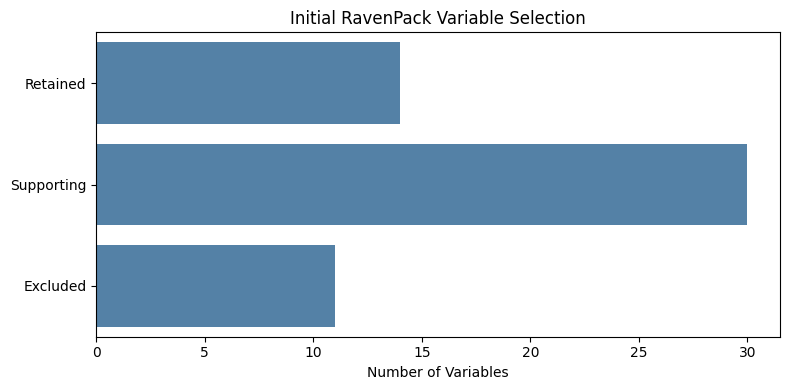

In [42]:
# 4.4.5 Visualize Column Selection

selection_summary = pd.DataFrame({
    "Variable Group": [
        "Retained",
        "Supporting",
        "Excluded"
    ],
    "Number of Variables": [
        len(retained_columns),
        len(supporting_columns),
        len(excluded_columns)
    ]
})

display(selection_summary)

plt.figure(figsize=(8, 4))

sns.barplot(
    data=selection_summary,
    x="Number of Variables",
    y="Variable Group",
    color="steelblue"
)

plt.title("Initial RavenPack Variable Selection")
plt.xlabel("Number of Variables")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 4.4.6 Interpretation of Results

Following the redundancy and structural analysis,
the 55 original RavenPack variables were divided
into three groups.

A total of 14 variables were selected as core
variables, 30 were classified as supporting
variables, and 11 were provisionally excluded
from the initial processed dataset.

The selection was based on missing values,
redundant information, constant variables,
identification requirements, and relevance to
the project's objective.

The original dataset remains unchanged, allowing
the variable selection to be modified if additional
information is required during model development.

## 5.0 Categorical News Mapping

RavenPack contains 1,007 distinct event categories,
providing a detailed classification of company news.

To maintain consistency with the machine learning
models, the original classifications will be mapped
to 22 broader event categories.

The mapping will preserve the original RavenPack
labels while creating standardized classifications
that can be understood, modified, and used by
all group members.

In [43]:
# 5.1 Define the Target News Categories

target_categories = [
    "earnings_beat",
    "earnings_miss",
    "revenue_beat",
    "revenue_miss",
    "earnings_guidance",
    "dividend_changes",
    "share_repurchases",
    "equity_issuance",
    "debt_issuance",
    "credit_rating_changes",
    "default_bankruptcy",
    "mergers_acquisitions",
    "asset_purchases_sales",
    "analyst_recommendation_changes",
    "analyst_price_target_changes",
    "management_changes",
    "insider_transactions",
    "lawsuits",
    "regulatory_actions",
    "product_launches",
    "product_recalls",
    "partnerships_contracts"
]

target_category_table = pd.DataFrame({
    "Target Category": target_categories
})

target_category_table.index += 1

display(target_category_table)

print("Total target categories:", len(target_categories))

,Target Category
1,earnings_beat
2,earnings_miss
3,revenue_beat
4,revenue_miss
5,earnings_guidance
6,dividend_changes
7,share_repurchases
8,equity_issuance
9,debt_issuance
10,credit_rating_changes


Total target categories: 22


In [44]:
# 5.2 Examine All RavenPack News Groups

group_summary = (
    taxonomy_dictionary
    .groupby("group")
    .agg(
        Unique_Categories=("category", "nunique"),
        Observations=("frequency", "sum")
    )
    .sort_values("Observations", ascending=False)
    .reset_index()
)

group_summary["Percentage (%)"] = (
    group_summary["Observations"] /
    group_summary["Observations"].sum() * 100
).round(4)

group_summary.index += 1

display(group_summary)

,group,Unique_Categories,Observations,Percentage (%)
1,stock-prices,7,5464425,19.0100
2,price-targets,8,4088888,14.2247
3,analyst-ratings,17,3927244,13.6624
4,earnings,122,3243088,11.2823
5,products-services,149,1888045,6.5683
6,revenues,53,1876277,6.5273
7,partnerships,8,1321471,4.5972
8,insider-trading,7,1111089,3.8653
9,equity-actions,111,912504,3.1745
10,marketing,9,890860,3.0992


In [45]:
# 5.3 Examine Event Types Within Each News Group

group_type_summary = (
    taxonomy_dictionary
    .groupby(["group", "type"])
    .agg(
        Unique_Categories=("category", "nunique"),
        Observations=("frequency", "sum")
    )
    .reset_index()
    .sort_values(
        ["group", "Observations"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

with pd.option_context("display.max_rows", None):
    display(group_type_summary)

,group,type,Unique_Categories,Observations
0,acquisitions-mergers,acquisition,23,340791
1,acquisitions-mergers,stake,8,133692
2,acquisitions-mergers,unit-acquisition,15,87123
3,acquisitions-mergers,acquisition-bid,10,60790
4,acquisitions-mergers,merger,14,26705
5,acquisitions-mergers,acquisition-regulation,8,16073
6,acquisitions-mergers,merger-regulation,3,1402
7,acquisitions-mergers,unit-acquisition-regulation,2,86
8,analyst-ratings,analyst-ratings-change,6,3608559
9,analyst-ratings,analyst-ratings-set,6,313035


### 5.4 Examine Detailed Event Classifications

Before constructing the categorical mapping, the
original event types, subtypes, and properties are
examined in greater detail.

Certain classifications require additional conditions
to ensure that the resulting variables accurately
represent the intended financial events.

For example, positive earnings do not necessarily
indicate that earnings exceeded expectations.
Similarly, a company issuing an analyst recommendation
should be distinguished from the company receiving it.

This analysis will help prevent incorrect event
classifications and preserve the economic meaning
of the original news information.

In [46]:
# 5.4.1 Earnings and Revenue Classifications

earnings_revenue_review = taxonomy_dictionary[
    taxonomy_dictionary["group"].isin([
        "earnings",
        "revenues"
    ])
][[
    "group",
    "type",
    "sub_type",
    "property",
    "category",
    "frequency"
]].sort_values(
    ["group", "type", "frequency"],
    ascending=[True, True, False]
)

with pd.option_context("display.max_rows", None):
    display(earnings_revenue_review)

,group,type,sub_type,property,category,frequency
6,earnings,earnings,<MISSING>,<MISSING>,earnings,948625
20,earnings,earnings,positive,<MISSING>,earnings-positive,323845
33,earnings,earnings,up,<MISSING>,earnings-up,145417
41,earnings,earnings,down,<MISSING>,earnings-down,109717
48,earnings,earnings,negative,<MISSING>,earnings-negative,98609
144,earnings,earnings,<MISSING>,<MISSING>,earnings-opinion,17913
460,earnings,earnings,unchanged,<MISSING>,earnings-unchanged,611
504,earnings,earnings,up,<MISSING>,earnings-up-opinion,390
585,earnings,earnings,delayed,<MISSING>,earnings-delayed,210
618,earnings,earnings,early-release,<MISSING>,earnings-early-release,172


In [47]:
# 5.4.2 Analyst Ratings and Price Targets

analyst_review = taxonomy_dictionary[
    taxonomy_dictionary["group"].isin([
        "analyst-ratings",
        "price-targets"
    ])
][[
    "group",
    "type",
    "sub_type",
    "property",
    "category",
    "frequency"
]].sort_values(
    ["group", "frequency"],
    ascending=[True, False]
)

with pd.option_context("display.max_rows", None):
    display(analyst_review)

,group,type,sub_type,property,category,frequency
2,analyst-ratings,analyst-ratings-change,neutral,rater,analyst-ratings-change-neutral-rater,1908129
8,analyst-ratings,analyst-ratings-change,neutral,<MISSING>,analyst-ratings-change-neutral,642713
13,analyst-ratings,analyst-ratings-change,negative,rater,analyst-ratings-change-negative-rater,472298
15,analyst-ratings,analyst-ratings-change,positive,rater,analyst-ratings-change-positive-rater,415112
34,analyst-ratings,analyst-ratings-set,positive,rater,analyst-ratings-set-positive-rater,138652
51,analyst-ratings,analyst-ratings-set,neutral,rater,analyst-ratings-set-neutral-rater,96293
55,analyst-ratings,analyst-ratings-change,positive,<MISSING>,analyst-ratings-change-positive,85314
56,analyst-ratings,analyst-ratings-change,negative,<MISSING>,analyst-ratings-change-negative,84993
88,analyst-ratings,analyst-ratings-set,positive,<MISSING>,analyst-ratings-set-positive,36308
127,analyst-ratings,analyst-ratings-set,negative,rater,analyst-ratings-set-negative-rater,20796


In [48]:
# 5.4.3 Capital Structure and Dividend Events

capital_review = taxonomy_dictionary[
    taxonomy_dictionary["group"].isin([
        "equity-actions",
        "credit",
        "dividends",
        "bankruptcy"
    ])
][[
    "group",
    "type",
    "sub_type",
    "property",
    "category",
    "frequency"
]].sort_values(
    ["group", "type", "frequency"],
    ascending=[True, True, False]
)

with pd.option_context("display.max_rows", None):
    display(capital_review)

,group,type,sub_type,property,category,frequency
275,bankruptcy,bankruptcy,<MISSING>,<MISSING>,bankruptcy,3560
461,bankruptcy,bankruptcy,fears,<MISSING>,bankruptcy-fears,607
551,bankruptcy,bankruptcy,exit,<MISSING>,bankruptcy-exit,286
619,bankruptcy,bankruptcy,<MISSING>,<MISSING>,bankruptcy-opinion,172
714,bankruptcy,bankruptcy,exit,<MISSING>,bankruptcy-exit-opinion,80
867,bankruptcy,bankruptcy,fears,<MISSING>,bankruptcy-fears-opinion,16
391,bankruptcy,bankruptcy-unit,<MISSING>,<MISSING>,bankruptcy-unit,1190
224,credit,credit-extension,<MISSING>,recipient,credit-extension-recipient,6138
271,credit,credit-extension,<MISSING>,provider,credit-extension-provider,3698
202,credit,debt,reduction,<MISSING>,debt-reduction,7810


In [49]:
# 5.4.4 Asset, Legal and Regulatory Events

event_review = taxonomy_dictionary[
    taxonomy_dictionary["group"].isin([
        "assets",
        "legal",
        "regulatory",
        "acquisitions-mergers"
    ])
][[
    "group",
    "type",
    "sub_type",
    "property",
    "category",
    "frequency"
]].sort_values(
    ["group", "type", "frequency"],
    ascending=[True, True, False]
)

with pd.option_context("display.max_rows", None):
    display(event_review)

,group,type,sub_type,property,category,frequency
27,acquisitions-mergers,acquisition,<MISSING>,acquirer,acquisition-acquirer,218594
79,acquisitions-mergers,acquisition,completed,acquirer,acquisition-completed-acquirer,47041
85,acquisitions-mergers,acquisition,<MISSING>,acquiree,acquisition-acquiree,36989
125,acquisitions-mergers,acquisition,<MISSING>,acquirer,acquisition-opinion-acquirer,21112
246,acquisitions-mergers,acquisition,approved,acquirer,acquisition-approved-acquirer,4745
285,acquisitions-mergers,acquisition,<MISSING>,acquiree,acquisition-opinion-acquiree,3222
286,acquisitions-mergers,acquisition,completed,acquiree,acquisition-completed-acquiree,3156
330,acquisitions-mergers,acquisition,rumor,acquirer,acquisition-rumor-acquirer,2009
342,acquisitions-mergers,acquisition,failed,acquirer,acquisition-failed-acquirer,1819
479,acquisitions-mergers,acquisition,termination-fee,<MISSING>,acquisition-merger-termination-fee,499


### 5.4.5 Interpretation of Results

The detailed classification analysis identified several
important distinctions within the original RavenPack
taxonomy.

Earnings and revenue surprises are distinguished from
ordinary increases and decreases in financial performance.
Analyst recommendations are also differentiated based on
the role of the company associated with the event.

These distinctions are considered when constructing the
standardized news categories to preserve the economic
meaning of the original classifications.

Events that do not correspond to the intended definitions
will remain unmapped rather than being assigned to an
inappropriate category.

### 5.5 Construct the Categorical Mapping

The original RavenPack classifications are mapped to
the 22 standardized event categories used in the
machine learning models.

The mapping is constructed using conditional rules
based on event groups, types, subtypes, and properties.

The original classifications are preserved to ensure
transparency and allow the mapping rules to be modified
by other group members.

In [50]:
# 5.5.1 Define Mapping Rules

def map_news_category(row):

    group = row["group"]
    event_type = row["type"]
    subtype = row["sub_type"]
    property_value = row["property"]
    category = row["category"]

    # Exclude third-party ratings and regulatory authorities
    if property_value in ["rater", "authority"]:
        return "unmapped"

    # 1–2. Earnings surprises
    if group == "earnings":

        if event_type.endswith("-expectations"):

            if "guidance" not in event_type:

                if subtype == "above-expectations":
                    return "earnings_beat"

                if subtype == "below-expectations":
                    return "earnings_miss"

    # 3–4. Revenue surprises
    if group == "revenues" and event_type == "revenue":

        if subtype == "above-expectations":
            return "revenue_beat"

        if subtype == "below-expectations":
            return "revenue_miss"

    # 5. Earnings guidance
    if group == "earnings" and "guidance" in event_type:
        return "earnings_guidance"

    # 6. Dividend changes
    if group == "dividends" and event_type == "dividend":

        if subtype in ["up", "down", "suspended"]:
            return "dividend_changes"

    # 7. Share repurchases
    if group == "equity-actions" and event_type == "buybacks":
        return "share_repurchases"

    # 8. Equity issuance
    if group == "equity-actions":

        if event_type in [
            "public-offering",
            "private-placement",
            "rights-issue"
        ]:
            return "equity_issuance"

    # 9. Debt issuance
    if group == "credit" and event_type == "note-sale":
        return "debt_issuance"

    # 10. Credit rating changes
    if group == "credit-ratings":

        if event_type == "credit-rating-change":
            return "credit_rating_changes"

    # 11. Default and bankruptcy
    if group == "bankruptcy":

        if event_type in ["bankruptcy", "bankruptcy-unit"]:

            if subtype == "<MISSING>" and "opinion" not in category:
                return "default_bankruptcy"

    # 12. Mergers and acquisitions
    if group == "acquisitions-mergers":

        if event_type in [
            "acquisition",
            "acquisition-bid",
            "merger",
            "unit-acquisition"
        ]:
            return "mergers_acquisitions"

    # 13. Asset purchases and sales
    if group == "assets":

        if event_type in ["asset", "facility"] and subtype == "sale":
            return "asset_purchases_sales"

        if event_type == "commodity-assets":

            if subtype in ["buy", "sell"]:
                return "asset_purchases_sales"

    # 14. Analyst recommendation changes
    if group == "analyst-ratings":

        if event_type == "analyst-ratings-change":
            return "analyst_recommendation_changes"

    # 15. Analyst price-target changes
    if group == "price-targets":

        if subtype in ["upgrade", "downgrade"]:
            return "analyst_price_target_changes"

    # 16. Management changes
    if group == "labor-issues":

        if event_type in [
            "executive-appointment",
            "executive-resignation",
            "executive-retirement",
            "executive-firing",
            "executive-death",
            "board-member-appointment",
            "board-member-resignation",
            "board-member-retirement",
            "board-member-firing",
            "board-member-death"
        ]:
            return "management_changes"

    # 17. Insider transactions
    if group == "insider-trading":

        if event_type in [
            "insider-buy",
            "insider-sell",
            "insider-surrender",
            "insider-gift"
        ]:
            return "insider_transactions"

    # 18. Lawsuits and litigation
    if group == "legal":

        if event_type in [
            "legal-issues",
            "antitrust-suit",
            "antitrust-settlement",
            "settlement",
            "verdict",
            "appeal",
            "patent-infringement",
            "copyright-infringement",
            "defamation",
            "discrimination"
        ]:
            return "lawsuits"

    if event_type == "insider-trading-lawsuit":
        return "lawsuits"

    # 19. Regulatory actions
    if group == "regulatory":

        if event_type in [
            "regulatory-investigation",
            "exchange-noncompliance",
            "exchange-compliance"
        ]:
            return "regulatory_actions"

    if event_type in [
        "antitrust-investigation",
        "sanctions",
        "acquisition-regulation",
        "merger-regulation",
        "unit-acquisition-regulation",
        "regulatory-product-approval",
        "regulatory-product-warning"
    ]:
        return "regulatory_actions"

    # 20. Product launches
    if group == "products-services":

        if event_type == "product-release":
            return "product_launches"

    # 21. Product recalls
    if group == "products-services":

        if event_type == "product-recall":
            return "product_recalls"

    # 22. Partnerships and contracts
    if group == "partnerships":

        if event_type in ["partnership", "joint-venture"]:
            return "partnerships_contracts"

    if group == "products-services":

        if event_type in [
            "business-contract",
            "government-contract"
        ]:
            return "partnerships_contracts"

    # Events outside the selected categories
    return "unmapped"

In [51]:
# 5.5.2 Apply the Mapping

taxonomy_mapped = taxonomy_dictionary.copy()

taxonomy_mapped["model_category"] = (
    taxonomy_mapped.apply(
        map_news_category,
        axis=1
    )
)

display(taxonomy_mapped.head(30))

,topic,group,type,sub_type,property,category,frequency,model_category
0,business,stock-prices,stock-price,loss,<MISSING>,stock-loss,2844626,unmapped
1,business,stock-prices,stock-price,gain,<MISSING>,stock-gain,2513338,unmapped
2,business,analyst-ratings,analyst-ratings-change,neutral,rater,analyst-ratings-change-neutral-rater,1908129,unmapped
3,business,price-targets,price-target,upgrade,rater,price-target-upgrade-rater,1424058,unmapped
4,business,price-targets,price-target,downgrade,rater,price-target-downgrade-rater,1369647,unmapped
5,business,partnerships,partnership,<MISSING>,<MISSING>,partnership,1280416,partnerships_contracts
6,business,earnings,earnings,<MISSING>,<MISSING>,earnings,948625,unmapped
7,business,marketing,conference,<MISSING>,organizer,conference-organizer,801570,unmapped
8,business,analyst-ratings,analyst-ratings-change,neutral,<MISSING>,analyst-ratings-change-neutral,642713,analyst_recommendation_changes
9,business,revenues,revenue,<MISSING>,<MISSING>,revenues,595205,unmapped


In [52]:
# 5.6.1 Mapping Frequency Summary

mapping_summary = (
    taxonomy_mapped
    .groupby("model_category")
    .agg(
        Original_Categories=("category", "nunique"),
        Observations=("frequency", "sum")
    )
    .sort_values("Observations", ascending=False)
    .reset_index()
)

mapping_summary["Percentage (%)"] = (
    mapping_summary["Observations"] /
    taxonomy_mapped["frequency"].sum() * 100
).round(4)

mapping_summary.index += 1

display(mapping_summary)

,model_category,Original_Categories,Observations,Percentage (%)
1,unmapped,736,21116190,73.4604
2,partnerships_contracts,23,1645522,5.7246
3,insider_transactions,5,866481,3.0144
4,analyst_recommendation_changes,3,813020,2.8284
5,analyst_price_target_changes,2,798196,2.7768
6,lawsuits,32,654703,2.2776
7,mergers_acquisitions,59,514989,1.7916
8,product_launches,4,511013,1.7777
9,management_changes,17,431666,1.5017
10,regulatory_actions,30,349455,1.2157


In [53]:
# 5.6.2 Mapping Coverage

mapped_mask = (
    taxonomy_mapped["model_category"] != "unmapped"
)

mapped_rows = taxonomy_mapped.loc[
    mapped_mask, "frequency"
].sum()

unmapped_rows = taxonomy_mapped.loc[
    ~mapped_mask, "frequency"
].sum()

classified_rows = taxonomy_mapped["frequency"].sum()

print("Original dataset observations:",
      f"{total_rows:,}")

print("Originally classified observations:",
      f"{classified_rows:,}")

print("Successfully mapped observations:",
      f"{mapped_rows:,}")

print("Unmapped classified observations:",
      f"{unmapped_rows:,}")

print("Originally unclassified observations:",
      f"{total_rows - classified_rows:,}")

print("Mapping coverage of classified events:",
      f"{mapped_rows / classified_rows * 100:.2f}%")

print("Mapping coverage of original dataset:",
      f"{mapped_rows / total_rows * 100:.2f}%")

print("Coverage validation:",
      mapped_rows + unmapped_rows == classified_rows)

Original dataset observations: 50,999,638
Originally classified observations: 28,744,999
Successfully mapped observations: 7,628,809
Unmapped classified observations: 21,116,190
Originally unclassified observations: 22,254,639
Mapping coverage of classified events: 26.54%
Mapping coverage of original dataset: 14.96%
Coverage validation: True


In [54]:
# 5.6.3 Validate Target Categories

observed_categories = set(
    taxonomy_mapped["model_category"]
) - {"unmapped"}

missing_categories = (
    set(target_categories) - observed_categories
)

unexpected_categories = (
    observed_categories - set(target_categories)
)

print("Expected model categories:",
      len(target_categories))

print("Successfully mapped model categories:",
      len(observed_categories))

print("Missing model categories:",
      missing_categories)

print("Unexpected model categories:",
      unexpected_categories)

print("Duplicate original categories:",
      taxonomy_mapped["category"].duplicated().sum())

Expected model categories: 22
Successfully mapped model categories: 22
Missing model categories: set()
Unexpected model categories: set()
Duplicate original categories: 0


In [55]:
# 5.6.4 Examine Unmapped Categories

unmapped_review = (
    taxonomy_mapped[
        taxonomy_mapped["model_category"] == "unmapped"
    ]
    .sort_values("frequency", ascending=False)
)

display(unmapped_review.head(50))

,topic,group,type,sub_type,property,category,frequency,model_category
0,business,stock-prices,stock-price,loss,<MISSING>,stock-loss,2844626,unmapped
1,business,stock-prices,stock-price,gain,<MISSING>,stock-gain,2513338,unmapped
2,business,analyst-ratings,analyst-ratings-change,neutral,rater,analyst-ratings-change-neutral-rater,1908129,unmapped
3,business,price-targets,price-target,upgrade,rater,price-target-upgrade-rater,1424058,unmapped
4,business,price-targets,price-target,downgrade,rater,price-target-downgrade-rater,1369647,unmapped
6,business,earnings,earnings,<MISSING>,<MISSING>,earnings,948625,unmapped
7,business,marketing,conference,<MISSING>,organizer,conference-organizer,801570,unmapped
9,business,revenues,revenue,<MISSING>,<MISSING>,revenues,595205,unmapped
12,business,revenues,revenue,up,<MISSING>,revenue-up,481790,unmapped
13,business,analyst-ratings,analyst-ratings-change,negative,rater,analyst-ratings-change-negative-rater,472298,unmapped


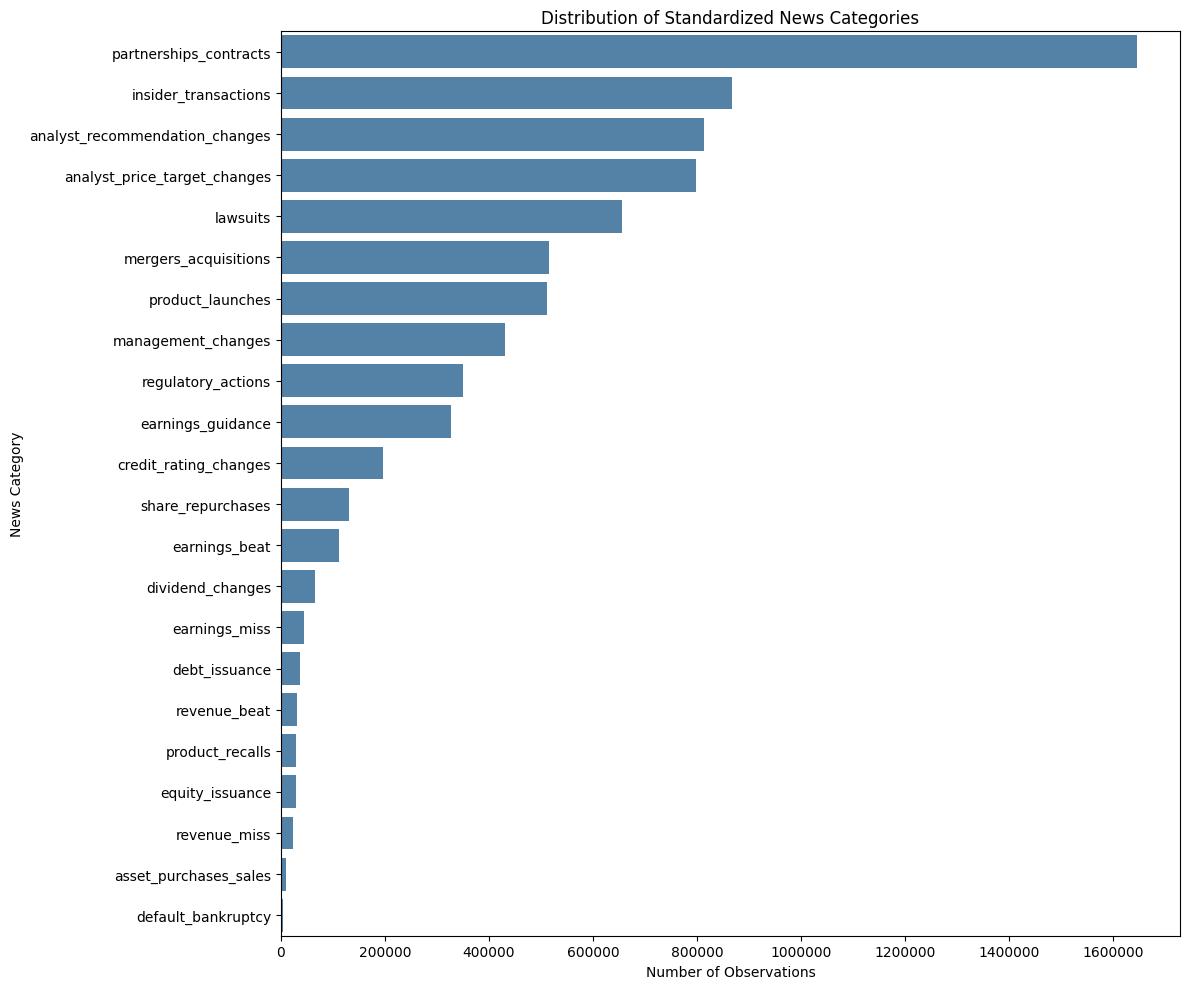

In [56]:
# 5.6.5 Visualize Standardized News Categories

plot_data = mapping_summary[
    mapping_summary["model_category"] != "unmapped"
]

plt.figure(figsize=(12, 10))

sns.barplot(
    data=plot_data,
    x="Observations",
    y="model_category",
    color="steelblue"
)

plt.title("Distribution of Standardized News Categories")
plt.xlabel("Number of Observations")
plt.ylabel("News Category")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()

### 5.6.6 Interpretation of Results

The categorical mapping successfully assigned 271
original RavenPack classifications to the 22 standardized
news categories used in the machine learning models.

A total of 7,628,809 observations were successfully
mapped, representing 26.54% of classified news
observations and 14.96% of the original dataset.

All 22 target categories were represented, with no
missing categories, unexpected categories, or duplicate
original classifications.

The distribution of observations varies considerably
across event categories. Partnerships and contracts
represent the most frequently observed category,
while default and bankruptcy represent the least
frequently observed category.

These differences in frequency will be considered
during model development and evaluation. However,
the frequency of a news event does not necessarily
determine its predictive importance.

In [57]:
# 5.7.1 Save the Mapping Dictionary

taxonomy_mapped.to_parquet(
    output_folder / "ravenpack_category_mapping.parquet",
    index=False
)

print("Category mapping saved successfully.")
print("Total original categories:", len(taxonomy_mapped))
print("Mapped categories:", mapped_mask.sum())
print("Unmapped categories:", (~mapped_mask).sum())

Category mapping saved successfully.
Total original categories: 1007
Mapped categories: 271
Unmapped categories: 736


In [58]:
# 5.7.2 Create a Reusable Python Mapping

news_category_mapping = (
    taxonomy_mapped
    .set_index("category")["model_category"]
    .to_dict()
)

print("Total mapping entries:", len(news_category_mapping))

print(
    "Example mapping:",
    news_category_mapping["earnings-above-expectations"]
)

Total mapping entries: 1007
Example mapping: earnings_beat


## 6.0 Correlation and Categorical Association Analysis

The relationships between RavenPack variables are
examined using statistical methods appropriate for
numerical and categorical data.

Pearson and Spearman correlations are used to examine
relationships between numerical variables, while
categorical association measures are used to examine
relationships between categorical variables.

### 6.1 Construct the Analysis Dataset

Due to the size of the original dataset, a reproducible
random sample of approximately 10% of mapped news
observations is constructed across the entire dataset.

The sample will be used for exploratory analysis
without requiring all original observations to be
loaded into memory simultaneously.

In [59]:
# 6.1.1 Define Analysis Variables

analysis_numeric = [
    "relevance",
    "event_sentiment_score",
    "event_relevance",
    "event_similarity_days",
    "css",
    "nip"
]

analysis_signals = [
    "peq",
    "bee",
    "bmq",
    "bam",
    "bca",
    "ber",
    "anl_chg",
    "mcq"
]

analysis_categorical = [
    "category",
    "fact_level",
    "news_type",
    "source_name",
    "earnings_type",
    "sub_type",
    "property"
]

analysis_identifiers = [
    "rp_entity_id",
    "cusip",
    "timestamp_utc",
    "rp_story_id",
    "rp_story_event_index",
    "event_similarity_key"
]

eda_columns = (
    analysis_numeric +
    analysis_signals +
    analysis_categorical +
    analysis_identifiers
)

print("Numerical variables:", len(analysis_numeric))
print("Discrete signals:", len(analysis_signals))
print("Categorical variables:", len(analysis_categorical))
print("Identifiers:", len(analysis_identifiers))
print("Total selected variables:", len(eda_columns))

Numerical variables: 6
Discrete signals: 8
Categorical variables: 7
Identifiers: 6
Total selected variables: 27


In [60]:
# 6.1.2 Construct a Random Sample Using Chunks

sample_fraction = 0.10
random_seed = 42

rng = np.random.default_rng(random_seed)

sample_chunks = []

rows_processed = 0
eligible_rows = 0
sampled_rows = 0

for i, chunk in enumerate(
    pd.read_csv(
        file_path,
        usecols=eda_columns,
        chunksize=100_000,
        dtype="string"
    ),
    start=1
):

    rows_processed += len(chunk)

    # Apply the standardized news classification
    chunk["model_category"] = (
        chunk["category"].map(news_category_mapping)
    )

    # Retain only successfully mapped categories
    eligible = chunk[
        chunk["model_category"].isin(target_categories)
    ].copy()

    eligible_rows += len(eligible)

    # Randomly select approximately 10% of eligible rows
    random_mask = (
        rng.random(len(eligible)) < sample_fraction
    )

    sampled = eligible.loc[random_mask].copy()

    sampled_rows += len(sampled)

    sample_chunks.append(sampled)

    if i % 50 == 0:
        print(
            f"Processed: {rows_processed:,} | "
            f"Eligible: {eligible_rows:,} | "
            f"Sampled: {sampled_rows:,}"
        )

eda_df = pd.concat(
    sample_chunks,
    ignore_index=True
)

del sample_chunks

print("\nSampling complete.")

print("Original observations processed:",
      f"{rows_processed:,}")

print("Eligible observations:",
      f"{eligible_rows:,}")

print("Sample observations:",
      f"{len(eda_df):,}")

print("Sample columns:",
      len(eda_df.columns))

print("Actual sampling percentage:",
      round(len(eda_df) / eligible_rows * 100, 4))

print("Mapping count matches:",
      eligible_rows == mapped_rows)

Processed: 5,000,000 | Eligible: 1,091,047 | Sampled: 108,777
Processed: 10,000,000 | Eligible: 2,403,830 | Sampled: 239,742
Processed: 15,000,000 | Eligible: 2,737,781 | Sampled: 273,147
Processed: 20,000,000 | Eligible: 3,086,507 | Sampled: 308,254
Processed: 25,000,000 | Eligible: 3,665,539 | Sampled: 366,344
Processed: 30,000,000 | Eligible: 4,507,230 | Sampled: 450,267
Processed: 35,000,000 | Eligible: 5,591,582 | Sampled: 558,653
Processed: 40,000,000 | Eligible: 6,281,991 | Sampled: 627,100
Processed: 45,000,000 | Eligible: 6,635,801 | Sampled: 662,703
Processed: 50,000,000 | Eligible: 7,441,722 | Sampled: 743,506

Sampling complete.
Original observations processed: 50,999,638
Eligible observations: 7,628,809
Sample observations: 762,174
Sample columns: 28
Actual sampling percentage: 9.9907
Mapping count matches: True


In [61]:
# 6.1.3 Assign Appropriate Data Types

# Numerical variables
for col in analysis_numeric:

    eda_df[col] = pd.to_numeric(
        eda_df[col],
        errors="coerce"
    )

# Categorical variables
for col in analysis_categorical + analysis_signals:

    eda_df[col] = eda_df[col].astype("category")

# Standardized news categories
eda_df["model_category"] = pd.Categorical(
    eda_df["model_category"],
    categories=target_categories
)

# Timestamp
eda_df["timestamp_utc"] = pd.to_datetime(
    eda_df["timestamp_utc"],
    format="mixed",
    errors="coerce",
    utc=True
)

display(eda_df.dtypes.to_frame("Data Type"))

,Data Type
cusip,string[python]
timestamp_utc,"datetime64[ns, UTC]"
rp_story_id,string[python]
rp_entity_id,string[python]
relevance,Int64
event_sentiment_score,Float64
event_relevance,Int64
event_similarity_key,string[python]
event_similarity_days,Float64
sub_type,category


In [62]:
# 6.1.4 Validate the Analysis Sample

sample_summary = pd.DataFrame({
    "Full Mapped Observations": (
        mapping_summary
        .set_index("model_category")["Observations"]
        .reindex(target_categories)
    ),

    "Sample Observations": (
        eda_df["model_category"]
        .value_counts()
        .reindex(target_categories, fill_value=0)
    )
})

sample_summary["Sampling Percentage (%)"] = (
    sample_summary["Sample Observations"] /
    sample_summary["Full Mapped Observations"] * 100
).round(2)

sample_summary["Full Distribution (%)"] = (
    sample_summary["Full Mapped Observations"] /
    mapped_rows * 100
).round(4)

sample_summary["Sample Distribution (%)"] = (
    sample_summary["Sample Observations"] /
    len(eda_df) * 100
).round(4)

display(sample_summary)

print(
    "Categories represented in sample:",
    eda_df["model_category"].nunique()
)

print(
    "Unique companies in sample:",
    eda_df["rp_entity_id"].nunique()
)

print(
    "Invalid timestamps:",
    eda_df["timestamp_utc"].isna().sum()
)

,Full Mapped Observations,Sample Observations,Sampling Percentage (%),Full Distribution (%),Sample Distribution (%)
model_category,,,,,
earnings_beat,112349,11143,9.92,1.4727,1.4620
earnings_miss,44471,4500,10.12,0.5829,0.5904
revenue_beat,31352,3104,9.90,0.4110,0.4073
revenue_miss,23904,2422,10.13,0.3133,0.3178
earnings_guidance,326417,32465,9.95,4.2787,4.2595
dividend_changes,66385,6641,10.00,0.8702,0.8713
share_repurchases,131372,13140,10.00,1.7221,1.7240
equity_issuance,28362,2815,9.93,0.3718,0.3693
debt_issuance,36701,3551,9.68,0.4811,0.4659


Categories represented in sample: 22
Unique companies in sample: 537
Invalid timestamps: 0


In [63]:
# 6.1.5 Save the Analysis Dataset

eda_df.to_parquet(
    output_folder / "ravenpack_eda_sample.parquet",
    index=False,
    compression="snappy"
)

print("Analysis dataset saved successfully.")
print("Observations:", f"{len(eda_df):,}")
print("Variables:", len(eda_df.columns))

Analysis dataset saved successfully.
Observations: 762,174
Variables: 28


### 6.1.6 Interpretation of Results

A reproducible random sample of 762,174 observations
was successfully constructed from the 7,628,809
mapped news observations.

The sample represents approximately 9.99% of the
mapped dataset and contains all 22 standardized
news categories and 537 RavenPack entities.

The distribution of news categories within the
sample closely resembles the distribution of the
full mapped dataset. No invalid timestamps were
identified.

The resulting dataset contains 28 variables and
will be used to examine numerical correlations,
categorical associations, and relationships
between news characteristics.

### 6.2 Numerical Descriptive Statistics

Descriptive statistics are calculated to examine
the distribution and variation of the numerical
news variables.

The analysis includes measures of central tendency,
dispersion, minimum and maximum values, and missing
observations.

These results will help identify unusual values
and provide context for the subsequent correlation
analysis.

In [64]:
# 6.2.1 Numerical Summary

numerical_summary = (
    eda_df[analysis_numeric]
    .describe()
    .T
)

numerical_summary["Missing"] = (
    eda_df[analysis_numeric].isna().sum()
)

numerical_summary["Missing (%)"] = (
    eda_df[analysis_numeric].isna().mean() * 100
)

numerical_summary["Unique Values"] = (
    eda_df[analysis_numeric].nunique()
)

display(numerical_summary.round(4))

,count,mean,std,min,25%,50%,75%,max,Missing,Missing (%),Unique Values
relevance,762174.0,99.4047,1.3135,90.0,99.0,100.0,100.0,100.0,0,0.0,11
event_sentiment_score,762174.0,0.1882,0.4831,-1.0,-0.46,0.48,0.52,1.0,0,0.0,142
event_relevance,762174.0,80.9004,25.2991,0.0,65.0,100.0,100.0,100.0,0,0.0,61
event_similarity_days,762174.0,62.1697,127.5066,0.0,0.0039,0.0518,18.4388,365.0,0,0.0,97206
css,762174.0,0.0099,0.0876,-0.92,0.0,0.0,0.04,1.0,0,0.0,30
nip,762174.0,-0.1392,0.2131,-0.82,-0.28,-0.18,-0.04,0.94,0,0.0,89


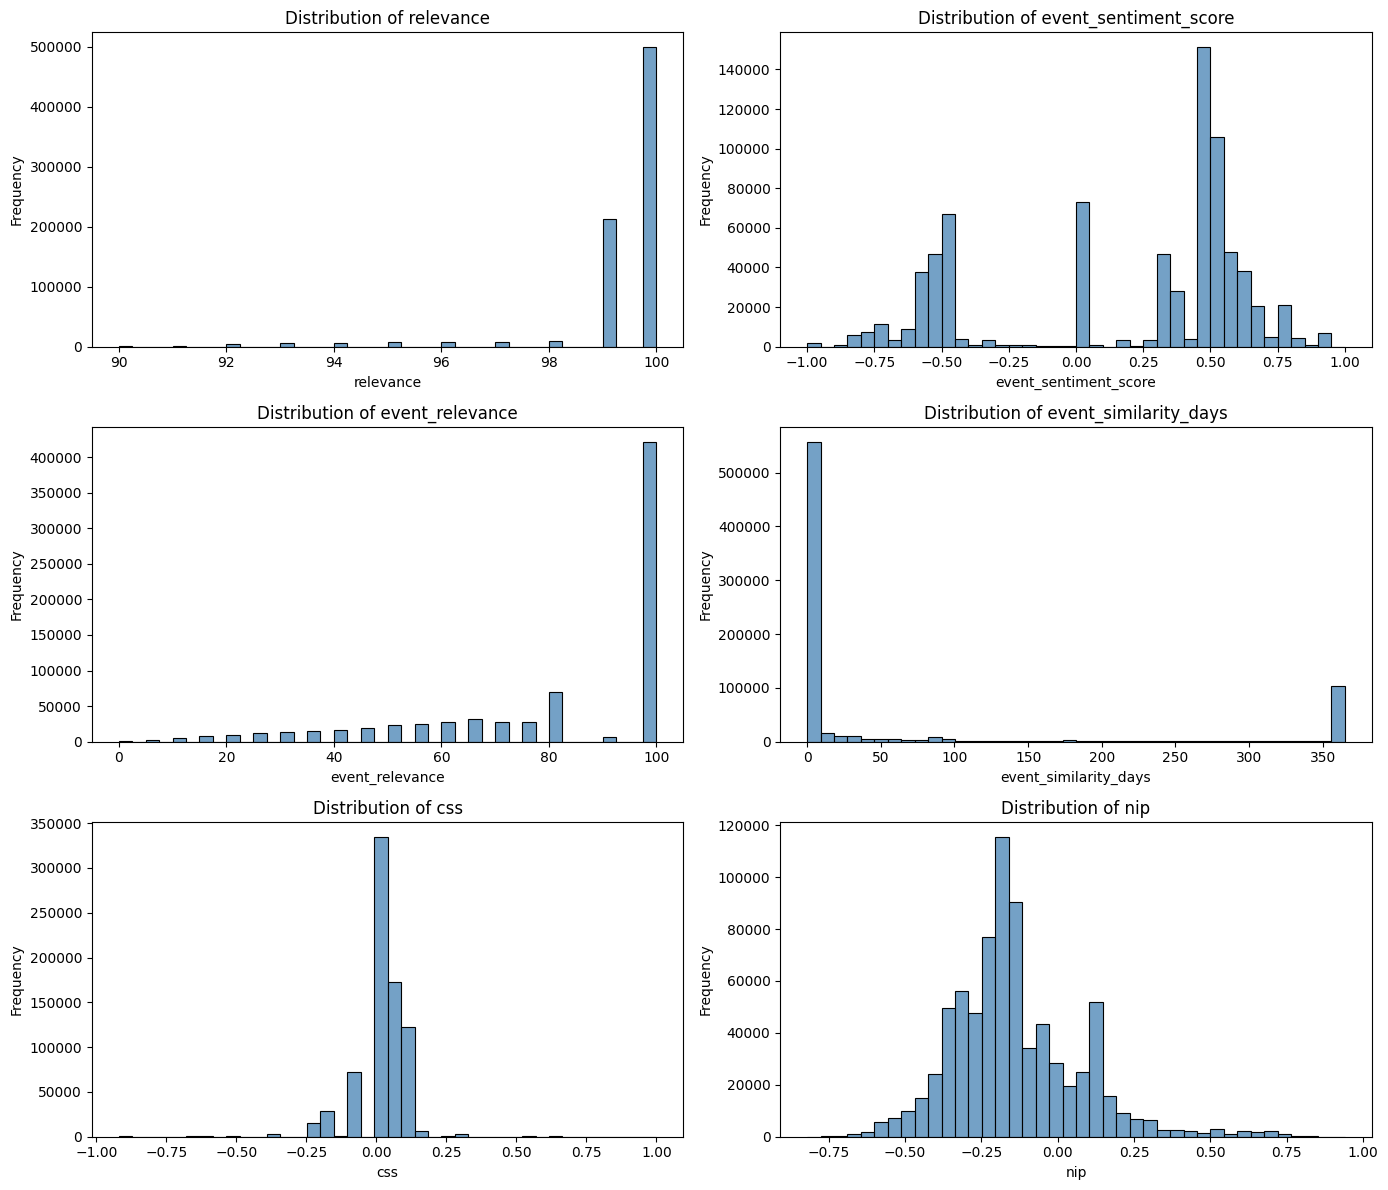

In [65]:
# 6.2.2 Numerical Variable Distributions

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 12)
)

axes = axes.flatten()

for ax, col in zip(axes, analysis_numeric):

    sns.histplot(
        data=eda_df,
        x=col,
        bins=40,
        color="steelblue",
        ax=ax
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [66]:
# 6.2.3 Discrete Signal Distributions

for col in analysis_signals:

    signal_summary = pd.DataFrame({
        "Frequency": eda_df[col].value_counts(
            dropna=False
        ),
        "Percentage (%)": (
            eda_df[col].value_counts(
                normalize=True,
                dropna=False
            ) * 100
        ).round(4)
    })

    print(f"\n{col.upper()}")
    display(signal_summary)


PEQ


,Frequency,Percentage (%)
peq,,
0,567378,74.4421
1,152939,20.0662
-1,41857,5.4918



BEE


,Frequency,Percentage (%)
bee,,
0,691742,90.7591
1,55868,7.3301
-1,14564,1.9108



BMQ


,Frequency,Percentage (%)
bmq,,
0,447253,58.6812
1,223924,29.3796
-1,90997,11.9391


... (6 outputs left out)


ANL_CHG


,Frequency,Percentage (%)
anl_chg,,
0,749086,98.2828
1,6889,0.9039
-1,6199,0.8133



MCQ


,Frequency,Percentage (%)
mcq,,
0,406994,53.3991
1,249022,32.6726
-1,106158,13.9283


### 6.3 Numerical Correlation Analysis

Pearson and Spearman correlation coefficients are
calculated to examine relationships between the
numerical news variables.

Pearson correlation measures linear relationships,
while Spearman correlation examines monotonic
relationships based on the ranking of observations.

The analysis will help identify variables containing
potentially overlapping information and provide
insight into the relationships between different
news characteristics.

In [67]:
# 6.3.1 Pearson Correlation Matrix

pearson_corr = (
    eda_df[analysis_numeric]
    .corr(method="pearson")
)

display(pearson_corr.round(4))

,relevance,event_sentiment_score,event_relevance,event_similarity_days,css,nip
relevance,1.0000,-0.0384,0.3419,0.0335,-0.0164,0.0624
event_sentiment_score,-0.0384,1.0000,-0.0623,0.0646,0.4299,-0.0199
event_relevance,0.3419,-0.0623,1.0000,0.0432,-0.0670,-0.0463
event_similarity_days,0.0335,0.0646,0.0432,1.0000,0.0103,-0.0081
css,-0.0164,0.4299,-0.0670,0.0103,1.0000,0.0286
nip,0.0624,-0.0199,-0.0463,-0.0081,0.0286,1.0000


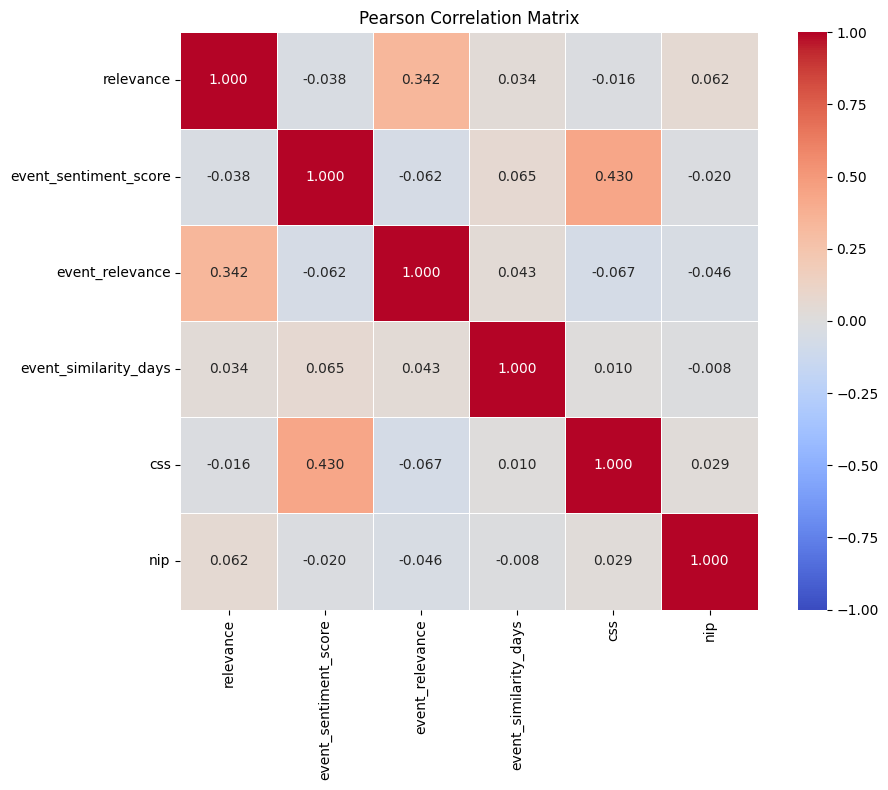

In [68]:
# 6.3.2 Pearson Correlation Heatmap

plt.figure(figsize=(10, 8))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

In [69]:
# 6.3.3 Spearman Correlation Matrix

spearman_corr = (
    eda_df[analysis_numeric]
    .corr(method="spearman")
)

display(spearman_corr.round(4))

,relevance,event_sentiment_score,event_relevance,event_similarity_days,css,nip
relevance,1.0000,-0.0440,0.7250,0.0390,-0.0048,0.0965
event_sentiment_score,-0.0440,1.0000,-0.0790,-0.0174,0.4306,0.0315
event_relevance,0.7250,-0.0790,1.0000,0.0248,-0.0548,0.0015
event_similarity_days,0.0390,-0.0174,0.0248,1.0000,-0.0323,0.0638
css,-0.0048,0.4306,-0.0548,-0.0323,1.0000,0.0778
nip,0.0965,0.0315,0.0015,0.0638,0.0778,1.0000


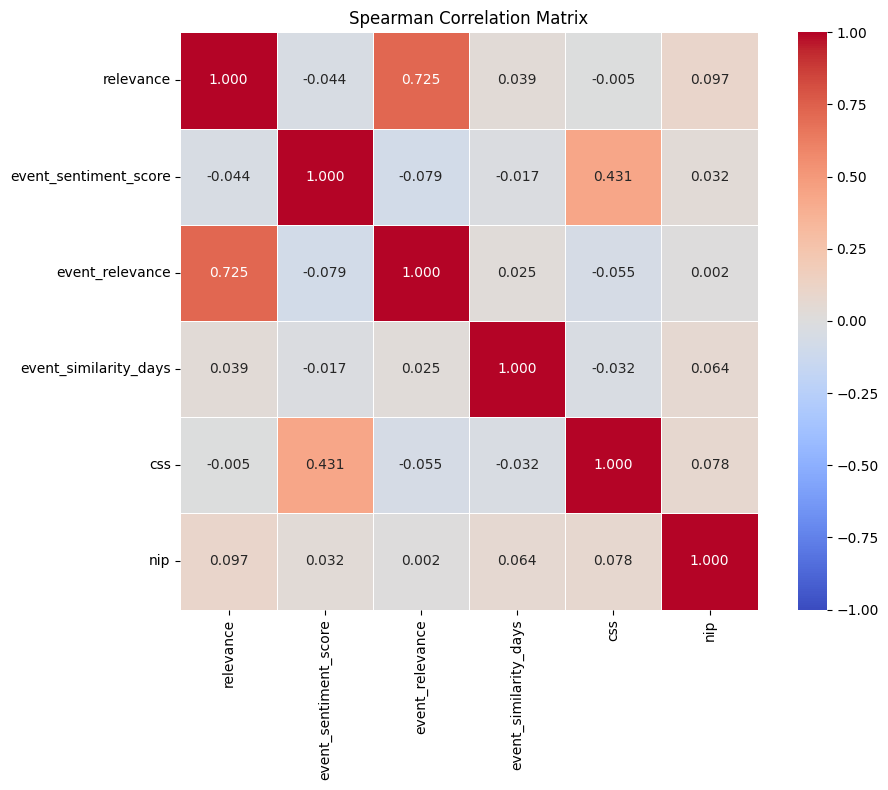

In [70]:
# 6.3.4 Spearman Correlation Heatmap

plt.figure(figsize=(10, 8))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

In [71]:
# 6.3.5 Identify the Strongest Numerical Relationships

from itertools import combinations

correlation_results = []

for col1, col2 in combinations(analysis_numeric, 2):

    correlation_results.append({

        "Variable 1": col1,

        "Variable 2": col2,

        "Pearson": pearson_corr.loc[col1, col2],

        "Spearman": spearman_corr.loc[col1, col2],

        "Valid Observations": (
            eda_df[[col1, col2]]
            .dropna()
            .shape[0]
        )

    })

correlation_summary = pd.DataFrame(
    correlation_results
)

correlation_summary["Absolute Pearson"] = (
    correlation_summary["Pearson"].abs()
)

correlation_summary["Absolute Spearman"] = (
    correlation_summary["Spearman"].abs()
)

correlation_summary = (
    correlation_summary
    .sort_values(
        "Absolute Pearson",
        ascending=False
    )
    .reset_index(drop=True)
)

display(correlation_summary.round(4))

,Variable 1,Variable 2,Pearson,Spearman,Valid Observations,Absolute Pearson,Absolute Spearman
0,event_sentiment_score,css,0.4299,0.4306,762174,0.4299,0.4306
1,relevance,event_relevance,0.3419,0.7250,762174,0.3419,0.7250
2,event_relevance,css,-0.0670,-0.0548,762174,0.0670,0.0548
3,event_sentiment_score,event_similarity_days,0.0646,-0.0174,762174,0.0646,0.0174
4,relevance,nip,0.0624,0.0965,762174,0.0624,0.0965
5,event_sentiment_score,event_relevance,-0.0623,-0.0790,762174,0.0623,0.0790
6,event_relevance,nip,-0.0463,0.0015,762174,0.0463,0.0015
7,event_relevance,event_similarity_days,0.0432,0.0248,762174,0.0432,0.0248
8,relevance,event_sentiment_score,-0.0384,-0.0440,762174,0.0384,0.0440
9,relevance,event_similarity_days,0.0335,0.0390,762174,0.0335,0.0390


In [72]:
# 6.3.6 Identify Potentially Redundant Numerical Variables

correlation_threshold = 0.80

high_correlation = correlation_summary[
    (
        correlation_summary["Absolute Pearson"]
        >= correlation_threshold
    ) |
    (
        correlation_summary["Absolute Spearman"]
        >= correlation_threshold
    )
]

display(high_correlation.round(4))

print(
    "Number of highly correlated variable pairs:",
    len(high_correlation)
)

,Variable 1,Variable 2,Pearson,Spearman,Valid Observations,Absolute Pearson,Absolute Spearman


Number of highly correlated variable pairs: 0


### 6.3.7 Interpretation of Numerical Results

The descriptive statistics identified considerable
differences in the distribution and variation of the
numerical news variables. No missing observations
were identified across the six numerical variables.

The relevance variable demonstrated limited variation,
while event relevance and event sentiment contained
greater variation across observations.

The discrete signal analysis also identified differences
in the frequency of nonzero observations. In particular,
BAM and ANL_CHG contained zero values in more than
98% of observations.

The Pearson and Spearman correlation analyses identified
no variable pairs exceeding the selected absolute
correlation threshold of 0.80.

The strongest Spearman correlation was observed between
relevance and event relevance at 0.7250. Event sentiment
and CSS also demonstrated a moderate positive relationship.

Based on these results, all six numerical variables
will remain available for further analysis. Predictive
importance will be evaluated after the news dataset
is merged with the financial return data.

### 6.4 Categorical Association Analysis

The RavenPack dataset contains several categorical
variables describing event classifications, news
sources, factual characteristics, and discrete
financial signals.

Cramer's V is used to measure the strength of
association between categorical variables.

A bias-corrected version of Cramer's V is applied
to account for differences in the number of
categories across variables.

The analysis will help identify potentially
overlapping categorical information and provide
insight into the relationships between different
news characteristics.

In [73]:
# 6.4.1 Define Categorical Analysis Variables

categorical_variables = [

    # Standardized event classification
    "model_category",

    # Original event characteristics
    "fact_level",
    "news_type",
    "source_name",
    "earnings_type",
    "sub_type",
    "property",

    # Discrete financial signals
    "peq",
    "bee",
    "bmq",
    "bam",
    "bca",
    "ber",
    "anl_chg",
    "mcq"
]

categorical_summary = pd.DataFrame({

    "Unique Values": (
        eda_df[categorical_variables].nunique()
    ),

    "Missing Observations": (
        eda_df[categorical_variables].isna().sum()
    ),

    "Missing (%)": (
        eda_df[categorical_variables].isna().mean() * 100
    ).round(4)

})

display(categorical_summary)

print(
    "Total categorical variables:",
    len(categorical_variables)
)

,Unique Values,Missing Observations,Missing (%)
model_category,22,0,0.0000
fact_level,3,0,0.0000
news_type,8,0,0.0000
source_name,20,0,0.0000
earnings_type,7,755443,99.1169
sub_type,48,510564,66.9879
property,9,639503,83.9051
peq,3,0,0.0000
bee,3,0,0.0000
bmq,3,0,0.0000


Total categorical variables: 15


In [74]:
# 6.4.2 Define the Cramer's V Function

from scipy.stats import chi2_contingency

def cramers_v(x, y):

    # Treat missing observations as a separate category
    x = x.astype("string").fillna("<MISSING>")
    y = y.astype("string").fillna("<MISSING>")

    # Construct contingency table
    contingency = pd.crosstab(x, y)

    # Chi-square statistic
    chi2 = chi2_contingency(
        contingency,
        correction=False
    )[0]

    # Number of observations
    n = contingency.to_numpy().sum()

    if n <= 1:
        return np.nan

    # Number of rows and columns
    r, k = contingency.shape

    phi2 = chi2 / n

    # Bias correction
    phi2_corrected = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corrected = (
        r - ((r - 1) ** 2) / (n - 1)
    )

    k_corrected = (
        k - ((k - 1) ** 2) / (n - 1)
    )

    denominator = min(
        k_corrected - 1,
        r_corrected - 1
    )

    if denominator <= 0:
        return np.nan

    return np.sqrt(
        phi2_corrected / denominator
    )

In [75]:
# 6.4.3 Calculate the Categorical Association Matrix

cramers_matrix = pd.DataFrame(

    np.nan,

    index=categorical_variables,

    columns=categorical_variables

)

# Set diagonal values
for col in categorical_variables:

    if eda_df[col].nunique(dropna=False) > 1:
        cramers_matrix.loc[col, col] = 1.0

# Calculate unique variable pairs
for col1, col2 in combinations(
    categorical_variables, 2
):

    association = cramers_v(
        eda_df[col1],
        eda_df[col2]
    )

    cramers_matrix.loc[col1, col2] = association

    cramers_matrix.loc[col2, col1] = association

display(cramers_matrix.round(4))

,model_category,fact_level,news_type,source_name,earnings_type,sub_type,property,peq,bee,bmq,bam,bca,ber,anl_chg,mcq
model_category,1.0000,0.7157,0.4669,0.1826,0.1565,0.5909,0.4737,0.3264,0.2452,0.3262,0.1282,0.3324,0.2842,0.2672,0.3278
fact_level,0.7157,1.0000,0.1058,0.0846,0.2908,0.3573,0.1567,0.0599,0.0396,0.0266,0.0261,0.0354,0.0714,0.0240,0.0219
news_type,0.4669,0.1058,1.0000,0.3105,0.0441,0.3232,0.1176,0.1594,0.1142,0.2135,0.0742,0.2031,0.1538,0.1342,0.2029
source_name,0.1826,0.0846,0.3105,1.0000,0.0249,0.1014,0.1648,0.1667,0.0991,0.1269,0.0394,0.1129,0.0927,0.0728,0.1331
earnings_type,0.1565,0.2908,0.0441,0.0249,1.0000,0.0407,0.0152,0.0187,0.0165,0.0177,0.0108,0.0181,0.0436,0.0083,0.0184
sub_type,0.5909,0.3573,0.3232,0.1014,0.0407,1.0000,0.2004,0.4365,0.3086,0.4222,0.1338,0.5514,0.2402,0.8629,0.4479
property,0.4737,0.1567,0.1176,0.1648,0.0152,0.2004,1.0000,0.1374,0.0519,0.0735,0.0357,0.0494,0.0841,0.0408,0.0663
peq,0.3264,0.0599,0.1594,0.1667,0.0187,0.4365,0.1374,1.0000,0.1091,0.1171,0.0369,0.1016,0.0694,0.2005,0.1304
bee,0.2452,0.0396,0.1142,0.0991,0.0165,0.3086,0.0519,0.1091,1.0000,0.2121,0.1146,0.2202,0.1249,0.2032,0.3457
bmq,0.3262,0.0266,0.2135,0.1269,0.0177,0.4222,0.0735,0.1171,0.2121,1.0000,0.1029,0.3894,0.1632,0.0755,0.8904


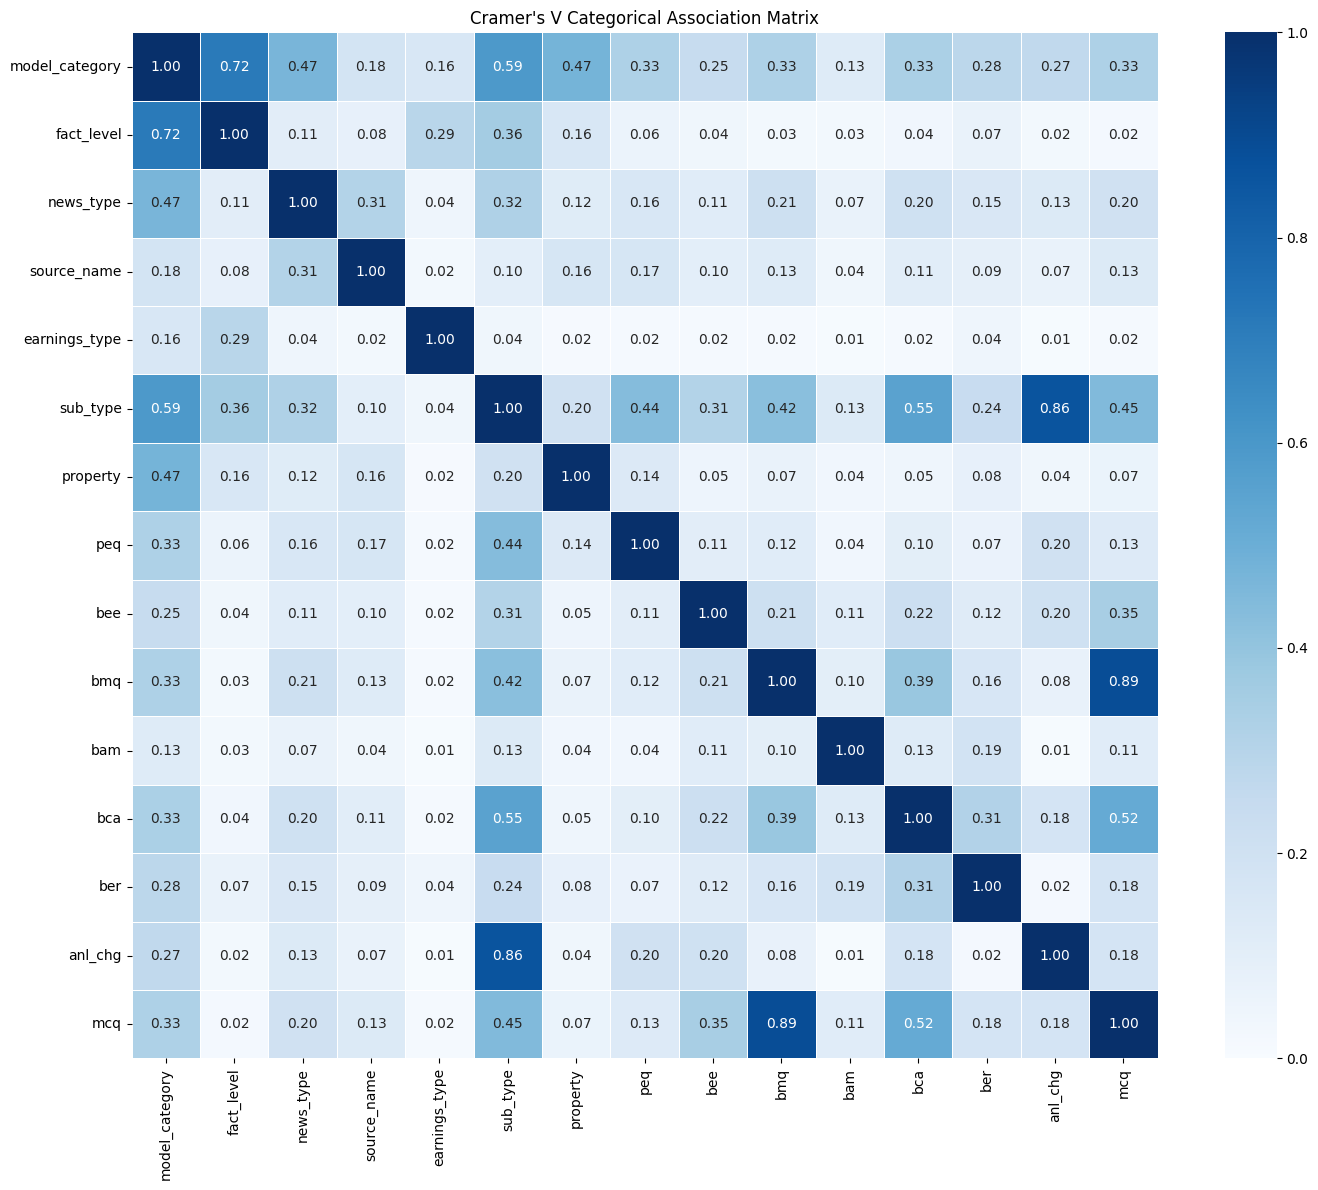

In [76]:
# 6.4.4 Visualize the Categorical Association Matrix

plt.figure(figsize=(15, 12))

sns.heatmap(

    cramers_matrix,

    annot=True,

    fmt=".2f",

    cmap="Blues",

    vmin=0,

    vmax=1,

    square=True,

    linewidths=0.5

)

plt.title("Cramer's V Categorical Association Matrix")

plt.tight_layout()

plt.show()

In [77]:
# 6.4.5 Identify the Strongest Categorical Relationships

categorical_results = []

for col1, col2 in combinations(
    categorical_variables, 2
):

    categorical_results.append({

        "Variable 1": col1,

        "Variable 2": col2,

        "Cramers V": (
            cramers_matrix.loc[col1, col2]
        )

    })

categorical_associations = (
    pd.DataFrame(categorical_results)
    .sort_values(
        "Cramers V",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    categorical_associations.head(25).round(4)
)

print(
    "Total categorical relationships:",
    len(categorical_associations)
)

,Variable 1,Variable 2,Cramers V
0,bmq,mcq,0.8904
1,sub_type,anl_chg,0.8629
2,model_category,fact_level,0.7157
3,model_category,sub_type,0.5909
4,sub_type,bca,0.5514
5,bca,mcq,0.5167
6,model_category,property,0.4737
7,model_category,news_type,0.4669
8,sub_type,mcq,0.4479
9,sub_type,peq,0.4365


Total categorical relationships: 105


In [78]:
# 6.4.6 Identify Potentially Redundant Categorical Variables

categorical_threshold = 0.70

high_categorical_association = (
    categorical_associations[
        categorical_associations["Cramers V"]
        >= categorical_threshold
    ]
)

display(
    high_categorical_association.round(4)
)

print(
    "Number of strongly associated variable pairs:",
    len(high_categorical_association)
)

,Variable 1,Variable 2,Cramers V
0,bmq,mcq,0.8904
1,sub_type,anl_chg,0.8629
2,model_category,fact_level,0.7157


Number of strongly associated variable pairs: 3


,Cramers V
fact_level,0.7157
sub_type,0.5909
property,0.4737
news_type,0.4669
bca,0.3324
mcq,0.3278
peq,0.3264
bmq,0.3262
ber,0.2842
anl_chg,0.2672


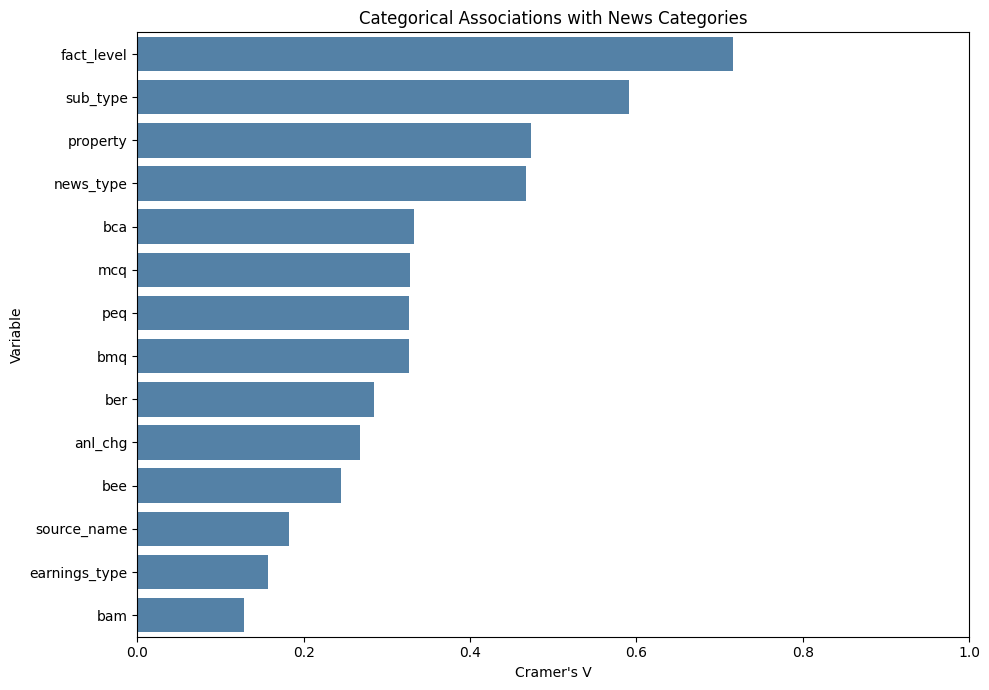

In [79]:
# 6.4.7 Associations With Standardized News Categories

category_associations = (

    cramers_matrix["model_category"]

    .drop("model_category")

    .sort_values(ascending=False)

    .to_frame("Cramers V")

)

display(category_associations.round(4))

plt.figure(figsize=(10, 7))

sns.barplot(

    x=category_associations["Cramers V"],

    y=category_associations.index,

    color="steelblue"

)

plt.title("Categorical Associations with News Categories")

plt.xlabel("Cramer's V")

plt.ylabel("Variable")

plt.xlim(0, 1)

plt.tight_layout()

plt.show()

### 6.4.8 Interpretation of Results

The categorical association analysis examined 105
unique relationships across 15 categorical variables.

Three variable pairs exceeded the selected Cramer's V
threshold of 0.70. The strongest association was
observed between BMQ and MCQ at 0.8904, followed
by sub_type and ANL_CHG at 0.8629.

A strong association was also identified between
the standardized news category and fact level
at 0.7157.

These findings suggest that certain categorical
variables may contain overlapping information.

However, strong categorical associations do not
necessarily indicate that two variables provide
identical information or have the same predictive
ability.

Additional analysis will be conducted before
determining whether any of these variables should
be excluded from the extended predictor set.
    

### 6.5 Sentiment Analysis by News Category

The distribution of event sentiment is examined
across the 22 standardized news categories.

Differences in sentiment across categories may
provide insight into the economic characteristics
of different company events.

The analysis also provides an additional validation
of the categorical mapping by examining whether
the observed sentiment distributions are consistent
with the intended financial meaning of each category.

In [80]:
# 6.5.1 Sentiment Descriptive Statistics by Category

sentiment_summary = (
    eda_df.groupby(
        "model_category",
        observed=True
    )["event_sentiment_score"]
    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .sort_values("mean", ascending=False)
)

sentiment_summary.columns = [
    "Observations",
    "Mean Sentiment",
    "Median Sentiment",
    "Standard Deviation",
    "Minimum",
    "Maximum"
]

display(sentiment_summary.round(4))

,Observations,Mean Sentiment,Median Sentiment,Standard Deviation,Minimum,Maximum
model_category,,,,,,
earnings_beat,11143,0.6907,0.7,0.0492,0.46,0.96
revenue_beat,3104,0.6421,0.72,0.1145,0.48,1.0
mergers_acquisitions,51774,0.5805,0.62,0.1506,-0.65,0.86
share_repurchases,13140,0.5764,0.59,0.1211,-0.5,0.84
product_launches,50964,0.5073,0.52,0.1375,-0.48,0.78
equity_issuance,2815,0.4763,0.59,0.2186,0.0,0.59
partnerships_contracts,163893,0.469,0.49,0.0954,-0.55,0.7
dividend_changes,6641,0.4053,0.52,0.3661,-0.8,1.0
analyst_recommendation_changes,81036,0.2019,0.34,0.3945,-0.98,0.94


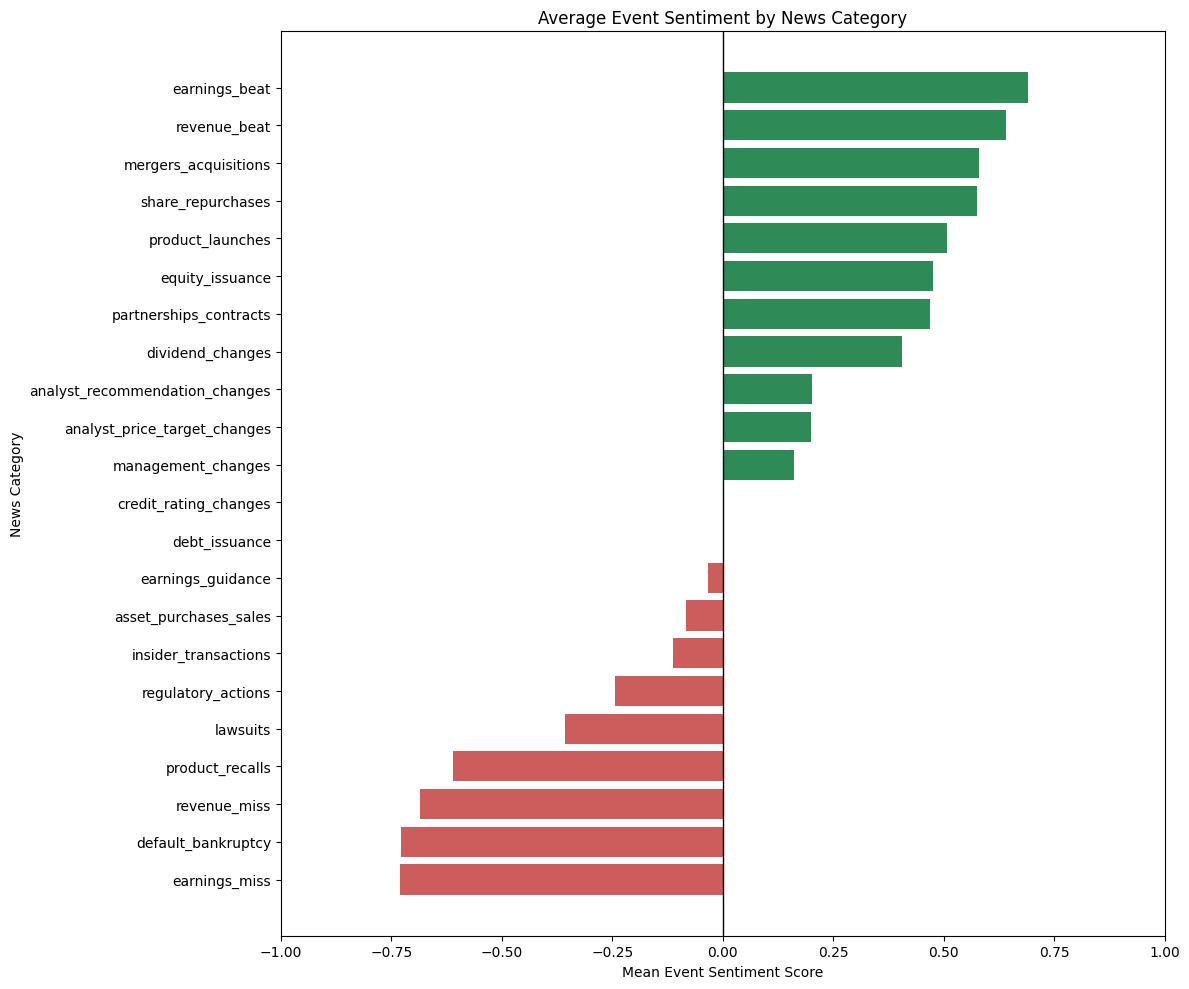

In [81]:
# 6.5.2 Visualize Average Sentiment by Category

plt.figure(figsize=(12, 10))

colors = [
    "seagreen" if value >= 0 else "indianred"
    for value in sentiment_summary["Mean Sentiment"]
]

plt.barh(
    sentiment_summary.index.astype(str),
    sentiment_summary["Mean Sentiment"],
    color=colors
)

plt.axvline(
    0,
    color="black",
    linewidth=1
)

plt.gca().invert_yaxis()

plt.title("Average Event Sentiment by News Category")
plt.xlabel("Mean Event Sentiment Score")
plt.ylabel("News Category")

plt.xlim(-1, 1)

plt.tight_layout()
plt.show()

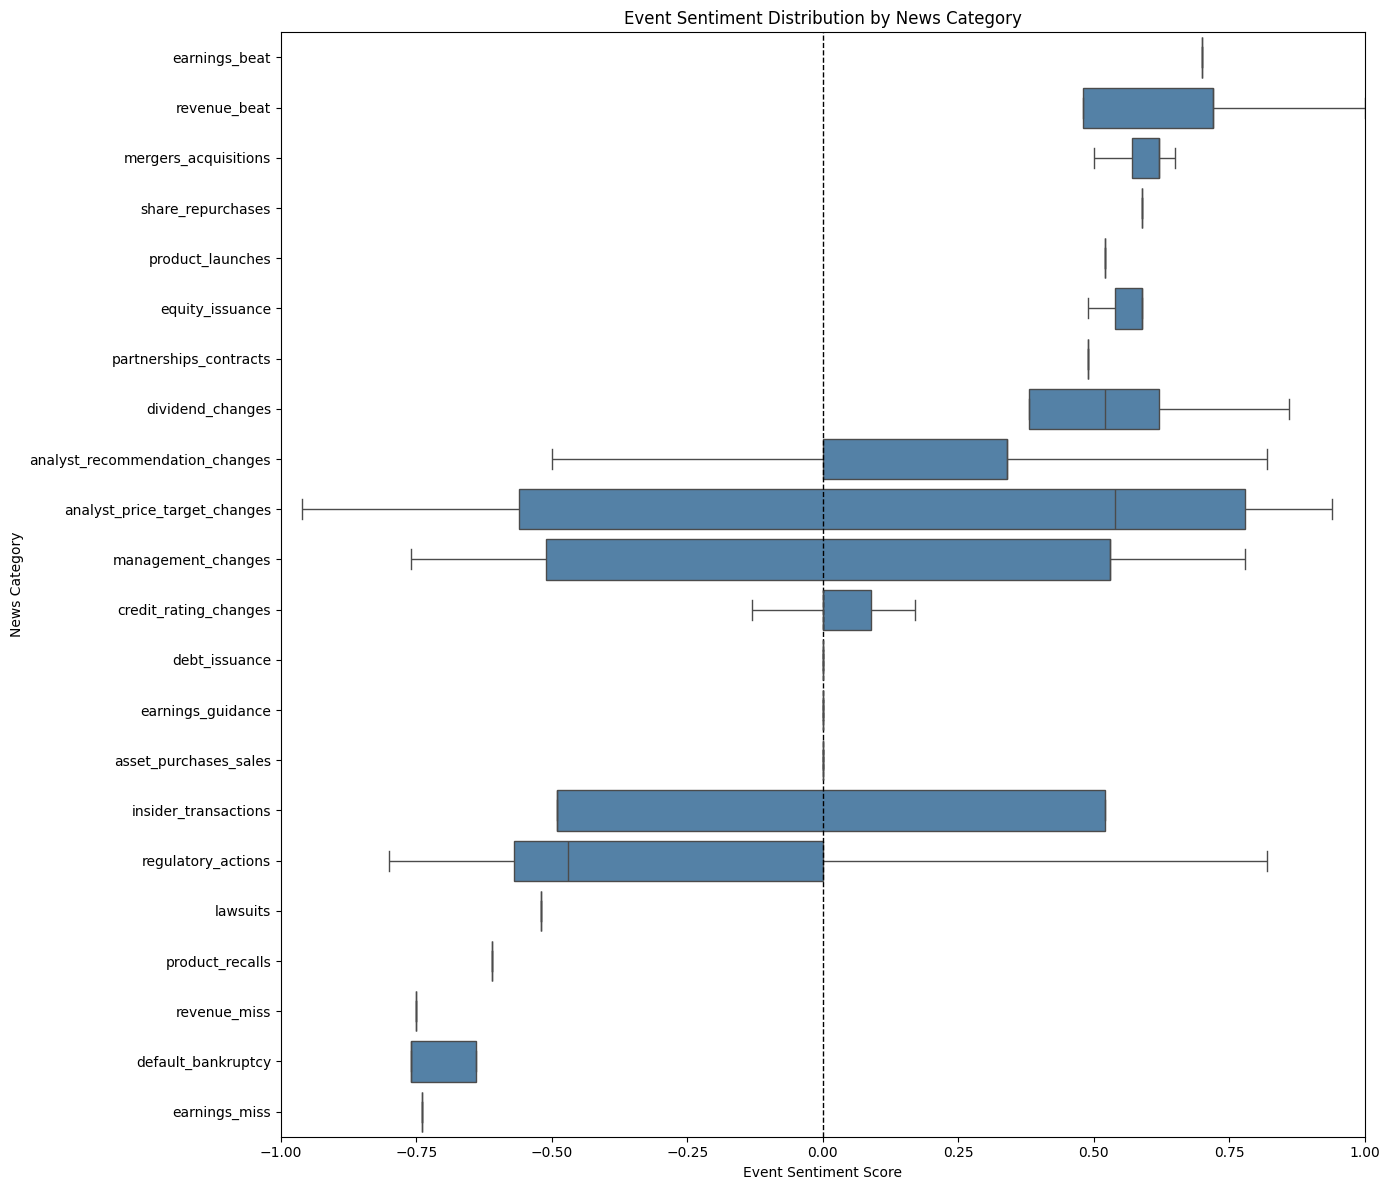

In [82]:
# 6.5.3 Examine Sentiment Distributions

plt.figure(figsize=(14, 12))

sns.boxplot(
    data=eda_df,
    x="event_sentiment_score",
    y="model_category",
    order=sentiment_summary.index.tolist(),
    color="steelblue",
    showfliers=False
)

plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("Event Sentiment Distribution by News Category")
plt.xlabel("Event Sentiment Score")
plt.ylabel("News Category")

plt.xlim(-1, 1)

plt.tight_layout()
plt.show()

In [83]:
# 6.5.4 Positive, Negative and Neutral Sentiment

eda_df["sentiment_direction"] = np.select(

    [
        eda_df["event_sentiment_score"] > 0,
        eda_df["event_sentiment_score"] < 0
    ],

    [
        "Positive",
        "Negative"
    ],

    default="Neutral"
)

sentiment_direction_counts = pd.crosstab(

    eda_df["model_category"],

    eda_df["sentiment_direction"]

)

sentiment_direction_summary = pd.crosstab(

    eda_df["model_category"],

    eda_df["sentiment_direction"],

    normalize="index"

) * 100

display(sentiment_direction_counts)

display(sentiment_direction_summary.round(4))

sentiment_direction,Negative,Neutral,Positive
model_category,,,
earnings_beat,0,0,11143
earnings_miss,4500,0,0
revenue_beat,0,0,3104
revenue_miss,2422,0,0
earnings_guidance,6123,22005,4337
dividend_changes,636,0,6005
share_repurchases,164,0,12976
equity_issuance,0,481,2334
debt_issuance,0,3551,0


sentiment_direction,Negative,Neutral,Positive
model_category,,,
earnings_beat,0.0000,0.0000,100.0000
earnings_miss,100.0000,0.0000,0.0000
revenue_beat,0.0000,0.0000,100.0000
revenue_miss,100.0000,0.0000,0.0000
earnings_guidance,18.8603,67.7807,13.3590
dividend_changes,9.5769,0.0000,90.4231
share_repurchases,1.2481,0.0000,98.7519
equity_issuance,0.0000,17.0870,82.9130
debt_issuance,0.0000,100.0000,0.0000


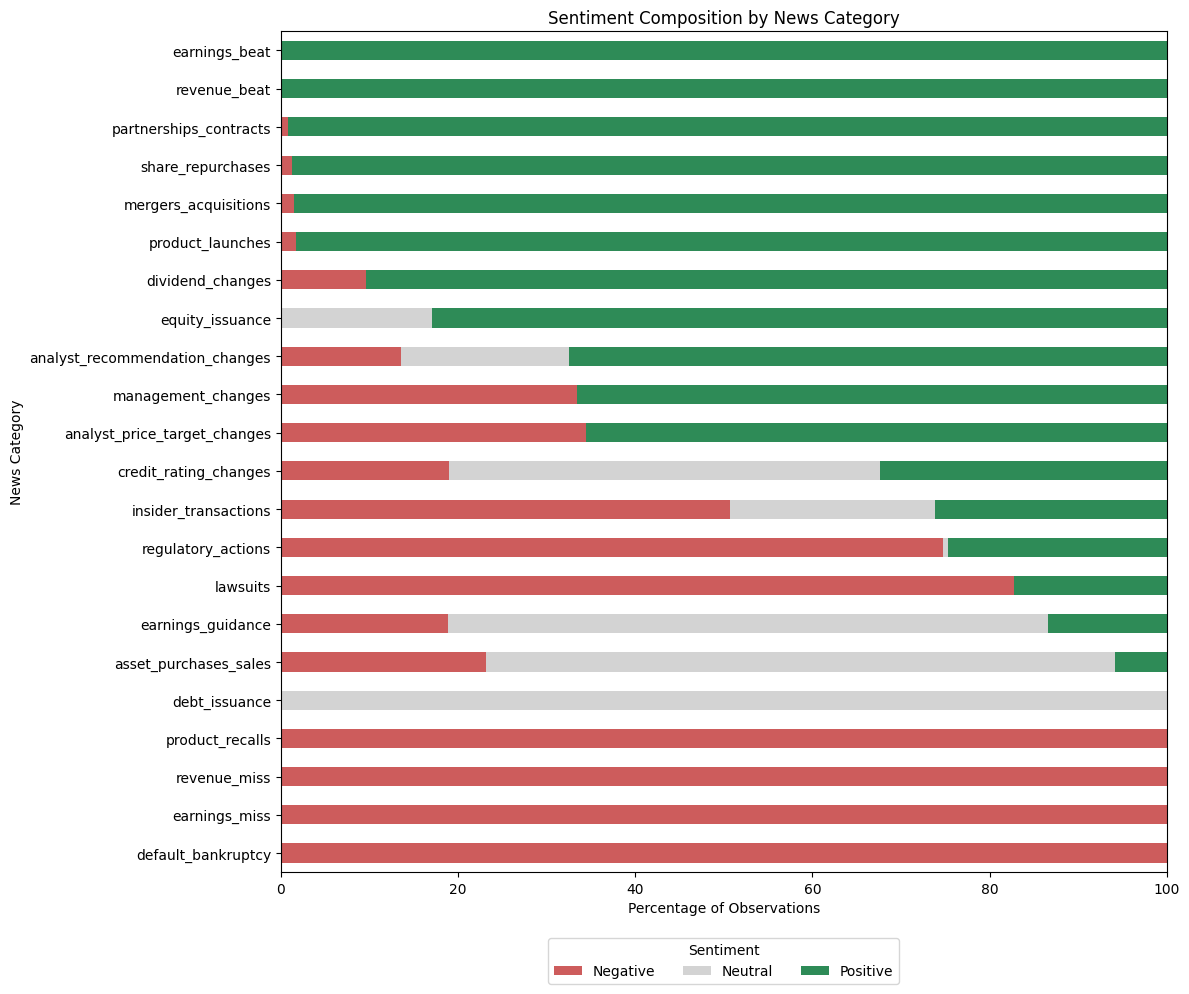

In [84]:
# 6.5.5 Visualize Sentiment Composition

sentiment_plot = (
    sentiment_direction_summary
    .reindex(
        columns=["Negative", "Neutral", "Positive"],
        fill_value=0
    )
    .sort_values("Positive", ascending=True)
)

sentiment_plot.plot(

    kind="barh",

    stacked=True,

    figsize=(12, 10),

    color=[
        "indianred",
        "lightgray",
        "seagreen"
    ]

)

plt.title("Sentiment Composition by News Category")
plt.xlabel("Percentage of Observations")
plt.ylabel("News Category")

plt.xlim(0, 100)

plt.legend(
    title="Sentiment",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.07),
    ncol=3
)

plt.tight_layout()
plt.show()

In [85]:
# 6.5.6 Examine Fact Level by News Category

fact_level_counts = pd.crosstab(

    eda_df["model_category"],

    eda_df["fact_level"]

)

fact_level_summary = pd.crosstab(

    eda_df["model_category"],

    eda_df["fact_level"],

    normalize="index"

) * 100

display(fact_level_counts)

display(fact_level_summary.round(4))

fact_level,fact,forecast,opinion
model_category,,,
earnings_beat,11143,0,0
earnings_miss,4500,0,0
revenue_beat,3104,0,0
revenue_miss,2422,0,0
earnings_guidance,0,31915,550
dividend_changes,6638,0,3
share_repurchases,13014,0,126
equity_issuance,2763,0,52
debt_issuance,3451,0,100


fact_level,fact,forecast,opinion
model_category,,,
earnings_beat,100.0000,0.0000,0.0000
earnings_miss,100.0000,0.0000,0.0000
revenue_beat,100.0000,0.0000,0.0000
revenue_miss,100.0000,0.0000,0.0000
earnings_guidance,0.0000,98.3059,1.6941
dividend_changes,99.9548,0.0000,0.0452
share_repurchases,99.0411,0.0000,0.9589
equity_issuance,98.1528,0.0000,1.8472
debt_issuance,97.1839,0.0000,2.8161


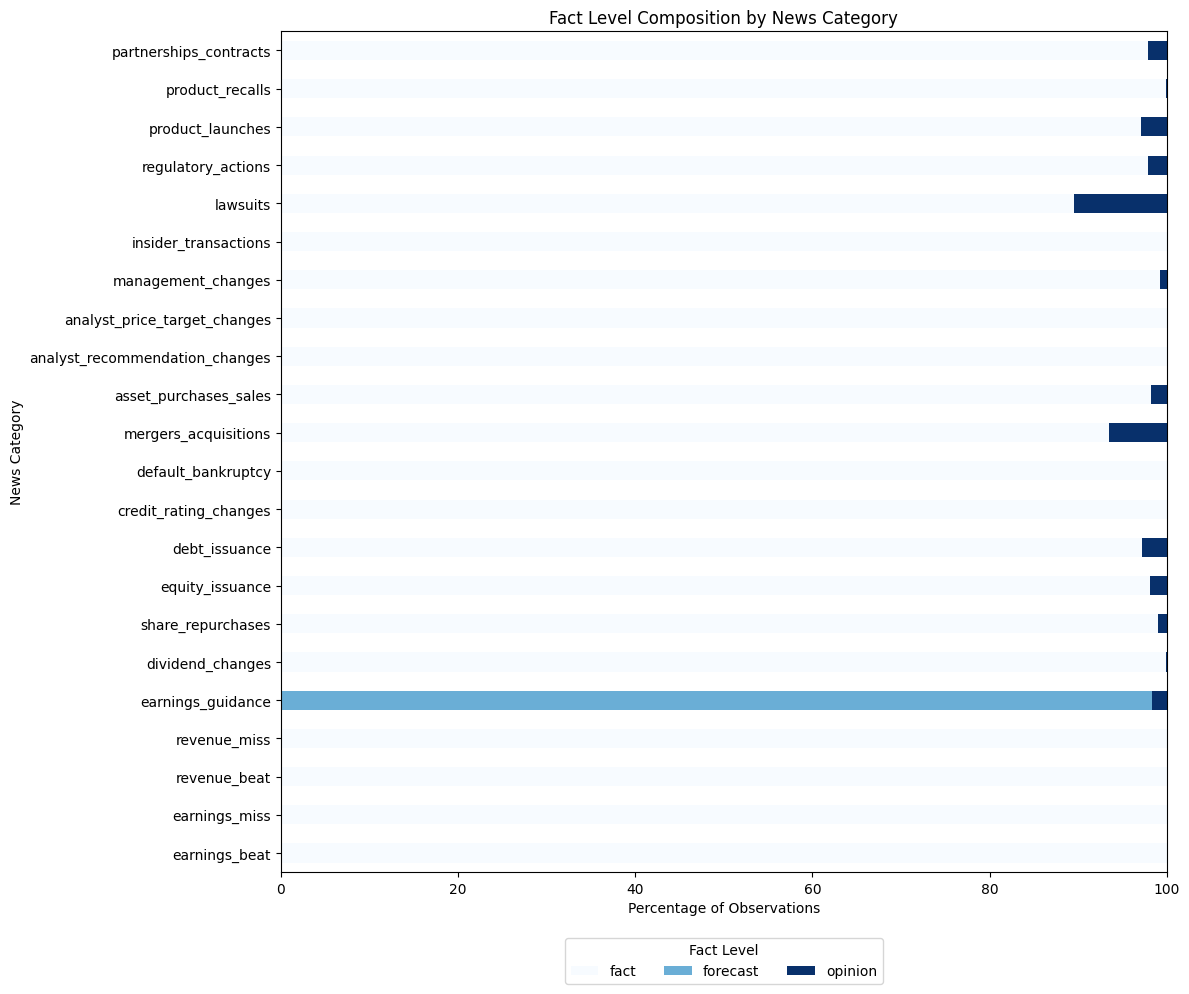

In [86]:
# 6.5.7 Visualize Fact Level Composition

fact_level_summary.plot(

    kind="barh",

    stacked=True,

    figsize=(12, 10),

    colormap="Blues"

)

plt.title("Fact Level Composition by News Category")
plt.xlabel("Percentage of Observations")
plt.ylabel("News Category")

plt.xlim(0, 100)

plt.legend(
    title="Fact Level",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.07),
    ncol=3
)

plt.tight_layout()
plt.show()

### 6.5.8 Interpretation of Sentiment Analysis

The sentiment analysis identified considerable
differences in the distribution of event sentiment
across the 22 standardized news categories.

Earnings and revenue beats demonstrated entirely
positive sentiment, while earnings and revenue
misses demonstrated entirely negative sentiment.

These findings are consistent with the intended
financial definitions of the standardized categories.

Analyst price-target changes, management changes,
and regulatory actions demonstrated substantial
variation in sentiment. These differences provide
a justification for examining interactions between
news categories and event sentiment.

Debt issuance was the only category containing
entirely neutral sentiment within the analysis
sample. This characteristic will be considered
when constructing and validating the sentiment
interaction variables.

The results describe the characteristics of the news
data rather than its ability to predict stock returns.

### 6.5.9 Interpretation of Fact Level

The fact-level composition analysis identified
differences in the distribution of facts, forecasts,
and opinions across standardized news categories.

Most news categories predominantly consist of factual
observations, while earnings guidance primarily
consists of forecasts.

These differences help explain the strong categorical
association previously identified between model
category and fact level.

The fact-level variable will remain available during
feature engineering to distinguish between different
characteristics of news reporting.

In [87]:
# 6.6.1 Compare BMQ and MCQ

bmq_mcq_counts = pd.crosstab(

    eda_df["bmq"],

    eda_df["mcq"]

)

bmq_mcq_percentages = pd.crosstab(

    eda_df["bmq"],

    eda_df["mcq"],

    normalize="index"

) * 100

display(bmq_mcq_counts)

display(bmq_mcq_percentages.round(4))

agreement = (
    eda_df["bmq"].astype("string") ==
    eda_df["mcq"].astype("string")
)

print(
    "Identical observations:",
    f"{agreement.sum():,}"
)

print(
    "Different observations:",
    f"{(~agreement).sum():,}"
)

print(
    "Agreement percentage:",
    f"{agreement.mean() * 100:.4f}%"
)

mcq,-1,0,1
bmq,,,
-1,88351,1759,887
0,17530,402420,27303
1,277,2815,220832


mcq,-1,0,1
bmq,,,
-1,97.0922,1.9330,0.9748
0,3.9195,89.9759,6.1046
1,0.1237,1.2571,98.6192


Identical observations: 711,603
Different observations: 50,571
Agreement percentage: 93.3649%


In [88]:
# 6.6.2 Examine ANL_CHG by Event Sub-type

anl_review = eda_df[
    eda_df["anl_chg"].astype("string") != "0"
].copy()

anl_review_summary = pd.crosstab(

    anl_review["sub_type"]
    .astype("string")
    .fillna("<MISSING>"),

    anl_review["anl_chg"]

)

anl_review_summary["Total"] = (
    anl_review_summary.sum(axis=1)
)

anl_review_summary = (
    anl_review_summary
    .sort_values("Total", ascending=False)
)

display(anl_review_summary)

print(
    "Nonzero ANL_CHG observations:",
    f"{len(anl_review):,}"
)

anl_chg,-1,1,Total
sub_type,,,
positive,0,6772,6772
negative,6154,0,6154
upgrade,11,74,85
<MISSING>,2,30,32
downgrade,25,4,29
above-expectations,3,9,12
down,2,0,2
suspended,2,0,2


Nonzero ANL_CHG observations: 13,088


In [89]:
# 6.6.3 Examine ANL_CHG by Standardized Category

anl_category_summary = (

    anl_review["model_category"]

    .value_counts()

    .to_frame("Nonzero Observations")

)

anl_category_summary["Percentage (%)"] = (

    anl_category_summary["Nonzero Observations"] /

    len(anl_review) * 100

).round(4)

display(anl_category_summary)

,Nonzero Observations,Percentage (%)
model_category,,
analyst_recommendation_changes,12926,98.7622
analyst_price_target_changes,98,0.7488
credit_rating_changes,16,0.1222
earnings_guidance,15,0.1146
product_launches,13,0.0993
earnings_beat,12,0.0917
management_changes,3,0.0229
insider_transactions,2,0.0153
dividend_changes,2,0.0153


### 6.6.4 Interpretation of Discrete Signal Redundancy

The comparison between BMQ and MCQ identified an
agreement percentage of 93.3649%, with 711,603
identical observations and 50,571 different observations.

These results confirm that the two variables contain
substantially overlapping information. However, the
variables are not completely redundant.

The ANL_CHG analysis identified 13,088 nonzero
observations. Approximately 98.76% of these observations
were associated with positive or negative event subtypes.

The direction of ANL_CHG was consistent with the
direction of these two event subtypes.

The discrete signals will remain available as supporting
variables for extended-model testing. Their predictive
importance will be evaluated after merging the news
observations with financial return data.

### 6.7 Conclusion of Exploratory Data Analysis

The exploratory data analysis examined the numerical
and categorical characteristics of the RavenPack
news dataset.

Pearson and Spearman correlation analyses identified
no numerical variable pairs exceeding the selected
absolute correlation threshold of 0.80.

The categorical association analysis identified three
variable pairs exceeding the selected Cramer's V
threshold of 0.70. Further investigation demonstrated
that some of these relationships resulted from
overlapping information and structural relationships
within the original news classifications.

The sentiment analysis identified considerable
differences across the 22 standardized news categories,
providing a justification for examining interactions
between event classifications and sentiment scores.

The baseline predictors will follow the original
modeling specification, while additional variables
will remain available for extended-model testing.

The exploratory analysis establishes a foundation
for feature engineering but does not independently
establish the ability of these variables to predict
future stock returns.

## 7.0 Feature Engineering

Following the exploratory data analysis, the
RavenPack news variables are transformed into
standardized machine learning predictors.

The baseline feature structure consists of
53 news predictors, including event category
indicators, numerical news characteristics,
fact-level indicators, novelty indicators,
and sentiment interaction variables.

Additional RavenPack variables are preserved
for potential extended-model testing.

The feature engineering process is initially
validated using the analysis sample before
being applied to the full mapped dataset.

In [90]:
# 7.1.1 Define Feature Groups

# News category indicators
category_features = target_categories.copy()

# Numerical news predictors
numerical_features = [
    "relevance",
    "event_sentiment_score",
    "event_relevance",
    "event_similarity_days"
]

# Fact-level indicators
fact_features = [
    "is_fact",
    "is_forecast",
    "is_opinion"
]

# Novelty indicators
novelty_features = [
    "novel_1day",
    "novel_7days"
]

# Category-specific sentiment interactions
interaction_features = [
    f"{category}_sentiment"
    for category in target_categories
]

# Complete baseline feature list
baseline_news_features = (
    category_features +
    numerical_features +
    fact_features +
    novelty_features +
    interaction_features
)

feature_structure = pd.DataFrame({
    "Feature Group": [
        "News Category Indicators",
        "Numerical News Predictors",
        "Fact-Level Indicators",
        "Novelty Indicators",
        "Sentiment Interactions"
    ],

    "Number of Predictors": [
        len(category_features),
        len(numerical_features),
        len(fact_features),
        len(novelty_features),
        len(interaction_features)
    ]
})

display(feature_structure)

print(
    "Total baseline news predictors:",
    len(baseline_news_features)
)

print(
    "Duplicate feature names:",
    len(baseline_news_features) -
    len(set(baseline_news_features))
)

,Feature Group,Number of Predictors
0,News Category Indicators,22
1,Numerical News Predictors,4
2,Fact-Level Indicators,3
3,Novelty Indicators,2
4,Sentiment Interactions,22


Total baseline news predictors: 53
Duplicate feature names: 0


### 7.2 Construct News Category Indicators

The 22 standardized news categories are transformed
into binary indicator variables using one-hot encoding.

Each indicator equals one when an observation belongs
to the corresponding news category and zero otherwise.

This transformation allows the categorical news
information to be incorporated into the machine
learning models.

In [91]:
# 7.2.1 Create Feature Engineering Dataset

feature_df = eda_df.copy()

print("Observations:", f"{len(feature_df):,}")
print("Initial variables:", len(feature_df.columns))

Observations: 762,174
Initial variables: 29


In [92]:
# 7.2.2 Create Category Indicators

for category in target_categories:

    feature_df[category] = (
        feature_df["model_category"] == category
    ).astype("int8")

display(
    feature_df[
        ["model_category"] + category_features
    ].head(10)
)

print(
    "Category indicators created:",
    len(category_features)
)

,model_category,earnings_beat,earnings_miss,revenue_beat,revenue_miss,earnings_guidance,dividend_changes,share_repurchases,equity_issuance,debt_issuance,credit_rating_changes,default_bankruptcy,mergers_acquisitions,asset_purchases_sales,analyst_recommendation_changes,analyst_price_target_changes,management_changes,insider_transactions,lawsuits,regulatory_actions,product_launches,product_recalls,partnerships_contracts
0,management_changes,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
1,partnerships_contracts,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,analyst_recommendation_changes,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
3,earnings_guidance,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,management_changes,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
5,earnings_guidance,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
6,partnerships_contracts,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
7,partnerships_contracts,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
8,earnings_guidance,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,analyst_recommendation_changes,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0


Category indicators created: 22


In [93]:
# 7.2.3 Validate Category Indicators

category_indicator_sum = (
    feature_df[category_features].sum(axis=1)
)

print(
    "Observations with exactly one category:",
    f"{(category_indicator_sum == 1).sum():,}"
)

print(
    "Observations with no category:",
    f"{(category_indicator_sum == 0).sum():,}"
)

print(
    "Observations with multiple categories:",
    f"{(category_indicator_sum > 1).sum():,}"
)

print(
    "Category indicator validation:",
    (category_indicator_sum == 1).all()
)

Observations with exactly one category: 762,174
Observations with no category: 0
Observations with multiple categories: 0
Category indicator validation: True


### 7.3 Construct Fact-Level Indicators

The RavenPack fact-level variable is transformed
into three binary indicators representing factual
news, forecasts, and opinions.

These variables allow the machine learning models
to distinguish between different characteristics
of news reporting.

In [95]:
# 7.3.1 Create Fact-Level Indicators

print("Original fact-level classifications:")

display(
    feature_df["fact_level"].value_counts()
)

fact_level_mapping = {
    "fact": "is_fact",
    "forecast": "is_forecast",
    "opinion": "is_opinion"
}

for original_value, feature_name in fact_level_mapping.items():

    feature_df[feature_name] = (
        feature_df["fact_level"]
        .astype("string")
        .str.lower()
        == original_value
    ).fillna(False).astype("int8")

display(
    feature_df[
        ["fact_level"] + fact_features
    ].head(10)
)

Original fact-level classifications:


fact_level
fact        713069
forecast     31915
opinion      17190
Name: count, dtype: int64

,fact_level,is_fact,is_forecast,is_opinion
0,fact,1,0,0
1,fact,1,0,0
2,fact,1,0,0
3,forecast,0,1,0
4,fact,1,0,0
5,forecast,0,1,0
6,fact,1,0,0
7,fact,1,0,0
8,forecast,0,1,0
9,fact,1,0,0


In [96]:
# 7.3.2 Validate Fact-Level Indicators

fact_indicator_sum = (
    feature_df[fact_features].sum(axis=1)
)

fact_validation = pd.DataFrame({
    "Observations": feature_df[fact_features].sum(),

    "Percentage (%)": (
        feature_df[fact_features].mean() * 100
    ).round(4)
})

display(fact_validation)

print(
    "Observations with exactly one fact level:",
    f"{(fact_indicator_sum == 1).sum():,}"
)

print(
    "Invalid fact-level encodings:",
    f"{(fact_indicator_sum != 1).sum():,}"
)

print(
    "Fact-level validation:",
    (fact_indicator_sum == 1).all()
)

,Observations,Percentage (%)
is_fact,713069,93.5572
is_forecast,31915,4.1874
is_opinion,17190,2.2554


Observations with exactly one fact level: 762,174
Invalid fact-level encodings: 0
Fact-level validation: True


### 7.4 Construct Novelty Indicators

The event similarity days variable measures the
time elapsed since a similar news event was
previously detected.

Two binary novelty indicators are constructed
using thresholds of one day and seven days.

The indicators distinguish relatively novel news
events from events that have been reported within
shorter periods.

The original continuous event similarity variable
is also retained to preserve additional information
about the timing of similar news events.

In [97]:
# 7.4.1 Create Novelty Indicators

novelty_thresholds = {
    "novel_1day": 1,
    "novel_7days": 7
}

# Validate underlying similarity values
assert feature_df["event_similarity_days"].notna().all()

assert feature_df["event_similarity_days"].between(
    0, 365
).all()

for feature_name, threshold in novelty_thresholds.items():

    feature_df[feature_name] = (
        feature_df["event_similarity_days"] >= threshold
    ).astype("int8")

display(
    feature_df[
        ["event_similarity_days"] + novelty_features
    ].head(15)
)

,event_similarity_days,novel_1day,novel_7days
0,0.0,0,0
1,14.51025,1,1
2,0.00688,0,0
3,365.0,1,1
4,0.0,0,0
5,365.0,1,1
6,0.0,0,0
7,0.00109,0,0
8,52.80828,1,1
9,0.00689,0,0


In [98]:
# 7.4.2 Validate Novelty Indicators

novelty_feature_summary = pd.DataFrame({

    "Non-Novel Observations": (
        feature_df[novelty_features] == 0
    ).sum(),

    "Novel Observations": (
        feature_df[novelty_features] == 1
    ).sum(),

    "Novel Percentage (%)": (
        feature_df[novelty_features].mean() * 100
    ).round(4)

})

display(novelty_feature_summary)

invalid_novelty = (
    feature_df["novel_7days"] >
    feature_df["novel_1day"]
).sum()

print(
    "Inconsistent novelty indicators:",
    invalid_novelty
)

print(
    "Novelty validation:",
    invalid_novelty == 0
)

,Non-Novel Observations,Novel Observations,Novel Percentage (%)
novel_1day,495081,267093,35.0436
novel_7days,548127,214047,28.0837


Inconsistent novelty indicators: 0
Novelty validation: True


,novel_1day,novel_7days
model_category,,
dividend_changes,70.6068,68.1072
insider_transactions,66.0248,50.1003
revenue_beat,55.6701,51.9652
credit_rating_changes,55.4455,51.1856
earnings_guidance,55.0531,52.0407
asset_purchases_sales,45.3309,42.2484
equity_issuance,45.1865,41.6696
share_repurchases,45.1674,33.5997
mergers_acquisitions,39.6531,33.6443


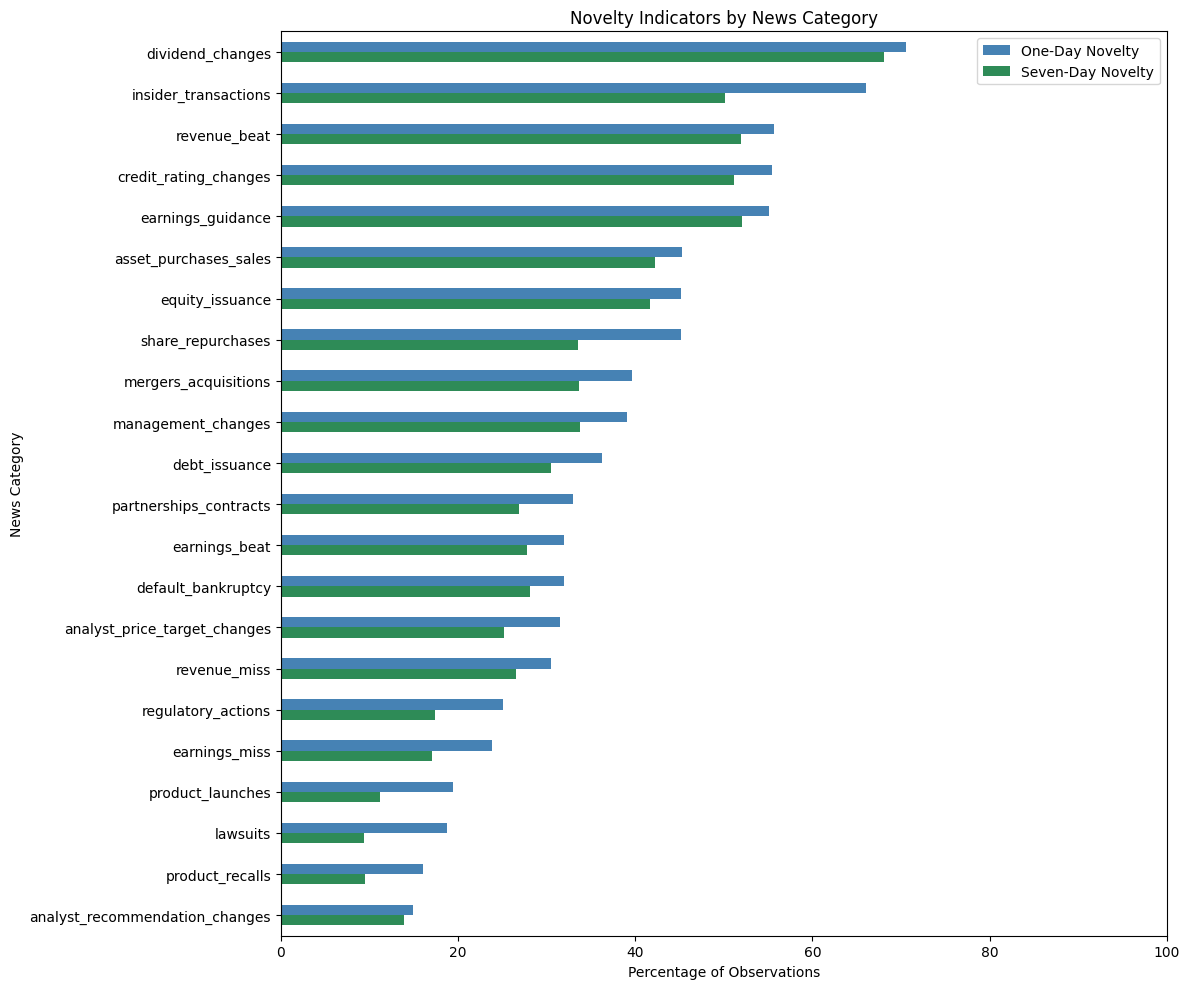

In [99]:
# 7.4.3 Visualize Novelty by News Category

novelty_by_category = (

    feature_df.groupby(
        "model_category",
        observed=True
    )[novelty_features]

    .mean() * 100

).sort_values(
    "novel_1day",
    ascending=False
)

display(novelty_by_category.round(4))

novelty_by_category.plot(

    kind="barh",

    figsize=(12, 10),

    color=["steelblue", "seagreen"]

)

plt.title("Novelty Indicators by News Category")
plt.xlabel("Percentage of Observations")
plt.ylabel("News Category")

plt.xlim(0, 100)
plt.gca().invert_yaxis()

plt.legend([
    "One-Day Novelty",
    "Seven-Day Novelty"
])

plt.tight_layout()
plt.show()

### 7.4.4 Interpretation of Novelty Indicators

The novelty indicators were successfully constructed
and validated across all 762,174 sampled observations.

Approximately 35.04% of observations satisfied the
one-day novelty threshold, while 28.08% satisfied
the seven-day novelty threshold.

Dividend changes demonstrated the highest percentage
of novel observations, while analyst recommendation
changes demonstrated considerably lower novelty.

These differences suggest that the frequency of
similar news coverage varies across event categories.

Both novelty indicators will be retained in the
baseline feature structure.

### 7.5 Construct Sentiment Interaction Variables

Category-specific sentiment interaction variables
are constructed to capture differences in sentiment
across standardized news categories.

Each interaction is calculated by multiplying the
corresponding news category indicator by the event
sentiment score.

This transformation allows the machine learning
models to examine whether the relationship between
sentiment and future stock returns differs across
financial events.

A total of 22 sentiment interaction variables
are constructed.

In [100]:
# 7.5.1 Create Sentiment Interaction Variables

for category in target_categories:

    feature_name = f"{category}_sentiment"

    feature_df[feature_name] = (
        feature_df[category] *
        feature_df["event_sentiment_score"]
    ).astype("float32")

display(
    feature_df[
        ["model_category", "event_sentiment_score"] +
        interaction_features
    ].head(10)
)

print(
    "Sentiment interaction variables created:",
    len(interaction_features)
)

,model_category,event_sentiment_score,earnings_beat_sentiment,earnings_miss_sentiment,revenue_beat_sentiment,revenue_miss_sentiment,earnings_guidance_sentiment,dividend_changes_sentiment,share_repurchases_sentiment,equity_issuance_sentiment,debt_issuance_sentiment,credit_rating_changes_sentiment,default_bankruptcy_sentiment,mergers_acquisitions_sentiment,asset_purchases_sales_sentiment,analyst_recommendation_changes_sentiment,analyst_price_target_changes_sentiment,management_changes_sentiment,insider_transactions_sentiment,lawsuits_sentiment,regulatory_actions_sentiment,product_launches_sentiment,product_recalls_sentiment,partnerships_contracts_sentiment
0,management_changes,0.53,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.53,0.0,0.0,0.0,0.0,0.0,0.00
1,partnerships_contracts,0.49,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.49
2,analyst_recommendation_changes,0.34,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.34,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00
3,earnings_guidance,-0.74,-0.0,-0.0,-0.0,-0.0,-0.74,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.00,-0.0,-0.00,-0.0,-0.0,-0.0,-0.0,-0.0,-0.00
4,management_changes,0.53,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.53,0.0,0.0,0.0,0.0,0.0,0.00
5,earnings_guidance,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00
6,partnerships_contracts,0.51,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.51
7,partnerships_contracts,0.51,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.51
8,earnings_guidance,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00
9,analyst_recommendation_changes,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00


Sentiment interaction variables created: 22


In [101]:
# 7.5.2 Validate Sentiment Interactions

interaction_sum = (
    feature_df[interaction_features].sum(axis=1)
)

sentiment_validation = np.isclose(

    interaction_sum.to_numpy(dtype=float),

    feature_df["event_sentiment_score"]
    .to_numpy(dtype=float),

    atol=1e-7

)

print(
    "Valid sentiment interactions:",
    f"{sentiment_validation.sum():,}"
)

print(
    "Invalid sentiment interactions:",
    f"{(~sentiment_validation).sum():,}"
)

print(
    "Sentiment interaction validation:",
    sentiment_validation.all()
)

Valid sentiment interactions: 762,174
Invalid sentiment interactions: 0
Sentiment interaction validation: True


In [102]:
# 7.5.3 Summarize Sentiment Interaction Variables

interaction_summary = pd.DataFrame({

    "Mean": (
        feature_df[interaction_features].mean()
    ),

    "Standard Deviation": (
        feature_df[interaction_features].std()
    ),

    "Minimum": (
        feature_df[interaction_features].min()
    ),

    "Maximum": (
        feature_df[interaction_features].max()
    ),

    "Nonzero Observations": (
        feature_df[interaction_features] != 0
    ).sum(),

    "Unique Values": (
        feature_df[interaction_features].nunique()
    )

})

display(interaction_summary.round(6))

,Mean,Standard Deviation,Minimum,Maximum,Nonzero Observations,Unique Values
earnings_beat_sentiment,0.010098,0.083111,-0.00,0.96,11143,21
earnings_miss_sentiment,-0.004317,0.056228,-0.82,0.00,4500,21
revenue_beat_sentiment,0.002615,0.041543,-0.00,1.00,3104,7
revenue_miss_sentiment,-0.002176,0.039635,-0.82,0.00,2422,9
earnings_guidance_sentiment,-0.001436,0.078512,-0.82,0.86,10460,32
dividend_changes_sentiment,0.003532,0.050862,-0.80,1.00,6641,35
share_repurchases_sentiment,0.009938,0.076698,-0.50,0.84,13140,5
equity_issuance_sentiment,0.001759,0.031797,-0.00,0.59,2334,7
debt_issuance_sentiment,0.000000,0.000000,-0.00,0.00,0,1
credit_rating_changes_sentiment,0.000018,0.052553,-1.00,0.96,10105,84


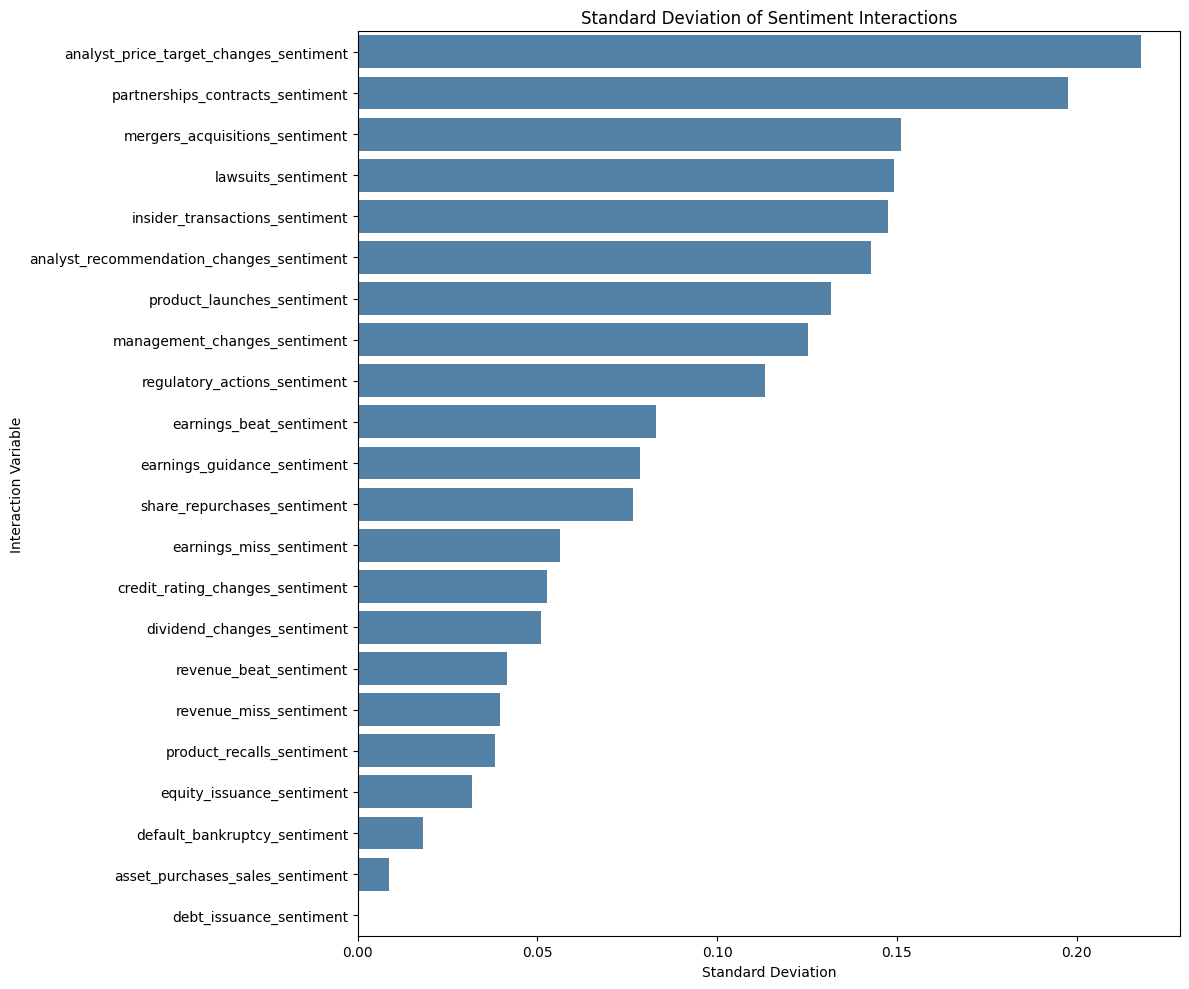

In [103]:
# 7.5.4 Visualize Sentiment Interaction Variation

interaction_plot = (
    interaction_summary
    .sort_values(
        "Standard Deviation",
        ascending=False
    )
)

plt.figure(figsize=(12, 10))

sns.barplot(

    x=interaction_plot["Standard Deviation"],

    y=interaction_plot.index,

    color="steelblue"

)

plt.title("Standard Deviation of Sentiment Interactions")
plt.xlabel("Standard Deviation")
plt.ylabel("Interaction Variable")

plt.tight_layout()
plt.show()

### 7.6 Validate the Baseline News Predictors

Following feature construction, the complete set
of baseline news predictors is validated.

The validation examines feature availability,
data types, missing observations, constant
variables, and consistency with the original
modeling specification.

The purpose of this analysis is to identify
potential issues before applying the feature
engineering process to the full mapped dataset.

In [104]:
# 7.6.1 Validate Feature Availability

missing_features = [

    col for col in baseline_news_features

    if col not in feature_df.columns

]

available_features = [

    col for col in baseline_news_features

    if col in feature_df.columns

]

print(
    "Expected baseline predictors:",
    len(baseline_news_features)
)

print(
    "Available baseline predictors:",
    len(available_features)
)

print(
    "Missing predictors:",
    missing_features
)

print(
    "Feature availability validation:",
    len(missing_features) == 0
)

Expected baseline predictors: 53
Available baseline predictors: 53
Missing predictors: []
Feature availability validation: True


In [105]:
# 7.6.2 Validate Data Types and Missing Values

feature_validation_summary = pd.DataFrame({

    "Data Type": (
        feature_df[baseline_news_features]
        .dtypes.astype(str)
    ),

    "Missing Observations": (
        feature_df[baseline_news_features]
        .isna().sum()
    ),

    "Missing (%)": (
        feature_df[baseline_news_features]
        .isna().mean() * 100
    ),

    "Unique Values": (
        feature_df[baseline_news_features]
        .nunique()
    ),

    "Minimum": (
        feature_df[baseline_news_features].min()
    ),

    "Maximum": (
        feature_df[baseline_news_features].max()
    )

})

with pd.option_context("display.max_rows", None):

    display(feature_validation_summary.round(4))

,Data Type,Missing Observations,Missing (%),Unique Values,Minimum,Maximum
earnings_beat,int8,0,0.0,2,0.0,1.0
earnings_miss,int8,0,0.0,2,0.0,1.0
revenue_beat,int8,0,0.0,2,0.0,1.0
revenue_miss,int8,0,0.0,2,0.0,1.0
earnings_guidance,int8,0,0.0,2,0.0,1.0
dividend_changes,int8,0,0.0,2,0.0,1.0
share_repurchases,int8,0,0.0,2,0.0,1.0
equity_issuance,int8,0,0.0,2,0.0,1.0
debt_issuance,int8,0,0.0,2,0.0,1.0
credit_rating_changes,int8,0,0.0,2,0.0,1.0


In [106]:
# 7.6.3 Identify Constant Predictors

constant_features = (

    feature_validation_summary[
        feature_validation_summary["Unique Values"] <= 1
    ]

)

display(constant_features)

print(
    "Number of constant predictors:",
    len(constant_features)
)

print(
    "Constant predictor names:",
    constant_features.index.tolist()
)

,Data Type,Missing Observations,Missing (%),Unique Values,Minimum,Maximum
debt_issuance_sentiment,float32,0,0.0,1,-0.0,0.0


Number of constant predictors: 1
Constant predictor names: ['debt_issuance_sentiment']


In [107]:
# 7.6.4 Validate Infinite Values

feature_matrix = (
    feature_df[baseline_news_features]
    .to_numpy(dtype="float32", na_value=np.nan)
)

infinite_values = np.isinf(feature_matrix).sum()

missing_values = np.isnan(feature_matrix).sum()

print("Infinite values:", infinite_values)

print("Missing values:", missing_values)

print(
    "Finite value validation:",
    infinite_values == 0 and missing_values == 0
)

del feature_matrix

Infinite values: 0
Missing values: 0
Finite value validation: True


In [108]:
# 7.6.5 Examine the Baseline Feature Dataset

baseline_feature_df = feature_df[
    baseline_news_features
].copy()

print(
    "Observations:",
    f"{baseline_feature_df.shape[0]:,}"
)

print(
    "Baseline predictors:",
    baseline_feature_df.shape[1]
)

display(baseline_feature_df.head(10))

Observations: 762,174
Baseline predictors: 53


,earnings_beat,earnings_miss,revenue_beat,revenue_miss,earnings_guidance,dividend_changes,share_repurchases,equity_issuance,debt_issuance,credit_rating_changes,default_bankruptcy,mergers_acquisitions,asset_purchases_sales,analyst_recommendation_changes,analyst_price_target_changes,management_changes,insider_transactions,lawsuits,regulatory_actions,product_launches,product_recalls,partnerships_contracts,relevance,event_sentiment_score,event_relevance,event_similarity_days,is_fact,is_forecast,is_opinion,novel_1day,novel_7days,earnings_beat_sentiment,earnings_miss_sentiment,revenue_beat_sentiment,revenue_miss_sentiment,earnings_guidance_sentiment,dividend_changes_sentiment,share_repurchases_sentiment,equity_issuance_sentiment,debt_issuance_sentiment,credit_rating_changes_sentiment,default_bankruptcy_sentiment,mergers_acquisitions_sentiment,asset_purchases_sales_sentiment,analyst_recommendation_changes_sentiment,analyst_price_target_changes_sentiment,management_changes_sentiment,insider_transactions_sentiment,lawsuits_sentiment,regulatory_actions_sentiment,product_launches_sentiment,product_recalls_sentiment,partnerships_contracts_sentiment
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,100,0.53,100,0.0,1,0,0,0,0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.53,0.0,0.0,0.0,0.0,0.0,0.00
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,99,0.49,80,14.51025,1,0,0,1,1,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.49
2,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,100,0.34,100,0.00688,1,0,0,0,0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.34,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00
3,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,100,-0.74,100,365.0,0,1,0,1,1,-0.0,-0.0,-0.0,-0.0,-0.74,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.00,-0.0,-0.00,-0.0,-0.0,-0.0,-0.0,-0.0,-0.00
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,100,0.53,100,0.0,1,0,0,0,0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.53,0.0,0.0,0.0,0.0,0.0,0.00
5,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,100,0.0,100,365.0,0,1,0,1,1,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,100,0.51,100,0.0,1,0,0,0,0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.51
7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,100,0.51,100,0.00109,1,0,0,0,0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.51
8,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,100,0.0,100,52.80828,0,1,0,1,1,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00
9,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,100,0.0,100,0.00689,1,0,0,0,0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00


In [109]:
# 7.6.6 Overall Feature Validation

validation_checks = {

    "Correct Number of Predictors":
        len(baseline_news_features) == 53,

    "Unique Predictor Names":
        len(set(baseline_news_features)) == 53,

    "All Predictors Available":
        len(missing_features) == 0,

    "Valid Category Indicators":
        (category_indicator_sum == 1).all(),

    "Valid Fact-Level Indicators":
        (fact_indicator_sum == 1).all(),

    "Valid Novelty Indicators":
        invalid_novelty == 0,

    "Valid Sentiment Interactions":
        sentiment_validation.all(),

    "No Missing Values":
        missing_values == 0,

    "No Infinite Values":
        infinite_values == 0,

    "All Predictors Numerical":
        all(
            pd.api.types.is_numeric_dtype(
                feature_df[col]
            )
            for col in baseline_news_features
        ),

    "Original Sample Size Preserved":
        len(feature_df) == len(eda_df)

}

validation_report = pd.DataFrame({

    "Validation Check": list(validation_checks.keys()),

    "Passed": list(validation_checks.values())

})

display(validation_report)

print(
    "Validation checks passed:",
    f"{validation_report['Passed'].sum()} / "
    f"{len(validation_report)}"
)

print(
    "Overall feature validation:",
    validation_report["Passed"].all()
)

,Validation Check,Passed
0,Correct Number of Predictors,True
1,Unique Predictor Names,True
2,All Predictors Available,True
3,Valid Category Indicators,True
4,Valid Fact-Level Indicators,True
5,Valid Novelty Indicators,True
6,Valid Sentiment Interactions,True
7,No Missing Values,True
8,No Infinite Values,True
9,All Predictors Numerical,True


Validation checks passed: 11 / 11
Overall feature validation: True


### 7.6.7 Interpretation of Feature Engineering Results

A total of 53 baseline news predictors were
successfully constructed and validated across
762,174 sampled observations.

All 11 feature validation checks were satisfied,
with no missing values, infinite values, duplicate
predictor names, or invalid feature encodings.

The sentiment interaction analysis identified
differences in variation across standardized
news categories. Analyst price-target changes
demonstrated the highest interaction variation.

One constant predictor, debt_issuance_sentiment,
was identified. This variable will remain in the
exported feature structure to maintain consistency
with the original modeling specification.

The successful validation of the analysis sample
provides a foundation for applying the feature
engineering process to the full mapped dataset.

### 7.7 Duplicate-Event Analysis

The RavenPack dataset may contain multiple
observations associated with the same news story,
company, security, or underlying financial event.

Duplicate-event analysis is conducted to distinguish
repeated observations from distinct financial events.

Several combinations of identification variables
are examined before establishing the appropriate
observation structure for the processed dataset.

No observations are removed during this initial
investigation.

In [110]:
# 7.7.1 Define Event Identification Variables

event_identifier_groups = {

    "Story ID": [
        "rp_story_id"
    ],

    "Story and Company": [
        "rp_story_id",
        "rp_entity_id"
    ],

    "Story and Security": [
        "rp_story_id",
        "cusip"
    ],

    "Story, Company and Event Index": [
        "rp_story_id",
        "rp_entity_id",
        "rp_story_event_index"
    ],

    "Story, Security and Event Index": [
        "rp_story_id",
        "cusip",
        "rp_story_event_index"
    ],

    "Story, Security, Event Index and Category": [
        "rp_story_id",
        "cusip",
        "rp_story_event_index",
        "category"
    ],

    "Story, Security, Event Index, Category and Timestamp": [
        "rp_story_id",
        "cusip",
        "rp_story_event_index",
        "category",
        "timestamp_utc"
    ]
}

print(
    "Identification combinations:",
    len(event_identifier_groups)
)

Identification combinations: 7


In [111]:
# 7.7.2 Examine Duplicate Identifier Combinations

duplicate_results = []

for name, columns in event_identifier_groups.items():

    duplicate_count = (
        feature_df.duplicated(
            subset=columns,
            keep="first"
        ).sum()
    )

    unique_count = (
        feature_df[columns]
        .drop_duplicates()
        .shape[0]
    )

    duplicate_results.append({

        "Identification Combination": name,

        "Unique Combinations": unique_count,

        "Duplicate Observations": duplicate_count,

        "Duplicate Percentage (%)": (
            duplicate_count / len(feature_df) * 100
        )

    })

duplicate_summary = pd.DataFrame(
    duplicate_results
)

display(duplicate_summary.round(4))

,Identification Combination,Unique Combinations,Duplicate Observations,Duplicate Percentage (%)
0,Story ID,256513,505661,66.3446
1,Story and Company,259317,502857,65.9767
2,Story and Security,268521,493653,64.7691
3,"Story, Company and Event Index",279211,482963,63.3665
4,"Story, Security and Event Index",289772,472402,61.9809
5,"Story, Security, Event Index and Category",289772,472402,61.9809
6,"Story, Security, Event Index, Category and Tim...",289772,472402,61.9809


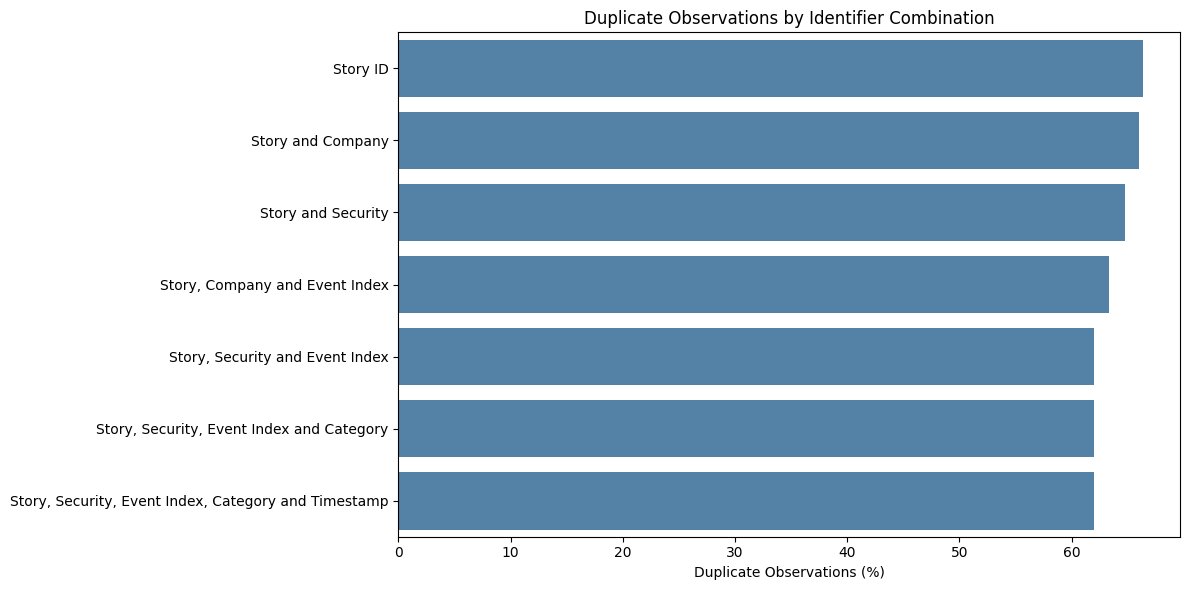

In [112]:
# 7.7.3 Visualize Duplicate Identifier Combinations

plt.figure(figsize=(12, 6))

sns.barplot(

    data=duplicate_summary,

    x="Duplicate Percentage (%)",

    y="Identification Combination",

    color="steelblue"

)

plt.title("Duplicate Observations by Identifier Combination")
plt.xlabel("Duplicate Observations (%)")
plt.ylabel("")

plt.tight_layout()
plt.show()

In [113]:
# 7.7.4 Examine Identical Observations

original_analysis_columns = (
    eda_columns + ["model_category"]
)

exact_duplicate_mask = feature_df.duplicated(

    subset=original_analysis_columns,

    keep="first"

)

exact_duplicate_count = (
    exact_duplicate_mask.sum()
)

print(
    "Total sampled observations:",
    f"{len(feature_df):,}"
)

print(
    "Identical observations across selected variables:",
    f"{exact_duplicate_count:,}"
)

print(
    "Duplicate percentage:",
    f"{exact_duplicate_count / len(feature_df) * 100:.4f}%"
)

print(
    "Remaining observations if duplicates were removed:",
    f"{len(feature_df) - exact_duplicate_count:,}"
)

Total sampled observations: 762,174
Identical observations across selected variables: 472,402
Duplicate percentage: 61.9809%
Remaining observations if duplicates were removed: 289,772


In [114]:
# 7.7.5 Examine Repeated Event Records

event_key = [
    "rp_story_id",
    "cusip",
    "rp_story_event_index",
    "category",
    "timestamp_utc"
]

repeated_event_mask = feature_df.duplicated(

    subset=event_key,

    keep=False

)

repeated_events = (

    feature_df.loc[
        repeated_event_mask,
        event_key + [
            "rp_entity_id",
            "model_category",
            "event_sentiment_score",
            "relevance",
            "event_relevance",
            "event_similarity_key",
            "event_similarity_days"
        ]
    ]

    .sort_values(event_key)

)

print(
    "Observations belonging to repeated event keys:",
    f"{len(repeated_events):,}"
)

display(repeated_events.head(30))

Observations belonging to repeated event keys: 614,028


,rp_story_id,cusip,rp_story_event_index,category,timestamp_utc,rp_entity_id,model_category,event_sentiment_score,relevance,event_relevance,event_similarity_key,event_similarity_days
383777,0000C6BA4D1FA203DD77A06268E70033,718172109,1,earnings-per-share-guidance-down,2023-09-28 08:12:35.363000+00:00,CA1620,earnings_guidance,-0.74,100,100,58D7E4A4EF90CE10F5C36DE848A9A8A2,365.0
383795,0000C6BA4D1FA203DD77A06268E70033,718172109,1,earnings-per-share-guidance-down,2023-09-28 08:12:35.363000+00:00,CA1620,earnings_guidance,-0.74,100,100,58D7E4A4EF90CE10F5C36DE848A9A8A2,365.0
169595,0000EC35051A7941CBEFCBEFF469334F,595112103,4,analyst-ratings-change-neutral,2022-12-21 17:36:03.170000+00:00,49BBBC,analyst_recommendation_changes,0.2,99,15,58CC9BE4B10F5D8455CE5959D9422D1A,153.14229
169615,0000EC35051A7941CBEFCBEFF469334F,595112103,4,analyst-ratings-change-neutral,2022-12-21 17:36:03.170000+00:00,49BBBC,analyst_recommendation_changes,0.2,99,15,58CC9BE4B10F5D8455CE5959D9422D1A,153.14229
585039,00016AAB6B3D733FEAE93B49A8DC3FA1,02079K107,1,price-target-upgrade,2021-02-03 18:00:07.192000+00:00,4A6F00,analyst_price_target_changes,0.66,100,100,B5FF5450A6FA722EC9FBBBC5E4241254,0.10882
586106,00016AAB6B3D733FEAE93B49A8DC3FA1,02079K107,1,price-target-upgrade,2021-02-03 18:00:07.192000+00:00,4A6F00,analyst_price_target_changes,0.66,100,100,B5FF5450A6FA722EC9FBBBC5E4241254,0.10882
591483,00016AAB6B3D733FEAE93B49A8DC3FA1,02079K107,1,price-target-upgrade,2021-02-03 18:00:07.192000+00:00,4A6F00,analyst_price_target_changes,0.66,100,100,B5FF5450A6FA722EC9FBBBC5E4241254,0.10882
591873,00016AAB6B3D733FEAE93B49A8DC3FA1,02079K107,1,price-target-upgrade,2021-02-03 18:00:07.192000+00:00,4A6F00,analyst_price_target_changes,0.66,100,100,B5FF5450A6FA722EC9FBBBC5E4241254,0.10882
605819,00016AAB6B3D733FEAE93B49A8DC3FA1,02079K107,1,price-target-upgrade,2021-02-03 18:00:07.192000+00:00,4A6F00,analyst_price_target_changes,0.66,100,100,B5FF5450A6FA722EC9FBBBC5E4241254,0.10882
606154,00016AAB6B3D733FEAE93B49A8DC3FA1,02079K107,1,price-target-upgrade,2021-02-03 18:00:07.192000+00:00,4A6F00,analyst_price_target_changes,0.66,100,100,B5FF5450A6FA722EC9FBBBC5E4241254,0.10882


In [115]:
# 7.7.6 Examine Similar Events

similarity_key_columns = [
    "cusip",
    "event_similarity_key"
]

similarity_counts = (

    feature_df
    .dropna(subset=similarity_key_columns)
    .groupby(
        similarity_key_columns,
        observed=True
    )
    .size()
    .sort_values(ascending=False)

)

print(
    "Unique security-similarity combinations:",
    f"{len(similarity_counts):,}"
)

print(
    "Combinations appearing more than once:",
    f"{(similarity_counts > 1).sum():,}"
)

print(
    "Maximum observations per combination:",
    similarity_counts.max()
)

display(
    similarity_counts.head(20)
    .to_frame("Observations")
)

Unique security-similarity combinations: 91,078
Combinations appearing more than once: 58,499
Maximum observations per combination: 10235


Observations
cusip     event_similarity_key                          
02079K107 0D195B15A13008421DCD2DD2E84DE570         10235
02079K305 0D195B15A13008421DCD2DD2E84DE570          9970
594918104 289793C7B3C9E4A05A422BC567945B25          8585
02079K305 5F346A641DF669C14289183AF03C2935          4555
02079K107 5F346A641DF669C14289183AF03C2935          4535
          4DE053CA730D0DA71424EED4AECF1604          2936
02079K305 4DE053CA730D0DA71424EED4AECF1604          2890
023135106 9EDA753B063D9E38DDE3CF3CDF437F93          2541
30303M102 32941E15FA831B65FE1A6EDF2729D84D          2222
46625H100 68A0B06DE48C67D134AFF8D7180E588E          2215
67066G104 B7D29ED338C412CF370956B77523F199          1875
46625H100 89B77EBA439D49DF638C31EC015A8F15          1863
023135106 B17937E768F22C0A69F9D97194C6C250          1840
46625H100 A69B76C23CC6F254E87F580278843C56          1832
594918104 ECECF701EE5CF8A826C14E469E81160A          1726
02079K305 DF7CB115D062D6F0FF574CEF058B250E          1592
02079K107 DF7CB115D062D6F0FF574CEF058B250E          1515
          29B95EC117BB15EB31DCC7EEE352EA13          1472
38141G104 D2A94C8E1F58182D4AC658B364B113DB          1461
88160R101 AE9D5EB338303EA7C59758759927E757          1447

In [2]:
# Kernel Died 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

output_folder = Path("data")

eda_df = pd.read_parquet(
    output_folder / "ravenpack_eda_sample.parquet"
)

feature_df = eda_df.copy()

print("Dataset restored successfully.")
print("Observations:", f"{len(feature_df):,}")
print("Variables:", len(feature_df.columns))

Dataset restored successfully.
Observations: 762,174
Variables: 28


In [4]:
# 7.7.7 Examine Multiple Share Classes

company_security_counts = (
    feature_df.groupby(
        "rp_entity_id",
        observed=True
    )["cusip"]
    .nunique()
)

multiple_share_class_ids = (
    company_security_counts[
        company_security_counts > 1
    ].index
)

print(
    "Companies with multiple CUSIPs:",
    len(multiple_share_class_ids)
)

share_class_events = (
    feature_df.loc[
        feature_df["rp_entity_id"].isin(
            multiple_share_class_ids
        )
    ]
    .groupby(
        [
            "rp_entity_id",
            "rp_story_id",
            "rp_story_event_index",
            "category",
            "timestamp_utc"
        ],
        observed=True,
        sort=False
    )["cusip"]
    .nunique()
)

multiple_security_events = (
    share_class_events[share_class_events > 1]
)

print(
    "Unique company-event combinations:",
    f"{len(share_class_events):,}"
)

print(
    "Events associated with multiple securities:",
    f"{len(multiple_security_events):,}"
)

display(multiple_security_events.head(20))

Companies with multiple CUSIPs: 4
Unique company-event combinations: 11,578
Events associated with multiple securities: 10,561


rp_entity_id  rp_story_id                       rp_story_event_index  category                         timestamp_utc                   
41EC04        DF49122E91568650222A4A7DB47D0549  1                     insider-sell                     2023-02-14 21:09:59.899000+00:00    2
              B9C9FF922574C1B4D0AE1F741BF26139  1                     insider-surrender                2023-05-17 21:32:33.567000+00:00    2
              7600F182563FD6572E340073921BB701  1                     price-target-downgrade           2023-06-23 10:00:09.609000+00:00    2
              6E2EE33BE00F04EB400C0FD175AB12B0  1                     earnings-above-expectations      2023-08-08 12:15:20.954000+00:00    2
              B3171A4416C34944C4608902E98DD847  1                     price-target-upgrade             2023-02-06 14:44:23.497000+00:00    2
              2AD0CEEDCFC40507A82EF28C1C01F751  1                     earnings-above-expectations      2023-02-08 12:49:18.451000+00:00    2
              16AC

### 7.7.8 Interpretation of Multiple Share Classes

The multiple-share-class analysis identified four
companies associated with multiple CUSIPs.

A total of 11,578 unique company-event combinations
were identified within these companies, of which
10,561 were associated with multiple securities.

These results demonstrate that individual company
news events may be associated with different
securities belonging to the same company.

Since the project examines stock returns at the
security level, observations associated with
different CUSIPs will be preserved.

The results are based on the analysis sample.
Additional duplicate-event validation will be
conducted using the full mapped dataset before
establishing the final observation structure.

### 7.7.9 Interpretation of Duplicate-Event Analysis

The duplicate-event analysis identified substantial
repetition within the RavenPack news dataset.

Of the 762,174 sampled observations, 472,402 were
identified as duplicate records across the selected
analysis variables, representing approximately
61.98% of the sample.

A total of 289,772 unique security-event combinations
were identified. Adding category and timestamp
information did not increase the number of unique
event combinations.

The multiple-share-class analysis demonstrated that
individual company events may be associated with
different securities. These observations will be
preserved because the project examines stock returns
at the security level.

Observations sharing an event similarity key will
not automatically be removed because they may
represent distinct news reports.

Duplicate validation will be conducted across the
full mapped dataset before establishing the final
observation count.

## 8.0 Full Dataset Transformation

Following the successful validation of the feature
engineering process, the preprocessing methodology
is applied to the full RavenPack news dataset.

The original CSV file is processed in smaller chunks
to reduce memory consumption.

The standardized category mapping is applied before
conducting global duplicate validation and constructing
the final machine learning predictors.

Intermediate datasets are stored in Parquet format
to improve storage and processing efficiency.

In [5]:
# 8.1.1 Import Required Libraries Bcs the Kernel keeps dying 

import pandas as pd
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq
import gc
import shutil
import psutil

from pathlib import Path

print("Libraries imported successfully.")

print(
    "Available RAM (GB):",
    round(
        psutil.virtual_memory().available / 1024**3,
        2
    )
)

Libraries imported successfully.
Available RAM (GB): 24.96


In [6]:
# 8.1.2 Restore File Locations

file_path = Path("News Ml Project Data .csv")

output_folder = Path("data")

mapping_path = (
    output_folder /
    "ravenpack_category_mapping.parquet"
)

print("Original CSV exists:", file_path.exists())

print("Category mapping exists:", mapping_path.exists())

print(
    "Available disk space (GB):",
    round(
        shutil.disk_usage(output_folder).free / 1024**3,
        2
    )
)

Original CSV exists: True
Category mapping exists: True
Available disk space (GB): 432.23


In [7]:
# 8.1.3 Restore the Category Mapping

taxonomy_mapped = pd.read_parquet(mapping_path)

news_category_mapping = (
    taxonomy_mapped
    .set_index("category")["model_category"]
    .to_dict()
)

target_categories = sorted(

    taxonomy_mapped.loc[
        taxonomy_mapped["model_category"] != "unmapped",
        "model_category"
    ].dropna().unique().tolist()

)

print(
    "Original category mapping entries:",
    len(news_category_mapping)
)

print(
    "Standardized news categories:",
    len(target_categories)
)

display(target_categories)

Original category mapping entries: 1007
Standardized news categories: 22


['analyst_price_target_changes',
 'analyst_recommendation_changes',
 'asset_purchases_sales',
 'credit_rating_changes',
 'debt_issuance',
 'default_bankruptcy',
 'dividend_changes',
 'earnings_beat',
 'earnings_guidance',
 'earnings_miss',
 'equity_issuance',
 'insider_transactions',
 'lawsuits',
 'management_changes',
 'mergers_acquisitions',
 'partnerships_contracts',
 'product_launches',
 'product_recalls',
 'regulatory_actions',
 'revenue_beat',
 'revenue_miss',
 'share_repurchases']

In [8]:
# 8.1.4 Validate the Original Dataset Structure

original_columns = pd.read_csv(
    file_path,
    nrows=0
).columns.tolist()

print(
    "Original dataset columns:",
    len(original_columns)
)

print(
    "Category column available:",
    "category" in original_columns
)

display(original_columns)

Original dataset columns: 55
Category column available: True


['cusip',
 'rpa_date_utc',
 'rpa_time_utc',
 'timestamp_utc',
 'rp_story_id',
 'rp_entity_id',
 'entity_type',
 'entity_name',
 'country_code',
 'relevance',
 'event_sentiment_score',
 'event_relevance',
 'event_similarity_key',
 'event_similarity_days',
 'topic',
 'group',
 'type',
 'sub_type',
 'property',
 'fact_level',
 'rp_position_id',
 'position_name',
 'evaluation_method',
 'maturity',
 'earnings_type',
 'event_start_date_utc',
 'event_end_date_utc',
 'reporting_period',
 'reporting_start_date_utc',
 'reporting_end_date_utc',
 'related_entity',
 'relationship',
 'category',
 'event_text',
 'news_type',
 'rp_source_id',
 'source_name',
 'css',
 'nip',
 'peq',
 'bee',
 'bmq',
 'bam',
 'bca',
 'ber',
 'anl_chg',
 'mcq',
 'rp_story_event_index',
 'rp_story_event_count',
 'product_key',
 'provider_id',
 'provider_story_id',
 'headline',
 'ticker',
 'isin']

### 8.2 Extract the Full Mapped News Dataset

The standardized category mapping is applied to
the original RavenPack dataset.

Observations belonging to the 22 selected financial
event categories are extracted and written to an
intermediate Parquet file.

All original variables are temporarily preserved
to support comprehensive duplicate validation.

The original CSV file remains unchanged throughout
the preprocessing process.

In [9]:
# 8.2.1 Define Processing Parameters

chunk_size = 100_000

mapped_output_path = (
    output_folder /
    "ravenpack_full_mapped.parquet"
)

temporary_output_path = (
    output_folder /
    "ravenpack_full_mapped_temp.parquet"
)

expected_total_rows = 50_999_638

expected_mapped_rows = 7_628_809

print("Chunk size:", f"{chunk_size:,}")

print(
    "Expected original observations:",
    f"{expected_total_rows:,}"
)

print(
    "Expected mapped observations:",
    f"{expected_mapped_rows:,}"
)

Chunk size: 100,000
Expected original observations: 50,999,638
Expected mapped observations: 7,628,809


In [10]:
# 8.2.2 Process and Save the Full Mapped Dataset

rows_processed = 0
rows_mapped = 0
rows_excluded = 0

# Consistent data types across all chunks
parquet_schema = pa.schema([

    (col, pa.string())

    for col in original_columns + ["model_category"]

])

# Process and write one chunk at a time
with pq.ParquetWriter(

    str(temporary_output_path),

    parquet_schema,

    compression="snappy"

) as writer:

    for i, chunk in enumerate(

        pd.read_csv(
            file_path,
            chunksize=chunk_size,
            dtype="string"
        ),

        start=1

    ):

        rows_processed += len(chunk)

        # Apply standardized category mapping
        chunk["model_category"] = (
            chunk["category"]
            .map(news_category_mapping)
        )

        # Retain selected news categories
        mapped_chunk = chunk.loc[
            chunk["model_category"].isin(
                target_categories
            )
        ]

        rows_mapped += len(mapped_chunk)

        rows_excluded += (
            len(chunk) - len(mapped_chunk)
        )

        # Write directly to Parquet
        if not mapped_chunk.empty:

            table = pa.Table.from_pandas(

                mapped_chunk,
                schema=parquet_schema,
                preserve_index=False

            )

            writer.write_table(table)

            del table

        del chunk, mapped_chunk

        # Display processing progress
        if i % 50 == 0:

            gc.collect()

            print(
                f"Processed: {rows_processed:,} | "
                f"Mapped: {rows_mapped:,} | "
                f"Excluded: {rows_excluded:,}"
            )

# Validate before replacing the completed output
assert rows_processed == expected_total_rows
assert rows_mapped == expected_mapped_rows
assert rows_processed == rows_mapped + rows_excluded

temporary_output_path.replace(mapped_output_path)

print("\nProcessing complete.")

print(
    "Original observations processed:",
    f"{rows_processed:,}"
)

print(
    "Mapped observations:",
    f"{rows_mapped:,}"
)

print(
    "Excluded observations:",
    f"{rows_excluded:,}"
)

print("Output file:", mapped_output_path)

Processed: 5,000,000 | Mapped: 1,091,047 | Excluded: 3,908,953
Processed: 10,000,000 | Mapped: 2,403,830 | Excluded: 7,596,170
Processed: 15,000,000 | Mapped: 2,737,781 | Excluded: 12,262,219
Processed: 20,000,000 | Mapped: 3,086,507 | Excluded: 16,913,493
Processed: 25,000,000 | Mapped: 3,665,539 | Excluded: 21,334,461
Processed: 30,000,000 | Mapped: 4,507,230 | Excluded: 25,492,770
Processed: 35,000,000 | Mapped: 5,591,582 | Excluded: 29,408,418
Processed: 40,000,000 | Mapped: 6,281,991 | Excluded: 33,718,009
Processed: 45,000,000 | Mapped: 6,635,801 | Excluded: 38,364,199
Processed: 50,000,000 | Mapped: 7,441,722 | Excluded: 42,558,278

Processing complete.
Original observations processed: 50,999,638
Mapped observations: 7,628,809
Excluded observations: 43,370,829
Output file: data/ravenpack_full_mapped.parquet


In [13]:
# 8.2.3 Validate the Intermediate Parquet File

mapped_parquet = pq.ParquetFile(
    mapped_output_path
)

print(
    "Total observations:",
    f"{mapped_parquet.metadata.num_rows:,}"
)

print(
    "Total variables:",
    mapped_parquet.metadata.num_columns
)

print(
    "Parquet row groups:",
    mapped_parquet.metadata.num_row_groups
)

print(
    "File size (GB):",
    round(
        mapped_output_path.stat().st_size / 1024**3,
        4
    )
)

print(
    "Observation count validation:",
    mapped_parquet.metadata.num_rows ==
    expected_mapped_rows
)

print(
    "Column count validation:",
    mapped_parquet.metadata.num_columns ==
    len(original_columns) + 1
)

Total observations: 7,628,809
Total variables: 56
Parquet row groups: 510
File size (GB): 0.2609
Observation count validation: True
Column count validation: True


In [14]:
# 8.2.4 Preview the Mapped Dataset

preview_columns = [
    "rp_entity_id",
    "cusip",
    "rp_story_id",
    "rp_story_event_index",
    "timestamp_utc",
    "category",
    "model_category",
    "event_sentiment_score",
    "fact_level"
]

preview_batch = next(

    mapped_parquet.iter_batches(

        batch_size=10,

        columns=preview_columns

    )

)

display(preview_batch.to_pandas())

,rp_entity_id,cusip,rp_story_id,rp_story_event_index,timestamp_utc,category,model_category,event_sentiment_score,fact_level
0,00067A,444859102,740EF97010EE0A328F3E0879A5445C62,1,2023-01-06 16:25:23.371,analyst-ratings-change-neutral,analyst_recommendation_changes,0.34,fact
1,00067A,444859102,DA89ADB02D74D2BCF1E72000BAE5D9C1,1,2023-01-06 16:25:23.439,price-target-downgrade,analyst_price_target_changes,-0.17,fact
2,00067A,444859102,D20C573C2468552E5B26FC8726D3FABD,1,2023-01-10 14:35:00.204,partnership,partnerships_contracts,0.49,fact
3,00067A,444859102,2CB2902F3B4118056E8B4E4658748B13,1,2023-01-24 21:00:00.463,executive-appointment,management_changes,0.53,fact
4,00067A,444859102,777FFD583FA07D9AB8B9F6EC0FDFFE64,1,2023-01-24 21:00:00.614,executive-appointment,management_changes,0.53,fact
5,00067A,444859102,1EF8FF90EA4B32E3D45F82AD1D198375,1,2023-01-24 21:00:04.888,executive-appointment,management_changes,0.53,fact
6,00067A,444859102,2D978BE41C52F9B1A5E2D9703300E999,1,2023-01-30 19:31:39.534,credit-rating-affirmation,credit_rating_changes,0.03,fact
7,00067A,444859102,F495F6AD35F75879EE4DFDF0437EB4EB,2,2023-02-01 11:30:00.684,earnings-guidance,earnings_guidance,0,forecast
8,00067A,444859102,3BBC1006F691C616C3425857721FCBA3,4,2023-02-01 11:30:00.7,earnings-guidance,earnings_guidance,0,forecast
9,00067A,444859102,F917524CD9B9350720C64D7EB4F30DE5,4,2023-02-01 11:30:00.769,earnings-guidance,earnings_guidance,0,forecast


### 8.2.5 Interpretation of Full Dataset Extraction

The standardized category mapping was successfully
applied to all 50,999,638 original observations.

A total of 7,628,809 observations belonging to the
22 standardized news categories were retained.

The intermediate dataset contains 56 variables,
consisting of the original 55 variables and the
standardized news category.

The resulting Parquet file occupies approximately
0.26 GB of storage, representing a substantial
reduction compared with the original CSV file.

Both observation and column count validations
were satisfied. The intermediate dataset will
be used for global duplicate validation before
constructing the final machine learning predictors.

### 8.3 Global Duplicate Validation and Removal

Global duplicate validation is conducted across
the complete mapped news dataset.

Exact duplicate records are distinguished from
observations sharing similar event identifiers
but containing different information.

DuckDB is used to perform these operations
directly on the intermediate Parquet dataset,
reducing memory consumption and allowing duplicate
records to be identified across processing chunks.

Different securities and distinct news events
will remain in the processed dataset.

In [15]:
# 8.3.1 Install DuckDB

%pip install duckdb

Note: you may need to restart the kernel to use updated packages.


In [16]:
import duckdb

print("DuckDB version:", duckdb.__version__)

DuckDB version: 2.0.0


In [17]:
# 8.3.2 Configure Memory-Efficient Processing

duckdb_temp_folder = (
    output_folder / "duckdb_temp"
)

duckdb_temp_folder.mkdir(
    parents=True,
    exist_ok=True
)

con = duckdb.connect(database=":memory:")

con.execute("SET memory_limit = '6GB'")
con.execute("SET threads = 2")

con.execute(
    "SET temp_directory = ?",
    [str(duckdb_temp_folder.resolve())]
)

con.execute(
    "SET preserve_insertion_order = false"
)

print("DuckDB configured successfully.")
print("Memory limit: 6 GB")
print("Processing threads: 2")
print("Temporary directory:", duckdb_temp_folder)

DuckDB configured successfully.
Memory limit: 6 GB
Processing threads: 2
Temporary directory: data/duckdb_temp


In [18]:
# 8.3.3 Connect to the Full Mapped Dataset

mapped_output_path = (
    output_folder /
    "ravenpack_full_mapped.parquet"
)

con.read_parquet(
    str(mapped_output_path.resolve())
).create_view(
    "mapped_news",
    replace=True
)

mapped_count = con.execute("""
    SELECT COUNT(*)
    FROM mapped_news
""").fetchone()[0]

print(
    "Total mapped observations:",
    f"{mapped_count:,}"
)

print(
    "Observation count validation:",
    mapped_count == 7_628_809
)

Total mapped observations: 7,628,809
Observation count validation: True


In [19]:
# 8.3.4 Examine Global Duplicate Identifier Combinations

event_identifier_groups = {

    "Story ID": [
        "rp_story_id"
    ],

    "Story and Company": [
        "rp_story_id",
        "rp_entity_id"
    ],

    "Story and Security": [
        "rp_story_id",
        "cusip"
    ],

    "Story, Company and Event Index": [
        "rp_story_id",
        "rp_entity_id",
        "rp_story_event_index"
    ],

    "Story, Security and Event Index": [
        "rp_story_id",
        "cusip",
        "rp_story_event_index"
    ],

    "Story, Security, Event Index and Category": [
        "rp_story_id",
        "cusip",
        "rp_story_event_index",
        "category"
    ],

    "Complete Security-Event Key": [
        "rp_story_id",
        "cusip",
        "rp_entity_id",
        "rp_story_event_index",
        "category",
        "timestamp_utc"
    ]
}

global_duplicate_results = []

for name, columns in event_identifier_groups.items():

    column_list = ", ".join(columns)

    unique_count = con.execute(f"""
        SELECT COUNT(*)
        FROM (
            SELECT DISTINCT {column_list}
            FROM mapped_news
        )
    """).fetchone()[0]

    duplicate_count = mapped_count - unique_count

    global_duplicate_results.append({

        "Identification Combination": name,

        "Unique Combinations": unique_count,

        "Duplicate Observations": duplicate_count,

        "Duplicate Percentage (%)": (
            duplicate_count / mapped_count * 100
        )

    })

    print(f"Completed: {name}")

global_duplicate_summary = pd.DataFrame(
    global_duplicate_results
)

display(global_duplicate_summary.round(4))

Completed: Story ID
Completed: Story and Company
Completed: Story and Security
Completed: Story, Company and Event Index
Completed: Story, Security and Event Index
Completed: Story, Security, Event Index and Category
Completed: Complete Security-Event Key


,Identification Combination,Unique Combinations,Duplicate Observations,Duplicate Percentage (%)
0,Story ID,522952,7105857,93.1450
1,Story and Company,529607,7099202,93.0578
2,Story and Security,539802,7089007,92.9242
3,"Story, Company and Event Index",589038,7039771,92.2788
4,"Story, Security and Event Index",600847,7027962,92.1240
5,"Story, Security, Event Index and Category",600847,7027962,92.1240
6,Complete Security-Event Key,600847,7027962,92.1240


In [20]:
# 8.3.5 Remove Exact Duplicate Records

deduplicated_output_path = (
    output_folder /
    "ravenpack_deduplicated.parquet"
)

deduplicated_temp_path = (
    output_folder /
    "ravenpack_deduplicated_temp.parquet"
)

# Remove an incomplete temporary file if necessary
deduplicated_temp_path.unlink(missing_ok=True)

# Escape the path for the SQL statement
sql_output_path = str(
    deduplicated_temp_path.resolve()
).replace("'", "''")

con.execute(f"""
    COPY (
        SELECT DISTINCT *
        FROM mapped_news
    )
    TO '{sql_output_path}'
    (
        FORMAT PARQUET,
        COMPRESSION SNAPPY
    )
""")

# Validate the temporary output
deduplicated_parquet = pq.ParquetFile(
    deduplicated_temp_path
)

deduplicated_count = (
    deduplicated_parquet.metadata.num_rows
)

assert 0 < deduplicated_count <= mapped_count

assert (
    deduplicated_parquet.metadata.num_columns == 56
)

deduplicated_output_path = (
    deduplicated_temp_path.replace(
        deduplicated_output_path
    )
)

print("Exact duplicate removal completed.")

print(
    "Original mapped observations:",
    f"{mapped_count:,}"
)

print(
    "Remaining observations:",
    f"{deduplicated_count:,}"
)

print(
    "Exact duplicates removed:",
    f"{mapped_count - deduplicated_count:,}"
)

print(
    "Duplicate percentage:",
    f"{(mapped_count - deduplicated_count) / mapped_count * 100:.4f}%"
)

Exact duplicate removal completed.
Original mapped observations: 7,628,809
Remaining observations: 7,628,809
Exact duplicates removed: 0
Duplicate percentage: 0.0000%


In [21]:
# 8.3.6 Validate the Deduplicated Dataset

con.read_parquet(
    str(deduplicated_output_path.resolve())
).create_view(
    "deduplicated_news",
    replace=True
)

remaining_exact_duplicates = con.execute("""
    SELECT
        (SELECT COUNT(*) FROM deduplicated_news)
        -
        (
            SELECT COUNT(*)
            FROM (
                SELECT DISTINCT *
                FROM deduplicated_news
            )
        )
""").fetchone()[0]

print(
    "Remaining exact duplicates:",
    f"{remaining_exact_duplicates:,}"
)

print(
    "Duplicate removal validation:",
    remaining_exact_duplicates == 0
)

print(
    "Deduplicated file size (GB):",
    round(
        deduplicated_output_path.stat().st_size
        / 1024**3,
        4
    )
)

Remaining exact duplicates: 0
Duplicate removal validation: True
Deduplicated file size (GB): 1.2045


In [22]:
# 8.3.7 Examine Missing Event Identifiers

event_key = [
    "rp_story_id",
    "cusip",
    "rp_entity_id",
    "rp_story_event_index",
    "category",
    "timestamp_utc"
]

identifier_missing_results = []

for col in event_key:

    missing_count = con.execute(f"""
        SELECT COUNT(*)
        FROM deduplicated_news
        WHERE {col} IS NULL
           OR TRIM({col}) = ''
    """).fetchone()[0]

    identifier_missing_results.append({

        "Identifier": col,

        "Missing Observations": missing_count

    })

identifier_missing_summary = pd.DataFrame(
    identifier_missing_results
)

display(identifier_missing_summary)

,Identifier,Missing Observations
0,rp_story_id,0
1,cusip,0
2,rp_entity_id,0
3,rp_story_event_index,0
4,category,0
5,timestamp_utc,0


In [23]:
# 8.3.8 Identify Remaining Repeated Event Keys

event_key_sql = ", ".join(event_key)

remaining_event_duplicates = con.execute(f"""
    SELECT
        COUNT(*) AS repeated_event_keys,
        COALESCE(SUM(record_count), 0)
            AS observations_with_repeated_keys,
        COALESCE(SUM(record_count - 1), 0)
            AS additional_records,
        COALESCE(MAX(record_count), 0)
            AS maximum_records_per_key

    FROM (
        SELECT
            {event_key_sql},
            COUNT(*) AS record_count

        FROM deduplicated_news

        GROUP BY {event_key_sql}

        HAVING COUNT(*) > 1
    )
""").df()

display(remaining_event_duplicates)

,repeated_event_keys,observations_with_repeated_keys,additional_records,maximum_records_per_key
0,561076,7589038.0,7027962.0,100


In [24]:
# 8.3.9 Compare News Category Frequencies

category_deduplication_summary = con.execute("""
    WITH original_counts AS (

        SELECT
            model_category,
            COUNT(*) AS original_observations

        FROM mapped_news
        GROUP BY model_category

    ),

    cleaned_counts AS (

        SELECT
            model_category,
            COUNT(*) AS remaining_observations

        FROM deduplicated_news
        GROUP BY model_category

    )

    SELECT
        o.model_category,

        o.original_observations,

        c.remaining_observations,

        o.original_observations -
        c.remaining_observations
            AS duplicates_removed,

        ROUND(
            100.0 *
            (
                o.original_observations -
                c.remaining_observations
            ) /
            o.original_observations,
            4
        ) AS duplicate_percentage

    FROM original_counts o

    JOIN cleaned_counts c
        ON o.model_category = c.model_category

    ORDER BY duplicate_percentage DESC

""").df()

display(category_deduplication_summary)

,model_category,original_observations,remaining_observations,duplicates_removed,duplicate_percentage
0,analyst_recommendation_changes,813020,813020,0,0.0
1,management_changes,431666,431666,0,0.0
2,credit_rating_changes,197222,197222,0,0.0
3,earnings_beat,112349,112349,0,0.0
4,share_repurchases,131372,131372,0,0.0
5,lawsuits,654703,654703,0,0.0
6,insider_transactions,866481,866481,0,0.0
7,product_launches,511013,511013,0,0.0
8,regulatory_actions,349455,349455,0,0.0
9,default_bankruptcy,4750,4750,0,0.0


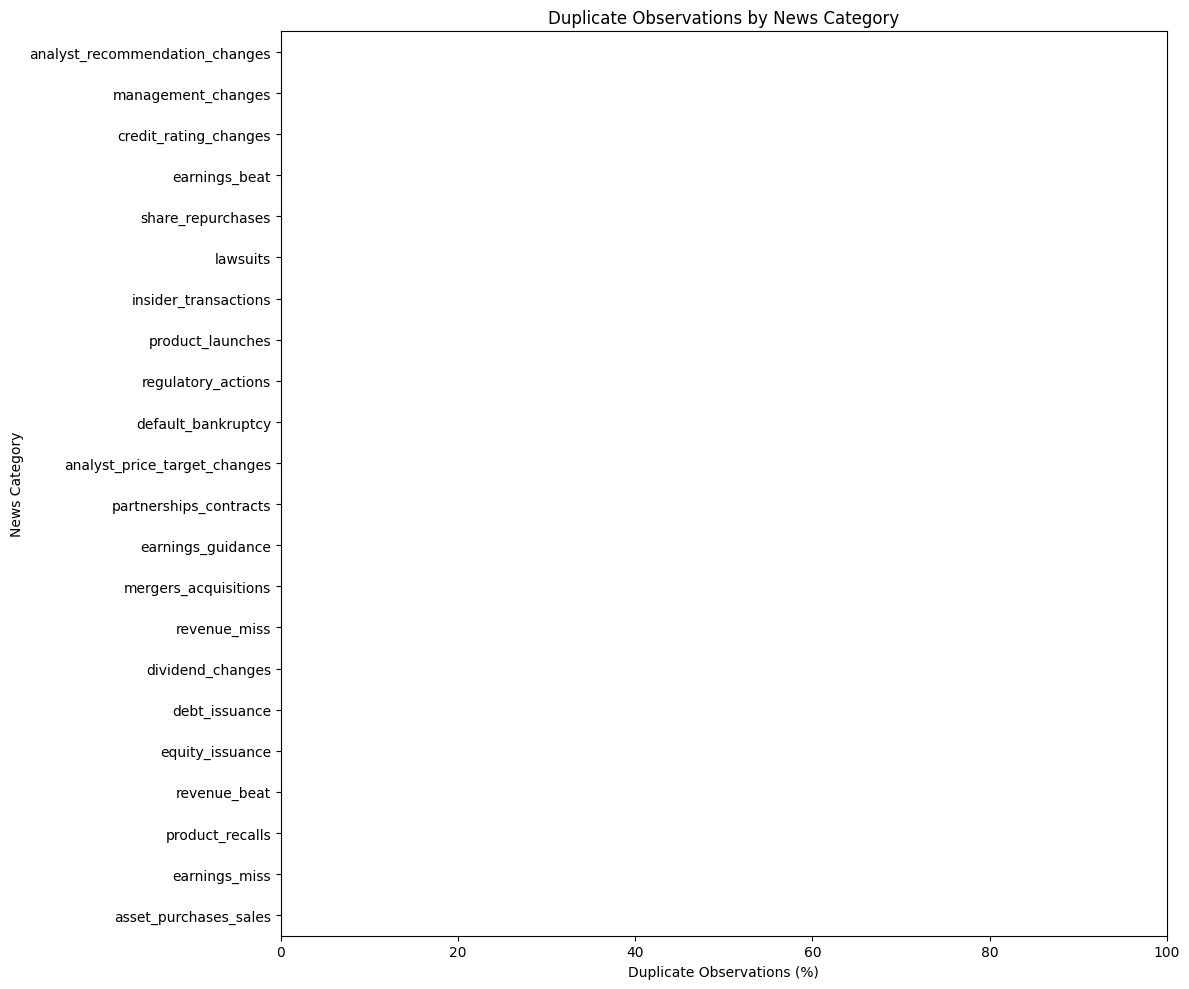

In [25]:
# 8.3.10 Visualize the Effect of Duplicate Removal

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))

sns.barplot(
    data=category_deduplication_summary,
    x="duplicate_percentage",
    y="model_category",
    color="steelblue"
)

plt.title("Duplicate Observations by News Category")
plt.xlabel("Duplicate Observations (%)")
plt.ylabel("News Category")

plt.xlim(0, 100)

plt.tight_layout()
plt.show()

### 8.3.11 Interpretation of Global Duplicate Results

The global duplicate analysis identified 600,847
unique security-event combinations across the
7,628,809 mapped news observations.

Approximately 92.12% of observations represented
additional records associated with repeated
security-event identifiers.

However, no completely identical observations
were identified when all 56 variables were
considered.

These findings indicate that observations sharing
the same security-event identifiers differ in
one or more original RavenPack variables.

Further investigation is required to determine
whether these differences represent meaningful
financial information or redundant reference
information.

No observations will be removed solely on the
basis of repeated event identifiers until these
differences have been examined.

### 8.4 Investigate Differences Within Repeated Event Records

Additional analysis is conducted to identify the
variables responsible for differences between
observations sharing the same security-event
identifiers.

The investigation distinguishes differences in
financial news characteristics from differences
in supporting reference information.

The results will establish whether repeated
observations can be consolidated without losing
relevant information for the machine learning models.

In [26]:
# 8.4.1 Define Comparison Variables

event_key = [
    "rp_story_id",
    "cusip",
    "rp_entity_id",
    "rp_story_event_index",
    "category",
    "timestamp_utc"
]

all_mapped_columns = con.execute("""
    DESCRIBE SELECT * FROM mapped_news
""").df()["column_name"].tolist()

comparison_columns = [
    col for col in all_mapped_columns
    if col not in event_key
]

print("Total variables:", len(all_mapped_columns))

print("Event identification variables:", len(event_key))

print("Variables to investigate:", len(comparison_columns))

display(comparison_columns)

Total variables: 56
Event identification variables: 6
Variables to investigate: 50


['rpa_date_utc',
 'rpa_time_utc',
 'entity_type',
 'entity_name',
 'country_code',
 'relevance',
 'event_sentiment_score',
 'event_relevance',
 'event_similarity_key',
 'event_similarity_days',
 'topic',
 'group',
 'type',
 'sub_type',
 'property',
 'fact_level',
 'rp_position_id',
 'position_name',
 'evaluation_method',
 'maturity',
 'earnings_type',
 'event_start_date_utc',
 'event_end_date_utc',
 'reporting_period',
 'reporting_start_date_utc',
 'reporting_end_date_utc',
 'related_entity',
 'relationship',
 'event_text',
 'news_type',
 'rp_source_id',
 'source_name',
 'css',
 'nip',
 'peq',
 'bee',
 'bmq',
 'bam',
 'bca',
 'ber',
 'anl_chg',
 'mcq',
 'rp_story_event_count',
 'product_key',
 'provider_id',
 'provider_story_id',
 'headline',
 'ticker',
 'isin',
 'model_category']

In [27]:
# 8.4.2 Identify Variables That Differ Within Event Keys

event_key_sql = ", ".join(event_key)

variable_difference_results = []

for i, col in enumerate(comparison_columns, start=1):

    quoted_col = '"' + col.replace('"', '""') + '"'

    differing_groups = con.execute(f"""
        SELECT COUNT(*)

        FROM (

            SELECT {event_key_sql}

            FROM mapped_news

            GROUP BY {event_key_sql}

            HAVING

                COUNT(DISTINCT {quoted_col})

                + CASE
                    WHEN COUNT(*) > COUNT({quoted_col})
                    THEN 1
                    ELSE 0
                  END

                > 1
        )
    """).fetchone()[0]

    variable_difference_results.append({

        "Variable": col,

        "Event Keys With Different Values":
            differing_groups,

        "Percentage of Repeated Keys (%)":
            differing_groups / 561_076 * 100

    })

    print(
        f"{i}/{len(comparison_columns)} | "
        f"{col}: {differing_groups:,}"
    )

variable_difference_summary = (

    pd.DataFrame(variable_difference_results)

    .sort_values(
        "Event Keys With Different Values",
        ascending=False
    )

    .reset_index(drop=True)
)

with pd.option_context("display.max_rows", None):

    display(variable_difference_summary.round(4))

1/50 | rpa_date_utc: 0
2/50 | rpa_time_utc: 0
3/50 | entity_type: 0
4/50 | entity_name: 0
5/50 | country_code: 0
6/50 | relevance: 0
7/50 | event_sentiment_score: 0
8/50 | event_relevance: 0
9/50 | event_similarity_key: 0
10/50 | event_similarity_days: 0
11/50 | topic: 0
12/50 | group: 0
13/50 | type: 0
14/50 | sub_type: 0
15/50 | property: 0
16/50 | fact_level: 0
17/50 | rp_position_id: 0
18/50 | position_name: 0
19/50 | evaluation_method: 0
20/50 | maturity: 0
21/50 | earnings_type: 0
22/50 | event_start_date_utc: 0
23/50 | event_end_date_utc: 0
24/50 | reporting_period: 0
25/50 | reporting_start_date_utc: 0
26/50 | reporting_end_date_utc: 0
27/50 | related_entity: 0
28/50 | relationship: 0
29/50 | event_text: 0
30/50 | news_type: 0
31/50 | rp_source_id: 0
32/50 | source_name: 0
33/50 | css: 0
34/50 | nip: 0
35/50 | peq: 0
36/50 | bee: 0
37/50 | bmq: 0
38/50 | bam: 0
39/50 | bca: 0
40/50 | ber: 0
41/50 | anl_chg: 0
42/50 | mcq: 0
43/50 | rp_story_event_count: 0
44/50 | product_key: 0

,Variable,Event Keys With Different Values,Percentage of Repeated Keys (%)
0,ticker,493199,87.9024
1,isin,382499,68.1724
2,rpa_date_utc,0,0.0000
3,bmq,0,0.0000
4,relationship,0,0.0000
5,event_text,0,0.0000
6,news_type,0,0.0000
7,rp_source_id,0,0.0000
8,source_name,0,0.0000
9,css,0,0.0000


In [28]:
# 8.4.3 Identify Consistent and Inconsistent Variables

varying_variables = variable_difference_summary.loc[

    variable_difference_summary[
        "Event Keys With Different Values"
    ] > 0,

    "Variable"

].tolist()

consistent_variables = variable_difference_summary.loc[

    variable_difference_summary[
        "Event Keys With Different Values"
    ] == 0,

    "Variable"

].tolist()

print(
    "Variables differing within event keys:",
    len(varying_variables)
)

display(varying_variables)

print(
    "Variables consistent within event keys:",
    len(consistent_variables)
)

display(consistent_variables)

Variables differing within event keys: 2


['ticker', 'isin']

Variables consistent within event keys: 48


['rpa_date_utc',
 'bmq',
 'relationship',
 'event_text',
 'news_type',
 'rp_source_id',
 'source_name',
 'css',
 'nip',
 'peq',
 'bee',
 'bca',
 'bam',
 'rpa_time_utc',
 'ber',
 'anl_chg',
 'mcq',
 'rp_story_event_count',
 'product_key',
 'provider_id',
 'provider_story_id',
 'headline',
 'related_entity',
 'reporting_end_date_utc',
 'reporting_start_date_utc',
 'reporting_period',
 'entity_type',
 'entity_name',
 'country_code',
 'relevance',
 'event_sentiment_score',
 'event_relevance',
 'event_similarity_key',
 'event_similarity_days',
 'topic',
 'group',
 'type',
 'sub_type',
 'property',
 'fact_level',
 'rp_position_id',
 'position_name',
 'evaluation_method',
 'maturity',
 'earnings_type',
 'event_start_date_utc',
 'event_end_date_utc',
 'model_category']

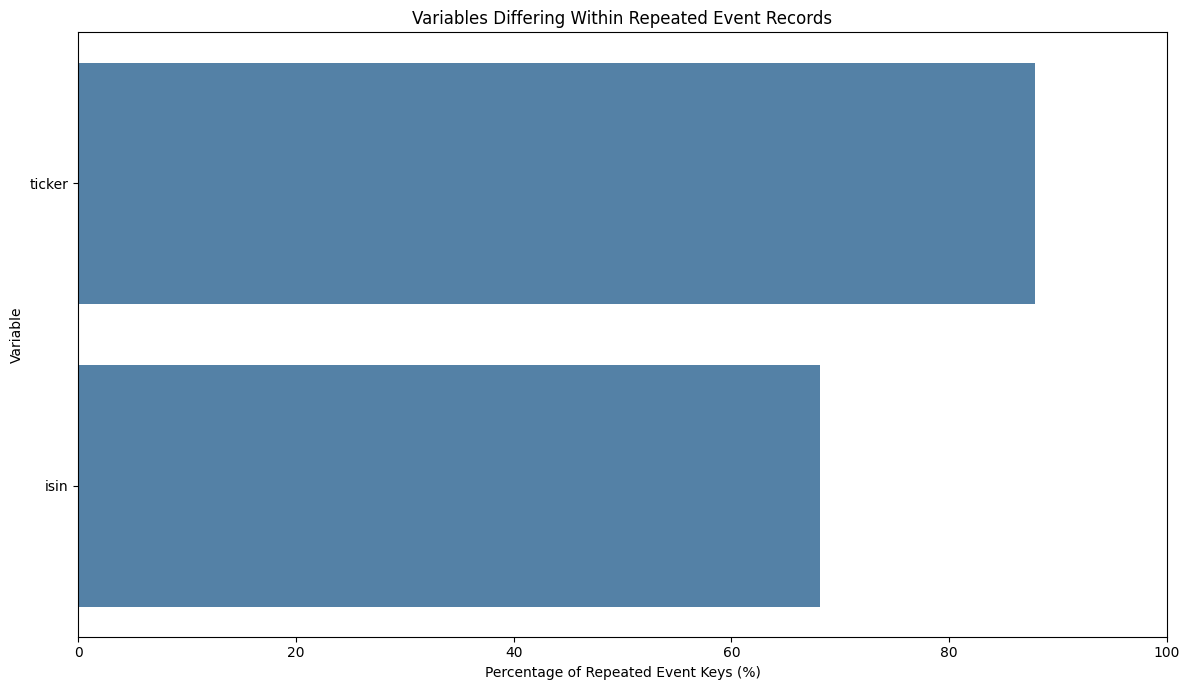

In [29]:
# 8.4.4 Visualize Sources of Repetition

varying_variable_summary = (
    variable_difference_summary[
        variable_difference_summary[
            "Event Keys With Different Values"
        ] > 0
    ]
)

if not varying_variable_summary.empty:

    plt.figure(figsize=(12, 7))

    sns.barplot(

        data=varying_variable_summary,

        x="Percentage of Repeated Keys (%)",

        y="Variable",

        color="steelblue"

    )

    plt.title(
        "Variables Differing Within Repeated Event Records"
    )

    plt.xlabel(
        "Percentage of Repeated Event Keys (%)"
    )

    plt.ylabel("Variable")

    plt.xlim(0, 100)

    plt.tight_layout()
    plt.show()

else:

    print("No differing variables identified.")

In [30]:
# 8.4.5 Validate Core News Information

core_news_variables = [
    "model_category",
    "relevance",
    "event_sentiment_score",
    "event_relevance",
    "event_similarity_days",
    "fact_level"
]

core_variable_validation = (

    variable_difference_summary

    .set_index("Variable")

    .loc[core_news_variables]

    .reset_index()

)

display(core_variable_validation.round(4))

core_conflicts = core_variable_validation[
    core_variable_validation[
        "Event Keys With Different Values"
    ] > 0
]

print(
    "Core news variables with conflicting values:",
    len(core_conflicts)
)

print(
    "Core news information consistent:",
    len(core_conflicts) == 0
)

,Variable,Event Keys With Different Values,Percentage of Repeated Keys (%)
0,model_category,0,0.0
1,relevance,0,0.0
2,event_sentiment_score,0,0.0
3,event_relevance,0,0.0
4,event_similarity_days,0,0.0
5,fact_level,0,0.0


Core news variables with conflicting values: 0
Core news information consistent: True


In [31]:
# 8.4.6 Examine Distinct Baseline News Records

baseline_source_columns = (
    event_key + core_news_variables
)

baseline_source_sql = ", ".join(
    baseline_source_columns
)

unique_baseline_records = con.execute(f"""
    SELECT COUNT(*)

    FROM (

        SELECT DISTINCT {baseline_source_sql}

        FROM mapped_news
    )
""").fetchone()[0]

print(
    "Original mapped observations:",
    f"{mapped_count:,}"
)

print(
    "Unique security-event combinations:",
    f"{600_847:,}"
)

print(
    "Unique baseline news records:",
    f"{unique_baseline_records:,}"
)

print(
    "Additional baseline records:",
    f"{unique_baseline_records - 600_847:,}"
)

print(
    "Potential redundant records:",
    f"{mapped_count - unique_baseline_records:,}"
)

print(
    "Baseline information consistent:",
    unique_baseline_records == 600_847
)

Original mapped observations: 7,628,809
Unique security-event combinations: 600,847
Unique baseline news records: 600,847
Additional baseline records: 0
Potential redundant records: 7,027,962
Baseline information consistent: True


In [32]:
# 8.4.7 Examine Repetition Frequency

repetition_distribution = con.execute(f"""
    WITH event_counts AS (

        SELECT

            {event_key_sql},

            COUNT(*) AS records_per_event

        FROM mapped_news

        GROUP BY {event_key_sql}

    )

    SELECT

        records_per_event,

        COUNT(*) AS number_of_events,

        SUM(records_per_event)
            AS total_observations

    FROM event_counts

    GROUP BY records_per_event

    ORDER BY records_per_event

""").df()

display(repetition_distribution)

print(
    "Total unique event keys:",
    f"{repetition_distribution['number_of_events'].sum():,}"
)

print(
    "Total mapped observations:",
    f"{int(repetition_distribution['total_observations'].sum()):,}"
)

,records_per_event,number_of_events,total_observations
0,1,39771,39771.0
1,2,86671,173342.0
2,3,106809,320427.0
3,4,53871,215484.0
4,5,11203,56015.0
5,6,79054,474324.0
6,7,1731,12117.0
7,8,30395,243160.0
8,9,17014,153126.0
9,10,15875,158750.0


Total unique event keys: 600,847
Total mapped observations: 7,628,809


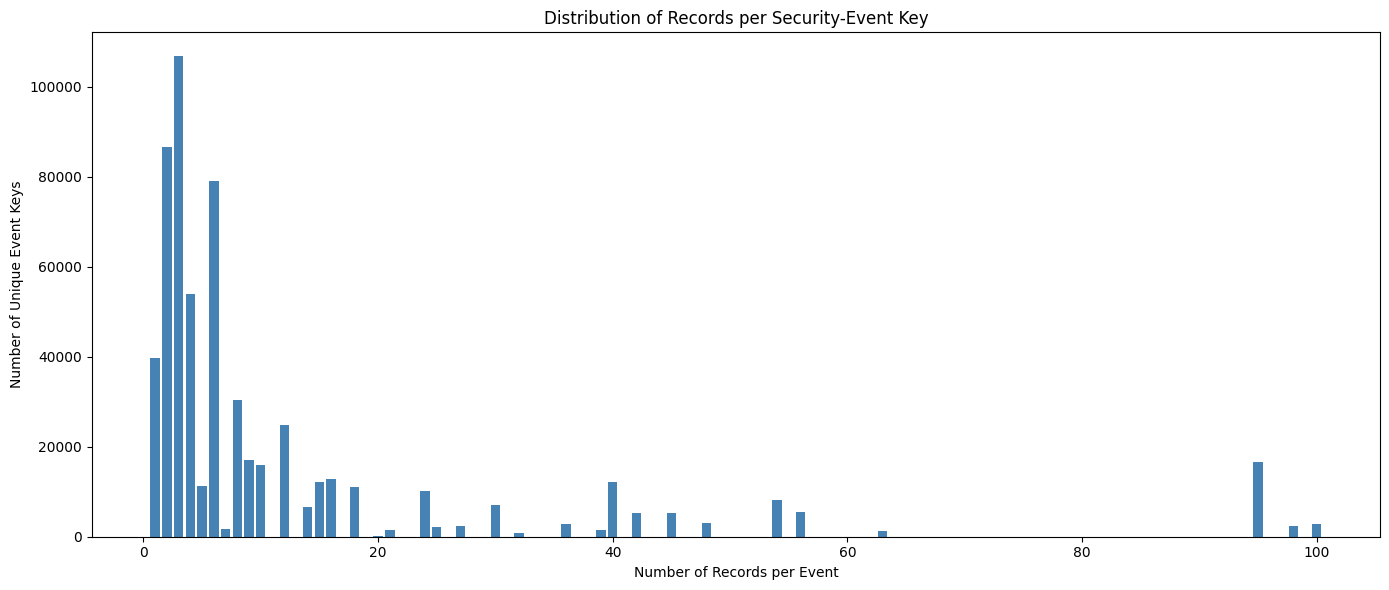

In [33]:
# 8.4.8 Visualize Repetition Frequency

plt.figure(figsize=(14, 6))

plt.bar(

    repetition_distribution["records_per_event"],

    repetition_distribution["number_of_events"],

    color="steelblue"

)

plt.title("Distribution of Records per Security-Event Key")

plt.xlabel("Number of Records per Event")

plt.ylabel("Number of Unique Event Keys")

plt.tight_layout()
plt.show()

### 8.4.9 Interpretation of Repeated Event Records

The investigation identified ticker and ISIN as
the only variables containing different values
within repeated security-event combinations.

The remaining 48 comparison variables were
consistent across repeated event records.

Ticker values differed within approximately
87.90% of repeated event keys, while ISIN values
differed within approximately 68.17%.

All six core news variables required to construct
the 53 baseline predictors demonstrated complete
consistency within each security-event combination.

A total of 600,847 unique baseline news records
were identified from the 7,628,809 mapped
observations.

These findings indicate that approximately 92.12%
of mapped observations can be consolidated without
losing baseline news predictor information.

Ticker and ISIN information will remain available
in the original dataset for reference purposes,
while the consolidated dataset will preserve
CUSIP and the remaining event information.

### 8.5 Consolidate Redundant Event Records

Following the identification of redundant reference
information, ticker and ISIN are excluded from
the consolidated news dataset.

Distinct observations are selected across the
remaining 54 variables.

This procedure preserves the financial news
information, event characteristics, sentiment
scores, security identifiers, and supporting
RavenPack signals.

The original mapped dataset and security reference
information remain available for future validation.

In [34]:
# 8.5.1 Define Consolidation Variables

redundant_reference_columns = [
    "ticker",
    "isin"
]

consolidated_columns = [

    col for col in all_mapped_columns

    if col not in redundant_reference_columns

]

print(
    "Original variables:",
    len(all_mapped_columns)
)

print(
    "Reference variables separated:",
    len(redundant_reference_columns)
)

print(
    "Variables retained:",
    len(consolidated_columns)
)

assert set(varying_variables) == set(
    redundant_reference_columns
)

assert len(consolidated_columns) == 54

Original variables: 56
Reference variables separated: 2
Variables retained: 54


In [35]:
# 8.5.2 Preserve Security Reference Information

security_reference_mapping = con.execute("""
    SELECT DISTINCT

        rp_entity_id,
        entity_name,
        cusip,
        ticker,
        isin

    FROM mapped_news

    ORDER BY rp_entity_id, cusip, ticker, isin

""").df()

security_reference_path = (

    output_folder /
    "ravenpack_security_reference.parquet"

)

security_reference_mapping.to_parquet(

    security_reference_path,

    index=False

)

print(
    "Security reference combinations:",
    f"{len(security_reference_mapping):,}"
)

print(
    "Reference variables:",
    len(security_reference_mapping.columns)
)

print(
    "Reference mapping saved:",
    security_reference_path.exists()
)

display(security_reference_mapping.head(15))

Security reference combinations: 3,795
Reference variables: 5
Reference mapping saved: True


,rp_entity_id,entity_name,cusip,ticker,isin
0,00067A,Humana Inc.,444859102,0J6Z,US4448591028
1,00067A,Humana Inc.,444859102,HUM,US4448591028
2,003B70,Realty Income Corp.,756109104,0KUE,AR0245808040
3,003B70,Realty Income Corp.,756109104,0KUE,BRR1INBDR000
4,003B70,Realty Income Corp.,756109104,0KUE,US7561091049
5,003B70,Realty Income Corp.,756109104,O,AR0245808040
6,003B70,Realty Income Corp.,756109104,O,BRR1INBDR000
7,003B70,Realty Income Corp.,756109104,O,US7561091049
8,003B70,Realty Income Corp.,756109104,R1IN34,AR0245808040
9,003B70,Realty Income Corp.,756109104,R1IN34,BRR1INBDR000


In [36]:
# 8.5.3 Construct the Consolidated Dataset

consolidated_output_path = (

    output_folder /
    "ravenpack_consolidated.parquet"

)

consolidated_temp_path = (

    output_folder /
    "ravenpack_consolidated_temp.parquet"

)

consolidated_temp_path.unlink(missing_ok=True)

sql_output_path = str(

    consolidated_temp_path.resolve()

).replace("'", "''")

consolidated_columns_sql = ", ".join(

    '"' + col.replace('"', '""') + '"'

    for col in consolidated_columns

)

con.execute(f"""
    COPY (

        SELECT DISTINCT

            {consolidated_columns_sql}

        FROM mapped_news

    )

    TO '{sql_output_path}'

    (
        FORMAT PARQUET,
        COMPRESSION SNAPPY
    )

""")

consolidated_parquet = pq.ParquetFile(
    consolidated_temp_path
)

consolidated_count = (
    consolidated_parquet.metadata.num_rows
)

assert consolidated_count == 600_847

assert (
    consolidated_parquet.metadata.num_columns
    == 54
)

consolidated_temp_path.replace(
    consolidated_output_path
)

print("Event consolidation completed.")

print(
    "Original mapped observations:",
    f"{mapped_count:,}"
)

print(
    "Consolidated observations:",
    f"{consolidated_count:,}"
)

print(
    "Redundant observations removed:",
    f"{mapped_count - consolidated_count:,}"
)

print(
    "Observation reduction (%):",
    round(
        (mapped_count - consolidated_count) /
        mapped_count * 100,
        4
    )
)

Event consolidation completed.
Original mapped observations: 7,628,809
Consolidated observations: 600,847
Redundant observations removed: 7,027,962
Observation reduction (%): 92.124


In [37]:
# 8.5.4 Validate the Consolidated Dataset

con.read_parquet(

    str(consolidated_output_path.resolve())

).create_view(

    "consolidated_news",

    replace=True

)

consolidated_unique_keys = con.execute(f"""
    SELECT COUNT(*)

    FROM (

        SELECT DISTINCT {event_key_sql}

        FROM consolidated_news
    )
""").fetchone()[0]

consolidation_validation = pd.DataFrame({

    "Validation Check": [

        "Expected Observation Count",

        "Expected Variable Count",

        "Unique Security-Event Keys",

        "Ticker Excluded",

        "ISIN Excluded",

        "Reference Mapping Preserved"

    ],

    "Passed": [

        consolidated_count == 600_847,

        len(consolidated_columns) == 54,

        consolidated_unique_keys ==
        consolidated_count,

        "ticker" not in consolidated_columns,

        "isin" not in consolidated_columns,

        security_reference_path.exists()

    ]

})

display(consolidation_validation)

print(
    "Overall consolidation validation:",
    consolidation_validation["Passed"].all()
)

print(
    "Remaining repeated event keys:",
    consolidated_count - consolidated_unique_keys
)

print(
    "Consolidated file size (MB):",
    round(
        consolidated_output_path.stat().st_size /
        1024**2,
        2
    )
)

,Validation Check,Passed
0,Expected Observation Count,True
1,Expected Variable Count,True
2,Unique Security-Event Keys,True
3,Ticker Excluded,True
4,ISIN Excluded,True
5,Reference Mapping Preserved,True


Overall consolidation validation: True
Remaining repeated event keys: 0
Consolidated file size (MB): 79.39


In [38]:
# 8.5.5 Validate Preservation of News Information

lost_information = con.execute(f"""
    SELECT COUNT(*)

    FROM (

        SELECT {consolidated_columns_sql}
        FROM mapped_news

        EXCEPT

        SELECT {consolidated_columns_sql}
        FROM consolidated_news

    )
""").fetchone()[0]

unexpected_information = con.execute(f"""
    SELECT COUNT(*)

    FROM (

        SELECT {consolidated_columns_sql}
        FROM consolidated_news

        EXCEPT

        SELECT {consolidated_columns_sql}
        FROM mapped_news

    )
""").fetchone()[0]

print(
    "Missing distinct news records:",
    lost_information
)

print(
    "Unexpected news records:",
    unexpected_information
)

print(
    "News information preservation:",
    lost_information == 0 and
    unexpected_information == 0
)

Missing distinct news records: 0
Unexpected news records: 0
News information preservation: True


In [39]:
# 8.5.6 Compare News Categories

category_consolidation_summary = con.execute("""
    WITH original_counts AS (

        SELECT

            model_category,

            COUNT(*) AS original_observations

        FROM mapped_news

        GROUP BY model_category

    ),

    consolidated_counts AS (

        SELECT

            model_category,

            COUNT(*) AS consolidated_observations

        FROM consolidated_news

        GROUP BY model_category

    )

    SELECT

        o.model_category,

        o.original_observations,

        c.consolidated_observations,

        o.original_observations -
        c.consolidated_observations
            AS redundant_observations,

        ROUND(

            100.0 *
            (
                o.original_observations -
                c.consolidated_observations
            ) /
            o.original_observations,

            4

        ) AS reduction_percentage

    FROM original_counts o

    JOIN consolidated_counts c

        ON o.model_category = c.model_category

    ORDER BY reduction_percentage DESC

""").df()

display(category_consolidation_summary)

print(
    "Categories retained:",
    len(category_consolidation_summary)
)

,model_category,original_observations,consolidated_observations,redundant_observations,reduction_percentage
0,product_launches,511013,24092,486921,95.2854
1,partnerships_contracts,1645522,81674,1563848,95.0366
2,regulatory_actions,349455,17482,331973,94.9974
3,product_recalls,29809,1508,28301,94.9411
4,lawsuits,654703,38134,616569,94.1754
5,revenue_miss,23904,1441,22463,93.9717
6,earnings_beat,112349,7677,104672,93.1668
7,default_bankruptcy,4750,339,4411,92.8632
8,earnings_miss,44471,3231,41240,92.7346
9,revenue_beat,31352,2391,28961,92.3737


Categories retained: 22


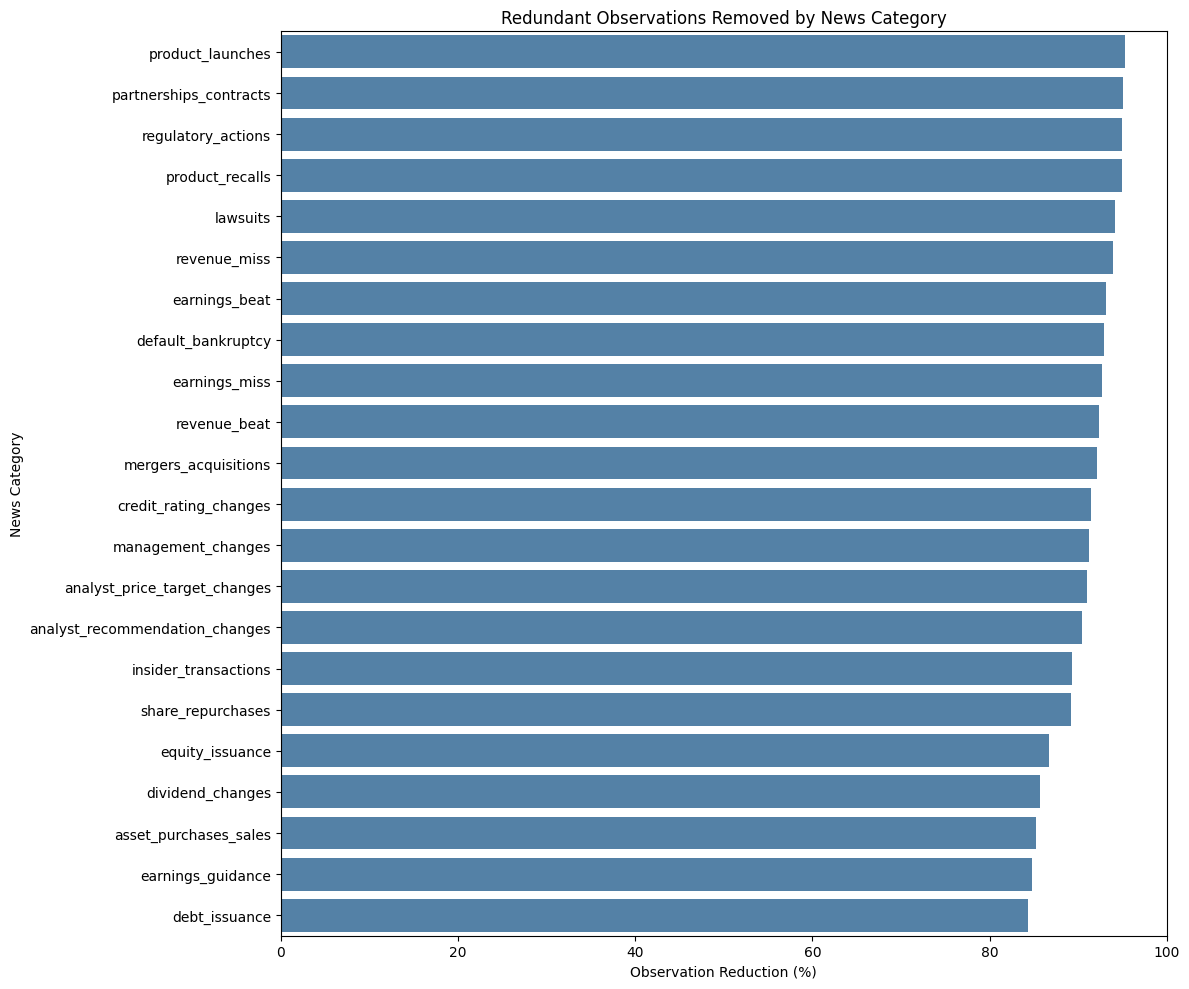

In [40]:
# 8.5.7 Visualize Redundant Observations by Category

plt.figure(figsize=(12, 10))

sns.barplot(

    data=category_consolidation_summary,

    x="reduction_percentage",

    y="model_category",

    color="steelblue"

)

plt.title(
    "Redundant Observations Removed by News Category"
)

plt.xlabel("Observation Reduction (%)")
plt.ylabel("News Category")

plt.xlim(0, 100)

plt.tight_layout()
plt.show()

In [41]:
# 8.5.8 Compare Category Distributions

category_distribution_comparison = (

    category_consolidation_summary.copy()

)

category_distribution_comparison[
    "Original Distribution (%)"
] = (

    category_distribution_comparison[
        "original_observations"
    ] / mapped_count * 100

)

category_distribution_comparison[
    "Consolidated Distribution (%)"
] = (

    category_distribution_comparison[
        "consolidated_observations"
    ] / consolidated_count * 100

)

category_distribution_comparison[
    "Change (Percentage Points)"
] = (

    category_distribution_comparison[
        "Consolidated Distribution (%)"
    ] -

    category_distribution_comparison[
        "Original Distribution (%)"
    ]

)

display(

    category_distribution_comparison[[

        "model_category",

        "Original Distribution (%)",

        "Consolidated Distribution (%)",

        "Change (Percentage Points)"

    ]].round(4)

)

,model_category,Original Distribution (%),Consolidated Distribution (%),Change (Percentage Points)
0,product_launches,6.6985,4.0097,-2.6888
1,partnerships_contracts,21.5698,13.5931,-7.9767
2,regulatory_actions,4.5807,2.9096,-1.6712
3,product_recalls,0.3907,0.2510,-0.1398
4,lawsuits,8.5820,6.3467,-2.2353
5,revenue_miss,0.3133,0.2398,-0.0735
6,earnings_beat,1.4727,1.2777,-0.1950
7,default_bankruptcy,0.0623,0.0564,-0.0058
8,earnings_miss,0.5829,0.5377,-0.0452
9,revenue_beat,0.4110,0.3979,-0.0130


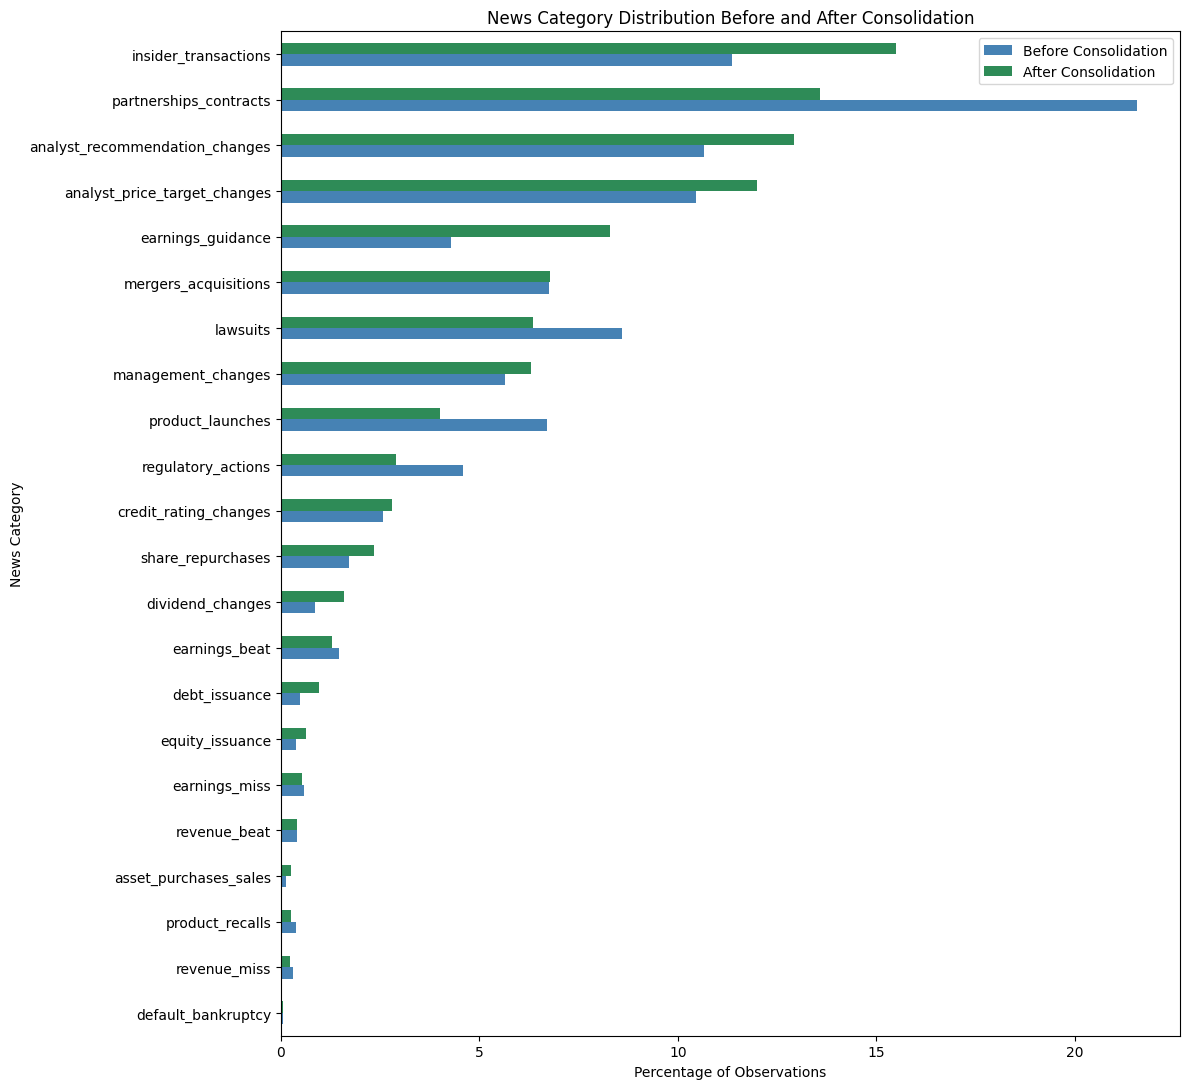

In [42]:
# 8.5.9 Visualize Category Distributions

distribution_plot = (

    category_distribution_comparison

    .set_index("model_category")[[

        "Original Distribution (%)",

        "Consolidated Distribution (%)"

    ]]

    .sort_values(

        "Consolidated Distribution (%)",

        ascending=True

    )

)

distribution_plot.plot(

    kind="barh",

    figsize=(12, 11),

    color=["steelblue", "seagreen"]

)

plt.title(
    "News Category Distribution Before and After Consolidation"
)

plt.xlabel("Percentage of Observations")
plt.ylabel("News Category")

plt.legend([
    "Before Consolidation",
    "After Consolidation"
])

plt.tight_layout()
plt.show()

### 8.5.10 Interpretation of Consolidation Results

The consolidation process successfully reduced
the mapped dataset from 7,628,809 observations
to 600,847 unique security-event observations.

A total of 7,027,962 redundant observations
were removed, representing approximately
92.12% of the mapped dataset.

All consolidation and information preservation
checks were satisfied. No distinct news records
were lost across the 54 retained variables.

The consolidation also identified substantial
changes in the relative representation of
standardized news categories.

Partnerships and contracts demonstrated the
largest decrease in relative representation,
while insider transactions and earnings guidance
demonstrated substantial increases.

These findings illustrate the importance of
identifying redundant reference information
before training machine learning models.

The consolidated dataset retains all 22
standardized news categories and will be used
to construct the final news predictors.

### 8.6 Full Dataset Feature Construction

Following the successful consolidation of
redundant observations, the validated feature
engineering methodology is applied to the
complete consolidated news dataset.

The final baseline feature structure consists
of 53 numerical predictors describing news
categories, event characteristics, fact levels,
novelty, and sentiment interactions.

Identification and supporting variables are
retained separately from the baseline predictors
to facilitate financial data integration and
additional model testing.

In [43]:
# 8.6.1 Restore the Original Feature Structure

target_categories = [
    "earnings_beat",
    "earnings_miss",
    "revenue_beat",
    "revenue_miss",
    "earnings_guidance",
    "dividend_changes",
    "share_repurchases",
    "equity_issuance",
    "debt_issuance",
    "credit_rating_changes",
    "default_bankruptcy",
    "mergers_acquisitions",
    "asset_purchases_sales",
    "analyst_recommendation_changes",
    "analyst_price_target_changes",
    "management_changes",
    "insider_transactions",
    "lawsuits",
    "regulatory_actions",
    "product_launches",
    "product_recalls",
    "partnerships_contracts"
]

category_features = target_categories.copy()

numerical_features = [
    "relevance",
    "event_sentiment_score",
    "event_relevance",
    "event_similarity_days"
]

fact_features = [
    "is_fact",
    "is_forecast",
    "is_opinion"
]

novelty_features = [
    "novel_1day",
    "novel_7days"
]

interaction_features = [
    f"{category}_sentiment"
    for category in target_categories
]

baseline_news_features = (
    category_features +
    numerical_features +
    fact_features +
    novelty_features +
    interaction_features
)

print("News categories:", len(category_features))
print("Numerical predictors:", len(numerical_features))
print("Fact-level indicators:", len(fact_features))
print("Novelty indicators:", len(novelty_features))
print("Sentiment interactions:", len(interaction_features))
print("Total baseline predictors:", len(baseline_news_features))

assert len(baseline_news_features) == 53
assert len(set(baseline_news_features)) == 53

News categories: 22
Numerical predictors: 4
Fact-level indicators: 3
Novelty indicators: 2
Sentiment interactions: 22
Total baseline predictors: 53


In [44]:
# 8.6.2 Define Identification and Supporting Variables

identifier_columns = [
    "rp_entity_id",
    "cusip",
    "rp_story_id",
    "rp_story_event_index",
    "timestamp_utc",
    "category",
    "model_category",
    "event_similarity_key"
]

supporting_features = [
    "fact_level",
    "news_type",
    "rp_source_id",
    "source_name",
    "css",
    "nip",
    "peq",
    "bee",
    "bmq",
    "bam",
    "bca",
    "ber",
    "anl_chg",
    "mcq"
]

source_columns = (
    identifier_columns +
    numerical_features +
    supporting_features
)

print("Identification variables:", len(identifier_columns))
print("Supporting variables:", len(supporting_features))
print("Original numerical predictors:", len(numerical_features))
print("Total source variables:", len(source_columns))

assert len(source_columns) == len(set(source_columns))

Identification variables: 8
Supporting variables: 14
Original numerical predictors: 4
Total source variables: 26


In [45]:
# 8.6.3 Load the Consolidated Dataset

import gc

gc.collect()

full_feature_df = pd.read_parquet(
    consolidated_output_path,
    columns=source_columns
)

print("Observations:", f"{len(full_feature_df):,}")
print("Initial variables:", len(full_feature_df.columns))

print(
    "DataFrame memory (MB):",
    round(
        full_feature_df.memory_usage(deep=True).sum()
        / 1024**2,
        2
    )
)

display(full_feature_df.head())

Observations: 600,847
Initial variables: 26
DataFrame memory (MB): 853.03


,rp_entity_id,cusip,rp_story_id,rp_story_event_index,timestamp_utc,category,model_category,event_similarity_key,relevance,event_sentiment_score,...,css,nip,peq,bee,bmq,bam,bca,ber,anl_chg,mcq
0,0157B1,023135106,765F64227167E0110AE41C3799ADEF26,2,2022-09-13 12:55:46.478,partnership,partnerships_contracts,E01BF308626AA4B2B2A92C4F4BF61569,93,0.49,...,0,-0.14,0,0,0,0,0,0,0,0
1,0157B1,023135106,24B099CB42C7007438D74723EB782342,3,2022-09-13 17:25:00.371,product-release,product_launches,B17937E768F22C0A69F9D97194C6C250,99,0.52,...,0,-0.4,0,0,0,0,0,1,0,0
2,0157B1,023135106,CD803C4BD28D9CC23B237EE376DE0AB7,3,2022-09-13 17:25:00.423,product-release,product_launches,B17937E768F22C0A69F9D97194C6C250,99,0.52,...,0,-0.3,0,0,0,0,0,1,0,0
3,0157B1,023135106,B048095FBE99C2049251FD43C2E85B17,1,2022-09-14 11:35:00.342,business-contract,partnerships_contracts,AE61837995B97314DC7445E2563D0E77,99,0.39,...,0.1,-0.26,1,0,0,0,0,0,0,0
4,0157B1,023135106,466BF499E1393C427DEA7E93C27081E1,1,2022-09-14 16:30:00.275,product-release,product_launches,B17937E768F22C0A69F9D97194C6C250,100,0.52,...,0.06,-0.26,1,0,1,0,0,0,0,1


In [46]:
# 8.6.4 Convert and Validate Data Types

additional_numeric = [
    "css",
    "nip"
]

discrete_signals = [
    "peq",
    "bee",
    "bmq",
    "bam",
    "bca",
    "ber",
    "anl_chg",
    "mcq"
]

# Convert numerical variables
for col in numerical_features + additional_numeric:

    full_feature_df[col] = pd.to_numeric(
        full_feature_df[col],
        errors="coerce"
    ).astype("float64")

# Convert discrete signals
for col in discrete_signals:

    full_feature_df[col] = pd.to_numeric(
        full_feature_df[col],
        errors="coerce"
    ).astype("Int8")

# Convert UTC timestamps
full_feature_df["timestamp_utc"] = pd.to_datetime(
    full_feature_df["timestamp_utc"],
    format="mixed",
    errors="coerce",
    utc=True
)

# Convert selected categorical variables
for col in [
    "category",
    "model_category",
    "fact_level",
    "news_type",
    "source_name"
]:

    full_feature_df[col] = (
        full_feature_df[col].astype("category")
    )

display(full_feature_df.dtypes.to_frame("Data Type"))

print(
    "Invalid timestamps:",
    full_feature_df["timestamp_utc"].isna().sum()
)

print(
    "Missing core numerical values:",
    full_feature_df[numerical_features].isna().sum().sum()
)

,Data Type
rp_entity_id,object
cusip,object
rp_story_id,object
rp_story_event_index,object
timestamp_utc,"datetime64[ns, UTC]"
category,category
model_category,category
event_similarity_key,object
relevance,float64
event_sentiment_score,float64


Invalid timestamps: 0
Missing core numerical values: 0


In [47]:
# 8.6.5 Validate Source Variables

source_validation = {

    "Expected Observation Count":
        len(full_feature_df) == 600_847,

    "All 22 Categories Represented":
        set(full_feature_df["model_category"].dropna())
        == set(target_categories),

    "Valid Fact Levels":
        full_feature_df["fact_level"].isin([
            "fact", "forecast", "opinion"
        ]).all(),

    "Valid Entity Relevance":
        full_feature_df["relevance"].between(
            0, 100
        ).all(),

    "Valid Event Relevance":
        full_feature_df["event_relevance"].between(
            0, 100
        ).all(),

    "Valid Sentiment Scores":
        full_feature_df["event_sentiment_score"]
        .between(-1, 1).all(),

    "Valid Event Similarity Values":
        full_feature_df["event_similarity_days"]
        .between(0, 365).all(),

    "Valid Timestamps":
        full_feature_df["timestamp_utc"].notna().all(),

    "Complete Numerical Predictors":
        full_feature_df[numerical_features]
        .notna().all().all()

}

source_validation_report = pd.DataFrame({

    "Validation Check": list(source_validation.keys()),

    "Passed": list(source_validation.values())

})

display(source_validation_report)

print(
    "Overall source validation:",
    source_validation_report["Passed"].all()
)

assert source_validation_report["Passed"].all()

,Validation Check,Passed
0,Expected Observation Count,True
1,All 22 Categories Represented,True
2,Valid Fact Levels,True
3,Valid Entity Relevance,True
4,Valid Event Relevance,True
5,Valid Sentiment Scores,True
6,Valid Event Similarity Values,True
7,Valid Timestamps,True
8,Complete Numerical Predictors,True


Overall source validation: True


In [48]:
# 8.6.6 Construct All Baseline Predictors

# Construct news category indicators
for category in target_categories:

    full_feature_df[category] = (
        full_feature_df["model_category"] == category
    ).astype("int8")


# Construct fact-level indicators
fact_level_mapping = {
    "fact": "is_fact",
    "forecast": "is_forecast",
    "opinion": "is_opinion"
}

for original_value, feature_name in fact_level_mapping.items():

    full_feature_df[feature_name] = (
        full_feature_df["fact_level"] == original_value
    ).astype("int8")


# Construct novelty indicators
novelty_thresholds = {
    "novel_1day": 1,
    "novel_7days": 7
}

for feature_name, threshold in novelty_thresholds.items():

    full_feature_df[feature_name] = (
        full_feature_df["event_similarity_days"] >= threshold
    ).astype("int8")


# Construct sentiment interactions
for category in target_categories:

    feature_name = f"{category}_sentiment"

    full_feature_df[feature_name] = np.where(

        full_feature_df[category] == 1,

        full_feature_df["event_sentiment_score"],

        0.0

    ).astype("float32")


print("Feature construction completed.")

print("Observations:", f"{len(full_feature_df):,}")

print(
    "Baseline predictors:",
    len(baseline_news_features)
)

print(
    "Total variables:",
    len(full_feature_df.columns)
)

Feature construction completed.
Observations: 600,847
Baseline predictors: 53
Total variables: 75


In [49]:
# 8.6.7 Validate the Complete Feature Structure

missing_features = [
    col for col in baseline_news_features
    if col not in full_feature_df.columns
]

final_column_order = (
    identifier_columns +
    baseline_news_features +
    supporting_features
)

print("Expected total variables:", len(final_column_order))

print("Missing baseline predictors:", missing_features)

print(
    "Duplicate variable names:",
    len(final_column_order) -
    len(set(final_column_order))
)

print(
    "All required variables available:",
    set(final_column_order).issubset(
        full_feature_df.columns
    )
)

assert len(final_column_order) == 75

assert len(set(final_column_order)) == 75

assert len(missing_features) == 0

Expected total variables: 75
Missing baseline predictors: []
Duplicate variable names: 0
All required variables available: True


In [50]:
# 8.6.8 Validate Encoded Features

category_valid = (
    full_feature_df[category_features].sum(axis=1) == 1
).all()

fact_valid = (
    full_feature_df[fact_features].sum(axis=1) == 1
).all()

novelty_valid = (
    full_feature_df["novel_7days"] <=
    full_feature_df["novel_1day"]
).all()

sentiment_valid = np.isclose(

    full_feature_df[interaction_features]
    .sum(axis=1)
    .to_numpy(dtype=float),

    full_feature_df["event_sentiment_score"]
    .to_numpy(dtype=float),

    atol=1e-7

).all()

missing_count = (
    full_feature_df[baseline_news_features]
    .isna().sum().sum()
)

# Validate infinite values without constructing
# another full feature matrix in memory
infinite_count = sum(

    np.isinf(
        full_feature_df[col].to_numpy(dtype=float)
    ).sum()

    for col in baseline_news_features
)

full_validation_checks = {

    "Expected Observation Count":
        len(full_feature_df) == 600_847,

    "Correct Number of Predictors":
        len(baseline_news_features) == 53,

    "Unique Predictor Names":
        len(set(baseline_news_features)) == 53,

    "Valid Category Indicators":
        category_valid,

    "Valid Fact-Level Indicators":
        fact_valid,

    "Valid Novelty Indicators":
        novelty_valid,

    "Valid Sentiment Interactions":
        sentiment_valid,

    "No Missing Predictor Values":
        missing_count == 0,

    "No Infinite Predictor Values":
        infinite_count == 0,

    "Unique Security-Event Keys":
        not full_feature_df.duplicated(
            subset=event_key
        ).any()

}

full_validation_report = pd.DataFrame({

    "Validation Check":
        list(full_validation_checks.keys()),

    "Passed":
        list(full_validation_checks.values())

})

display(full_validation_report)

print(
    "Validation checks passed:",
    f"{full_validation_report['Passed'].sum()} / "
    f"{len(full_validation_report)}"
)

print(
    "Overall full feature validation:",
    full_validation_report["Passed"].all()
)

assert full_validation_report["Passed"].all()

gc.collect()

,Validation Check,Passed
0,Expected Observation Count,True
1,Correct Number of Predictors,True
2,Unique Predictor Names,True
3,Valid Category Indicators,True
4,Valid Fact-Level Indicators,True
5,Valid Novelty Indicators,True
6,Valid Sentiment Interactions,True
7,No Missing Predictor Values,True
8,No Infinite Predictor Values,True
9,Unique Security-Event Keys,True


Validation checks passed: 10 / 10
Overall full feature validation: True


6772

In [51]:
# 8.6.9 Identify Constant Predictors

full_feature_summary = pd.DataFrame({

    "Data Type": (
        full_feature_df[baseline_news_features]
        .dtypes.astype(str)
    ),

    "Missing Observations": (
        full_feature_df[baseline_news_features]
        .isna().sum()
    ),

    "Unique Values": (
        full_feature_df[baseline_news_features]
        .nunique()
    ),

    "Mean": (
        full_feature_df[baseline_news_features]
        .mean()
    ),

    "Standard Deviation": (
        full_feature_df[baseline_news_features]
        .std()
    ),

    "Minimum": (
        full_feature_df[baseline_news_features]
        .min()
    ),

    "Maximum": (
        full_feature_df[baseline_news_features]
        .max()
    )

})

with pd.option_context("display.max_rows", None):

    display(full_feature_summary.round(6))

full_constant_features = full_feature_summary[
    full_feature_summary["Unique Values"] <= 1
]

print(
    "Constant predictors:",
    len(full_constant_features)
)

display(full_constant_features)

,Data Type,Missing Observations,Unique Values,Mean,Standard Deviation,Minimum,Maximum
earnings_beat,int8,0,2,0.012777,0.112311,0.00,1.00
earnings_miss,int8,0,2,0.005377,0.073133,0.00,1.00
revenue_beat,int8,0,2,0.003979,0.062957,0.00,1.00
revenue_miss,int8,0,2,0.002398,0.048914,0.00,1.00
earnings_guidance,int8,0,2,0.082818,0.275607,0.00,1.00
dividend_changes,int8,0,2,0.015856,0.124918,0.00,1.00
share_repurchases,int8,0,2,0.023580,0.151737,0.00,1.00
equity_issuance,int8,0,2,0.006268,0.078921,0.00,1.00
debt_issuance,int8,0,2,0.009598,0.097499,0.00,1.00
credit_rating_changes,int8,0,2,0.027966,0.164874,0.00,1.00


Constant predictors: 1


,Data Type,Missing Observations,Unique Values,Mean,Standard Deviation,Minimum,Maximum
debt_issuance_sentiment,float32,0,1,0.0,0.0,0.0,0.0


### 8.6.10 Interpretation of Full Feature Construction

The validated feature engineering methodology was
successfully applied to all 600,847 consolidated
security-event observations.

The resulting dataset contains 75 variables,
consisting of 53 baseline news predictors,
eight identification variables, and 14 supporting
variables.

All source and feature validation checks were
satisfied. No missing predictor values, infinite
values, invalid feature encodings, or repeated
security-event identifiers were identified.

Differences were observed between the descriptive
statistics of the original analysis sample and
the consolidated dataset.

One constant predictor, debt_issuance_sentiment,
was identified across the complete dataset.

The predictor will remain in the exported feature
structure to maintain consistency with the original
modeling specification.

Additional statistical analysis will be conducted
using the consolidated dataset to account for the
effects of redundant observations on the earlier
exploratory results.

### 8.7 Updated Statistical Analysis

Following the consolidation of redundant news
observations, the numerical and categorical
relationships are reexamined using the complete
consolidated dataset.

The updated analysis includes descriptive
statistics, Pearson and Spearman correlations,
categorical associations, and sentiment
distributions.

The purpose of this analysis is to determine
whether the removal of redundant observations
influences the relationships identified during
the initial exploratory data analysis.

The updated results provide a more appropriate
description of the consolidated security-event
dataset.

In [52]:
# 8.7.1 Updated Numerical Descriptive Statistics

analysis_numeric = [
    "relevance",
    "event_sentiment_score",
    "event_relevance",
    "event_similarity_days",
    "css",
    "nip"
]

updated_numerical_summary = (
    full_feature_df[analysis_numeric]
    .describe()
    .T
)

updated_numerical_summary["Missing Observations"] = (
    full_feature_df[analysis_numeric]
    .isna().sum()
)

updated_numerical_summary["Missing (%)"] = (
    full_feature_df[analysis_numeric]
    .isna().mean() * 100
)

updated_numerical_summary["Unique Values"] = (
    full_feature_df[analysis_numeric]
    .nunique()
)

display(updated_numerical_summary.round(4))

,count,mean,std,min,25%,50%,75%,max,Missing Observations,Missing (%),Unique Values
relevance,600847.0,99.5446,1.2134,90.00,99.0000,100.000,100.0000,100.00,0,0.0,11
event_sentiment_score,600847.0,0.1745,0.4766,-1.00,0.0000,0.390,0.5300,1.00,0,0.0,145
event_relevance,600847.0,84.2237,24.0450,0.00,70.0000,100.000,100.0000,100.00,0,0.0,64
event_similarity_days,600847.0,76.0322,136.2579,0.00,0.0042,0.104,73.7626,365.00,0,0.0,189410
css,600847.0,0.0075,0.0890,-0.92,0.0000,0.000,0.0400,1.00,0,0.0,30
nip,600847.0,-0.1238,0.2098,-0.82,-0.2600,-0.160,-0.0200,0.96,0,0.0,90


In [53]:
# 8.7.2 Compare Numerical Statistics

original_numerical_means = pd.Series({

    "relevance": 99.4047,

    "event_sentiment_score": 0.1882,

    "event_relevance": 80.9004,

    "event_similarity_days": 62.1697,

    "css": 0.0099,

    "nip": -0.1392

})

numerical_comparison = pd.DataFrame({

    "Original Sample Mean":
        original_numerical_means,

    "Consolidated Mean":
        full_feature_df[analysis_numeric].mean()

})

numerical_comparison["Difference"] = (

    numerical_comparison["Consolidated Mean"] -

    numerical_comparison["Original Sample Mean"]

)

display(numerical_comparison.round(4))

,Original Sample Mean,Consolidated Mean,Difference
relevance,99.4047,99.5446,0.1399
event_sentiment_score,0.1882,0.1745,-0.0137
event_relevance,80.9004,84.2237,3.3233
event_similarity_days,62.1697,76.0322,13.8625
css,0.0099,0.0075,-0.0024
nip,-0.1392,-0.1238,0.0154


,relevance,event_sentiment_score,event_relevance,event_similarity_days,css,nip
relevance,1.0000,-0.0270,0.3337,0.0499,-0.0152,0.0753
event_sentiment_score,-0.0270,1.0000,-0.0817,0.0336,0.4821,0.0242
event_relevance,0.3337,-0.0817,1.0000,0.0357,-0.0955,-0.0553
event_similarity_days,0.0499,0.0336,0.0357,1.0000,0.0042,0.0317
css,-0.0152,0.4821,-0.0955,0.0042,1.0000,0.0566
nip,0.0753,0.0242,-0.0553,0.0317,0.0566,1.0000


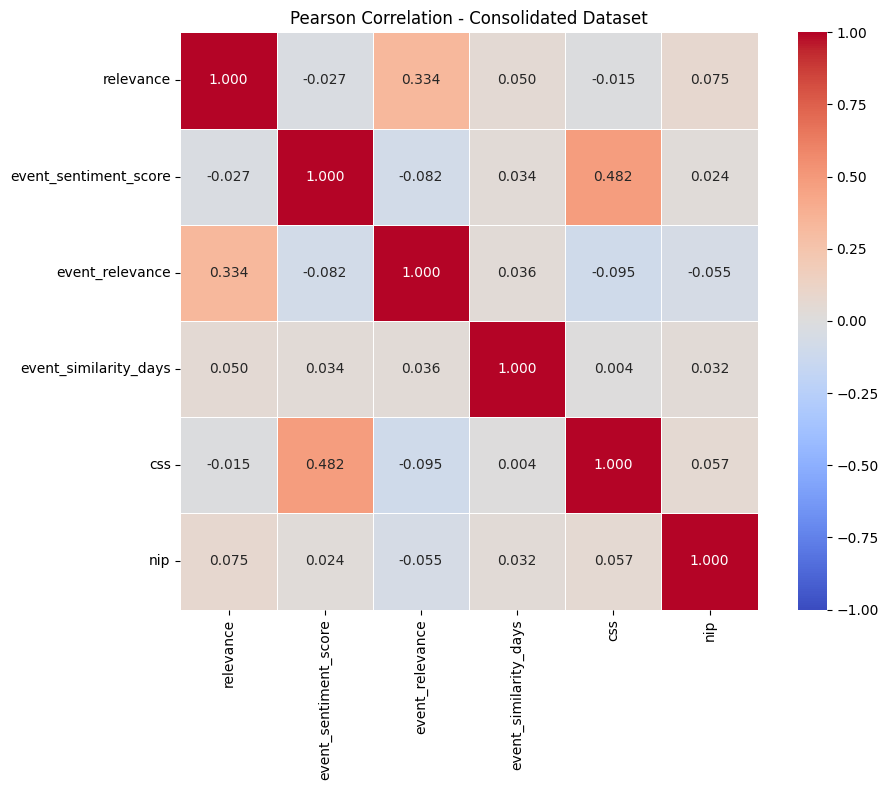

In [54]:
# 8.7.3 Updated Pearson Correlation Matrix

updated_pearson = (
    full_feature_df[analysis_numeric]
    .corr(method="pearson")
)

display(updated_pearson.round(4))

plt.figure(figsize=(10, 8))

sns.heatmap(

    updated_pearson,

    annot=True,

    fmt=".3f",

    cmap="coolwarm",

    center=0,

    vmin=-1,

    vmax=1,

    square=True,

    linewidths=0.5

)

plt.title("Pearson Correlation - Consolidated Dataset")

plt.tight_layout()
plt.show()

,relevance,event_sentiment_score,event_relevance,event_similarity_days,css,nip
relevance,1.0000,-0.0205,0.7034,0.0680,0.0051,0.1319
event_sentiment_score,-0.0205,1.0000,-0.0833,-0.0480,0.4957,0.0502
event_relevance,0.7034,-0.0833,1.0000,0.0595,-0.0797,-0.0077
event_similarity_days,0.0680,-0.0480,0.0595,1.0000,-0.0423,0.0738
css,0.0051,0.4957,-0.0797,-0.0423,1.0000,0.1079
nip,0.1319,0.0502,-0.0077,0.0738,0.1079,1.0000


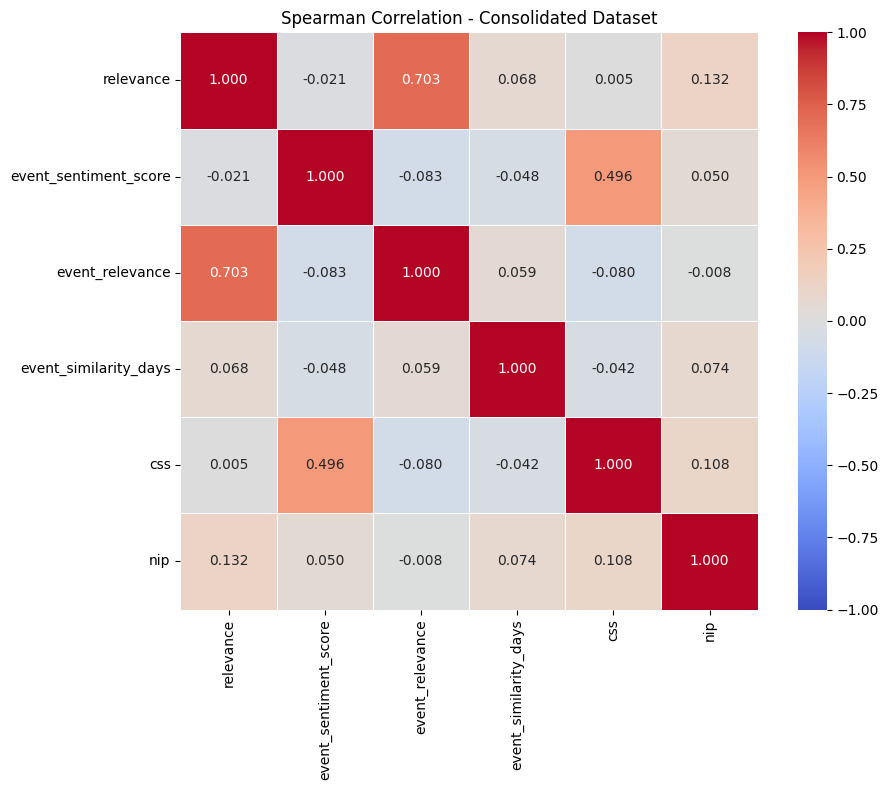

In [55]:
# 8.7.4 Updated Spearman Correlation Matrix

updated_spearman = (
    full_feature_df[analysis_numeric]
    .corr(method="spearman")
)

display(updated_spearman.round(4))

plt.figure(figsize=(10, 8))

sns.heatmap(

    updated_spearman,

    annot=True,

    fmt=".3f",

    cmap="coolwarm",

    center=0,

    vmin=-1,

    vmax=1,

    square=True,

    linewidths=0.5

)

plt.title("Spearman Correlation - Consolidated Dataset")

plt.tight_layout()
plt.show()

In [56]:
# 8.7.5 Identify Strongest Numerical Relationships

from itertools import combinations

updated_correlation_results = []

for col1, col2 in combinations(
    analysis_numeric, 2
):

    updated_correlation_results.append({

        "Variable 1": col1,

        "Variable 2": col2,

        "Pearson":
            updated_pearson.loc[col1, col2],

        "Spearman":
            updated_spearman.loc[col1, col2]

    })

updated_correlation_summary = pd.DataFrame(
    updated_correlation_results
)

updated_correlation_summary["Absolute Pearson"] = (
    updated_correlation_summary["Pearson"].abs()
)

updated_correlation_summary["Absolute Spearman"] = (
    updated_correlation_summary["Spearman"].abs()
)

updated_correlation_summary = (

    updated_correlation_summary

    .sort_values(
        "Absolute Pearson",
        ascending=False
    )

    .reset_index(drop=True)

)

display(updated_correlation_summary.round(4))

high_updated_correlation = (
    updated_correlation_summary[
        (
            updated_correlation_summary["Absolute Pearson"]
            >= 0.80
        ) |
        (
            updated_correlation_summary["Absolute Spearman"]
            >= 0.80
        )
    ]
)

print(
    "Highly correlated variable pairs:",
    len(high_updated_correlation)
)

display(high_updated_correlation.round(4))

,Variable 1,Variable 2,Pearson,Spearman,Absolute Pearson,Absolute Spearman
0,event_sentiment_score,css,0.4821,0.4957,0.4821,0.4957
1,relevance,event_relevance,0.3337,0.7034,0.3337,0.7034
2,event_relevance,css,-0.0955,-0.0797,0.0955,0.0797
3,event_sentiment_score,event_relevance,-0.0817,-0.0833,0.0817,0.0833
4,relevance,nip,0.0753,0.1319,0.0753,0.1319
5,css,nip,0.0566,0.1079,0.0566,0.1079
6,event_relevance,nip,-0.0553,-0.0077,0.0553,0.0077
7,relevance,event_similarity_days,0.0499,0.0680,0.0499,0.0680
8,event_relevance,event_similarity_days,0.0357,0.0595,0.0357,0.0595
9,event_sentiment_score,event_similarity_days,0.0336,-0.0480,0.0336,0.0480


Highly correlated variable pairs: 0


,Variable 1,Variable 2,Pearson,Spearman,Absolute Pearson,Absolute Spearman


In [57]:
# 8.7.6 Compare Key Correlation Relationships

correlation_comparison = pd.DataFrame({

    "Relationship": [

        "Relevance and Event Relevance",

        "Event Sentiment and CSS"

    ],

    "Original Pearson": [
        0.3419,
        0.4299
    ],

    "Consolidated Pearson": [

        updated_pearson.loc[
            "relevance",
            "event_relevance"
        ],

        updated_pearson.loc[
            "event_sentiment_score",
            "css"
        ]

    ],

    "Original Spearman": [
        0.7250,
        0.4306
    ],

    "Consolidated Spearman": [

        updated_spearman.loc[
            "relevance",
            "event_relevance"
        ],

        updated_spearman.loc[
            "event_sentiment_score",
            "css"
        ]

    ]

})

display(correlation_comparison.round(4))

,Relationship,Original Pearson,Consolidated Pearson,Original Spearman,Consolidated Spearman
0,Relevance and Event Relevance,0.3419,0.3337,0.7250,0.7034
1,Event Sentiment and CSS,0.4299,0.4821,0.4306,0.4957


In [58]:
# 8.7.7 Updated Cramer's V Function

from scipy.stats import chi2_contingency

def cramers_v(x, y):

    x = x.astype("string").fillna("<MISSING>")
    y = y.astype("string").fillna("<MISSING>")

    contingency = pd.crosstab(x, y)

    n = contingency.to_numpy().sum()

    r, k = contingency.shape

    if n <= 1 or min(r, k) <= 1:
        return np.nan

    chi2 = chi2_contingency(
        contingency,
        correction=False
    )[0]

    phi2 = chi2 / n

    phi2_corrected = max(

        0,

        phi2 - ((k - 1) * (r - 1)) / (n - 1)

    )

    r_corrected = (
        r - ((r - 1) ** 2) / (n - 1)
    )

    k_corrected = (
        k - ((k - 1) ** 2) / (n - 1)
    )

    denominator = min(
        r_corrected - 1,
        k_corrected - 1
    )

    if denominator <= 0:
        return np.nan

    return np.sqrt(
        phi2_corrected / denominator
    )

In [59]:
# 8.7.8 Calculate Updated Categorical Associations

categorical_variables = [

    "model_category",
    "fact_level",
    "news_type",
    "source_name",

    "peq",
    "bee",
    "bmq",
    "bam",
    "bca",
    "ber",
    "anl_chg",
    "mcq"

]

updated_cramers_matrix = pd.DataFrame(

    np.nan,

    index=categorical_variables,

    columns=categorical_variables

)

for col in categorical_variables:

    if full_feature_df[col].nunique(
        dropna=False
    ) > 1:

        updated_cramers_matrix.loc[col, col] = 1.0

for col1, col2 in combinations(
    categorical_variables, 2
):

    association = cramers_v(

        full_feature_df[col1],

        full_feature_df[col2]

    )

    updated_cramers_matrix.loc[
        col1, col2
    ] = association

    updated_cramers_matrix.loc[
        col2, col1
    ] = association

display(updated_cramers_matrix.round(4))

print(
    "Categorical variables:",
    len(categorical_variables)
)

,model_category,fact_level,news_type,source_name,peq,bee,bmq,bam,bca,ber,anl_chg,mcq
model_category,1.0000,0.7201,0.4215,0.2064,0.3495,0.2409,0.3432,0.1381,0.3913,0.3252,0.2905,0.3459
fact_level,0.7201,1.0000,0.1336,0.1114,0.0768,0.0435,0.0397,0.0352,0.0566,0.0865,0.0372,0.0396
news_type,0.4215,0.1336,1.0000,0.2688,0.1662,0.1102,0.2094,0.0643,0.2211,0.1292,0.1490,0.1997
source_name,0.2064,0.1114,0.2688,1.0000,0.1717,0.1183,0.1176,0.0380,0.1109,0.1007,0.1009,0.1239
peq,0.3495,0.0768,0.1662,0.1717,1.0000,0.1469,0.1206,0.0352,0.1237,0.0832,0.2502,0.1420
bee,0.2409,0.0435,0.1102,0.1183,0.1469,1.0000,0.2235,0.1221,0.2351,0.1322,0.2589,0.3487
bmq,0.3432,0.0397,0.2094,0.1176,0.1206,0.2235,1.0000,0.0788,0.4277,0.1720,0.0882,0.8944
bam,0.1381,0.0352,0.0643,0.0380,0.0352,0.1221,0.0788,1.0000,0.1187,0.1778,0.0095,0.0949
bca,0.3913,0.0566,0.2211,0.1109,0.1237,0.2351,0.4277,0.1187,1.0000,0.3306,0.2014,0.5500
ber,0.3252,0.0865,0.1292,0.1007,0.0832,0.1322,0.1720,0.1778,0.3306,1.0000,0.0225,0.1888


Categorical variables: 12


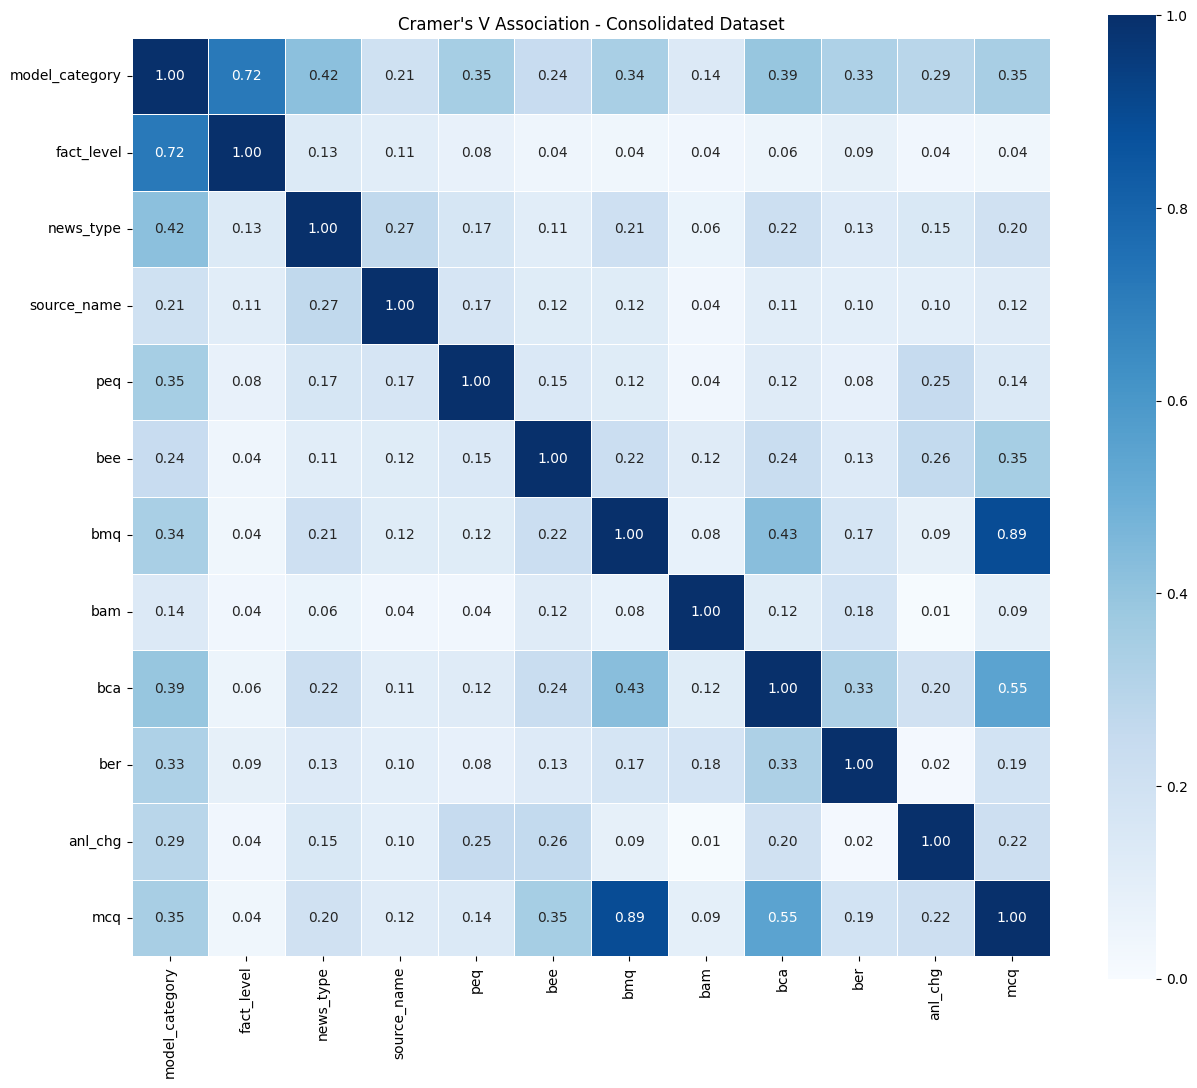

In [60]:
# 8.7.9 Visualize Updated Categorical Associations

plt.figure(figsize=(13, 11))

sns.heatmap(

    updated_cramers_matrix,

    annot=True,

    fmt=".2f",

    cmap="Blues",

    vmin=0,

    vmax=1,

    square=True,

    linewidths=0.5

)

plt.title(
    "Cramer's V Association - Consolidated Dataset"
)

plt.tight_layout()
plt.show()

In [61]:
# 8.7.10 Identify Strongest Categorical Relationships

updated_categorical_results = []

for col1, col2 in combinations(
    categorical_variables, 2
):

    updated_categorical_results.append({

        "Variable 1": col1,

        "Variable 2": col2,

        "Cramers V":
            updated_cramers_matrix.loc[col1, col2]

    })

updated_categorical_summary = (

    pd.DataFrame(updated_categorical_results)

    .sort_values(
        "Cramers V",
        ascending=False
    )

    .reset_index(drop=True)

)

display(
    updated_categorical_summary.head(20).round(4)
)

high_updated_association = (
    updated_categorical_summary[
        updated_categorical_summary["Cramers V"]
        >= 0.70
    ]
)

print(
    "Total categorical relationships:",
    len(updated_categorical_summary)
)

print(
    "Strongly associated variable pairs:",
    len(high_updated_association)
)

display(high_updated_association.round(4))

,Variable 1,Variable 2,Cramers V
0,bmq,mcq,0.8944
1,model_category,fact_level,0.7201
2,bca,mcq,0.5500
3,bmq,bca,0.4277
4,model_category,news_type,0.4215
5,model_category,bca,0.3913
6,model_category,peq,0.3495
7,bee,mcq,0.3487
8,model_category,mcq,0.3459
9,model_category,bmq,0.3432


Total categorical relationships: 66
Strongly associated variable pairs: 2


,Variable 1,Variable 2,Cramers V
0,bmq,mcq,0.8944
1,model_category,fact_level,0.7201


In [62]:
# 8.7.11 Updated Sentiment Analysis by Category

updated_sentiment_summary = (

    full_feature_df

    .groupby(
        "model_category",
        observed=True
    )["event_sentiment_score"]

    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])

    .sort_values(
        "mean",
        ascending=False
    )

)

updated_sentiment_summary.columns = [

    "Observations",

    "Mean Sentiment",

    "Median Sentiment",

    "Standard Deviation",

    "Minimum",

    "Maximum"

]

display(updated_sentiment_summary.round(4))

,Observations,Mean Sentiment,Median Sentiment,Standard Deviation,Minimum,Maximum
model_category,,,,,,
earnings_beat,7677,0.6806,0.70,0.0690,0.46,1.00
revenue_beat,2391,0.6135,0.72,0.1228,0.48,1.00
share_repurchases,14168,0.5761,0.59,0.1226,-0.50,0.84
mergers_acquisitions,40784,0.5735,0.62,0.1685,-0.65,0.86
product_launches,24092,0.5126,0.52,0.1403,-0.48,0.78
equity_issuance,3766,0.4706,0.59,0.2246,0.00,0.59
partnerships_contracts,81674,0.4618,0.49,0.1012,-0.55,0.70
dividend_changes,9527,0.4243,0.44,0.3248,-0.80,1.00
management_changes,37851,0.2252,0.53,0.4706,-0.76,0.78


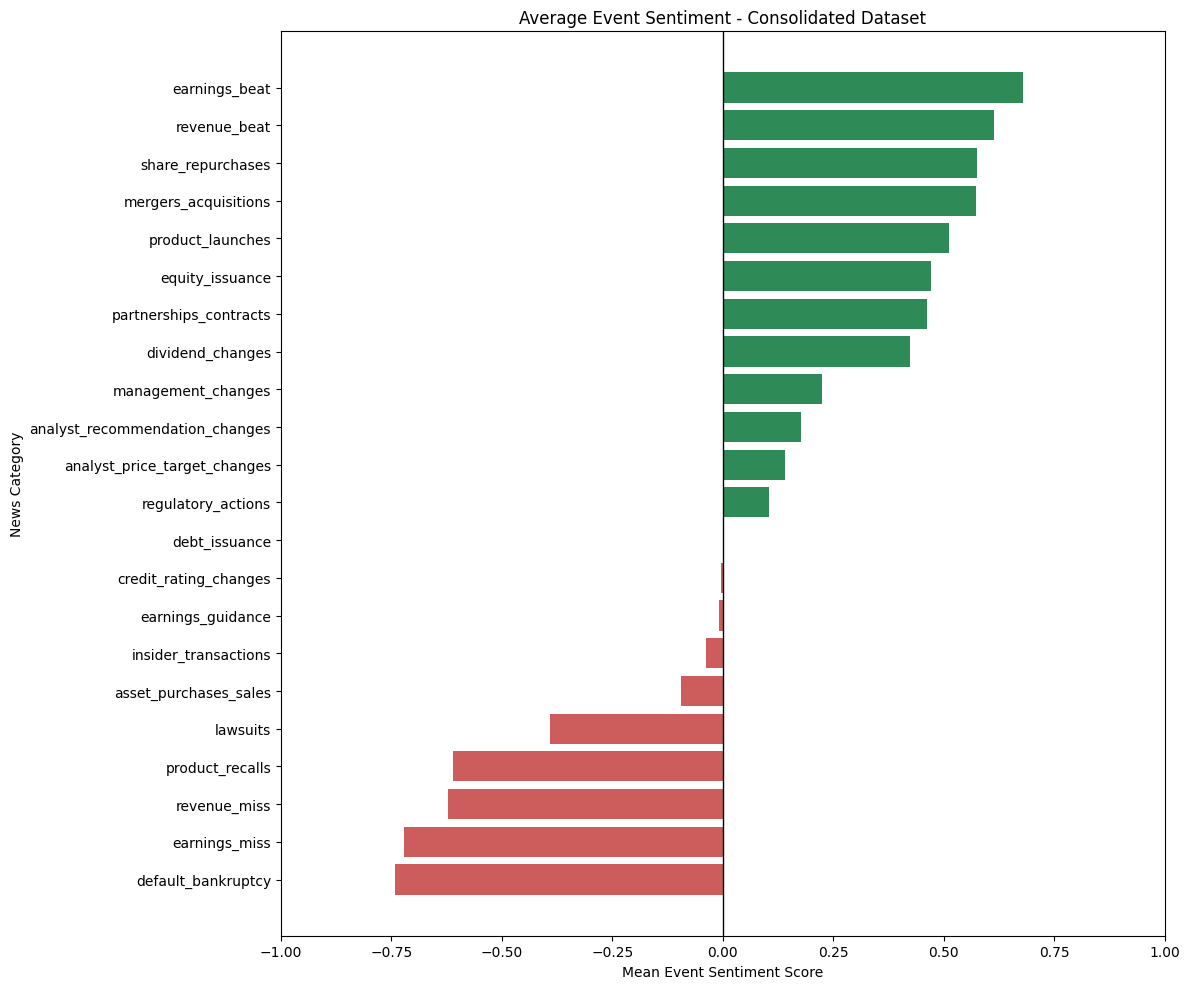

In [63]:
# 8.7.12 Visualize Updated Average Sentiment

plt.figure(figsize=(12, 10))

colors = [

    "seagreen" if value >= 0 else "indianred"

    for value in
    updated_sentiment_summary["Mean Sentiment"]

]

plt.barh(

    updated_sentiment_summary.index.astype(str),

    updated_sentiment_summary["Mean Sentiment"],

    color=colors

)

plt.axvline(
    0,
    color="black",
    linewidth=1
)

plt.gca().invert_yaxis()

plt.title(
    "Average Event Sentiment - Consolidated Dataset"
)

plt.xlabel("Mean Event Sentiment Score")
plt.ylabel("News Category")

plt.xlim(-1, 1)

plt.tight_layout()
plt.show()

In [64]:
# 8.7.13 Updated BMQ and MCQ Agreement

bmq_mcq_updated = pd.crosstab(

    full_feature_df["bmq"],

    full_feature_df["mcq"]

)

display(bmq_mcq_updated)

valid_signals = (
    full_feature_df[["bmq", "mcq"]]
    .dropna()
)

updated_agreement = (
    valid_signals["bmq"] ==
    valid_signals["mcq"]
)

print(
    "Valid signal pairs:",
    f"{len(valid_signals):,}"
)

print(
    "Identical observations:",
    f"{updated_agreement.sum():,}"
)

print(
    "Different observations:",
    f"{(~updated_agreement).sum():,}"
)

print("Original agreement: 93.3649%")

print(
    "Consolidated agreement:",
    f"{updated_agreement.mean() * 100:.4f}%"
)

mcq,-1,0,1
bmq,,,
-1,74161,1153,999
0,13905,329185,20055
1,457,1339,159593


Valid signal pairs: 600,847
Identical observations: 562,939
Different observations: 37,908
Original agreement: 93.3649%
Consolidated agreement: 93.6909%


,novel_1day,novel_7days
model_category,,
dividend_changes,74.3151,72.1528
revenue_beat,68.8415,67.1685
insider_transactions,68.7335,53.9093
credit_rating_changes,58.5431,56.6149
earnings_guidance,57.2195,53.8233
revenue_miss,51.8390,48.6468
asset_purchases_sales,46.2174,44.1831
share_repurchases,45.5181,41.2973
earnings_beat,42.6990,39.0517


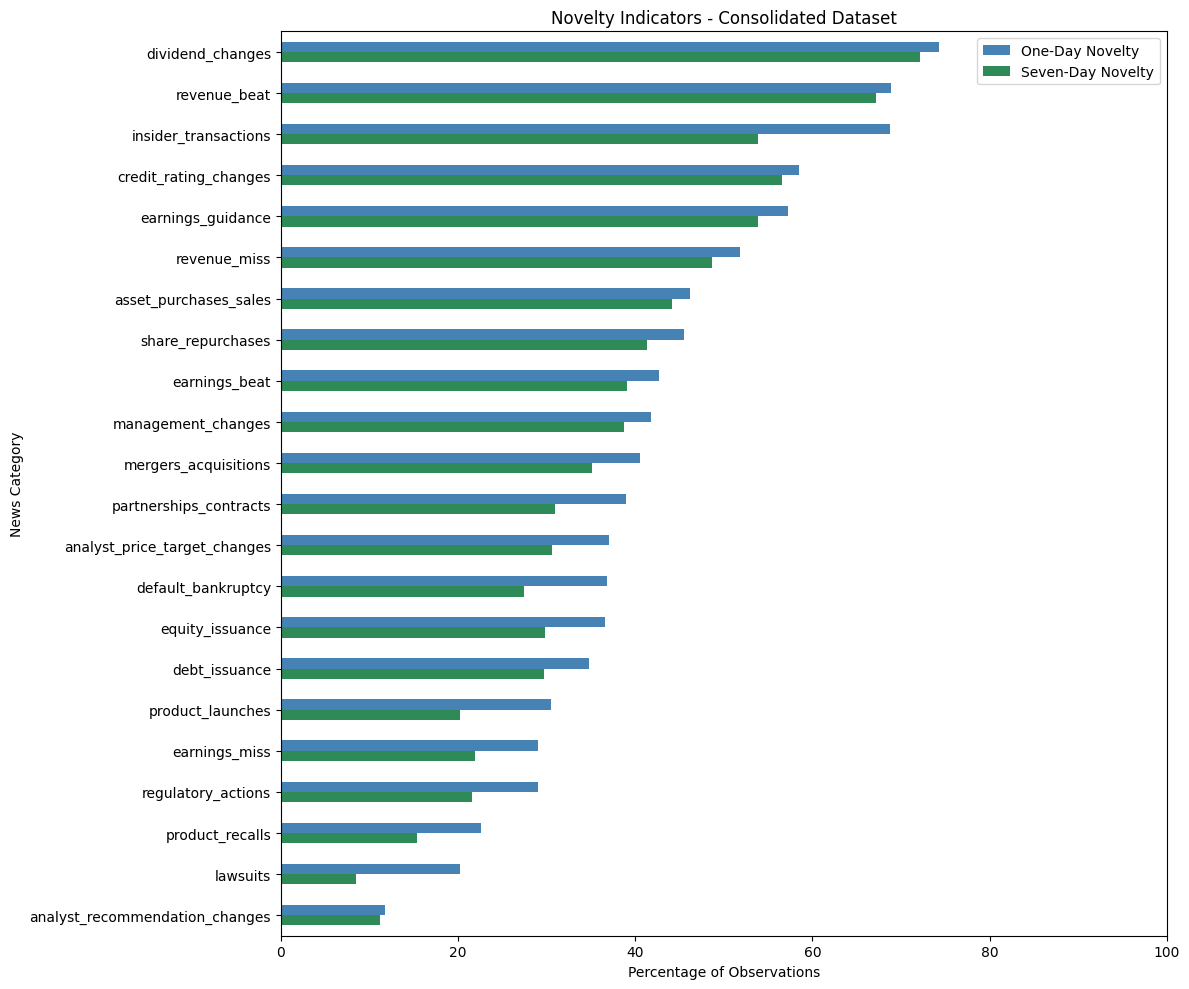

In [65]:
# 8.7.14 Updated Novelty by News Category

updated_novelty_summary = (

    full_feature_df.groupby(
        "model_category",
        observed=True
    )[novelty_features]

    .mean() * 100

).sort_values(

    "novel_1day",

    ascending=False

)

display(updated_novelty_summary.round(4))

updated_novelty_summary.plot(

    kind="barh",

    figsize=(12, 10),

    color=["steelblue", "seagreen"]

)

plt.title("Novelty Indicators - Consolidated Dataset")

plt.xlabel("Percentage of Observations")
plt.ylabel("News Category")

plt.xlim(0, 100)

plt.gca().invert_yaxis()

plt.legend([
    "One-Day Novelty",
    "Seven-Day Novelty"
])

plt.tight_layout()
plt.show()

### 8.7.15 Interpretation of Updated Statistical Analysis

The statistical relationships were reexamined using
the 600,847 consolidated security-event observations.

All six numerical variables contained complete
observations, and no numerical relationships
exceeded the specified correlation threshold
of 0.80.

The categorical association analysis identified
strong relationships between BMQ and MCQ and
between news category and fact level.

Approximately 93.69% of BMQ and MCQ observations
contained identical values, supporting the earlier
finding of overlapping information.

The sentiment analysis generally produced results
consistent with financial intuition. However,
differences were identified following the
consolidation of redundant observations.

In particular, the average sentiment associated
with regulatory actions changed from negative
to positive.

The novelty analysis also demonstrated differences
across financial news categories, supporting the
retention of both novelty indicators.

These findings demonstrate that redundant
observations influenced the statistical
representation of the original news dataset.

The consolidated results provide a more appropriate
description of the financial news information
used to construct the 53 baseline predictors.

## 9.0 Final Dataset Export and Documentation

Following the completion of the preprocessing
and statistical analysis, the final news dataset
is exported in Parquet format.

The baseline predictors, identification variables,
and supporting variables are organized to facilitate
integration with financial market data.

A feature dictionary, validation reports, and
statistical summaries are also exported to
document the preprocessing methodology and
support the reproducibility of the analysis.

In [66]:
# 9.1 Define Final Output Files

final_news_path = (
    output_folder /
    "ravenpack_processed.parquet"
)

feature_dictionary_path = (
    output_folder /
    "ravenpack_feature_details.csv"
)

validation_report_path = (
    output_folder /
    "ravenpack_validation_report.csv"
)

summary_folder = (
    output_folder /
    "ravenpack_analysis"
)

summary_folder.mkdir(
    parents=True,
    exist_ok=True
)

print("Final dataset:", final_news_path)

print("Feature dictionary:", feature_dictionary_path)

print("Validation report:", validation_report_path)

print("Statistical summaries:", summary_folder)

Final dataset: data/ravenpack_processed.parquet
Feature dictionary: data/ravenpack_feature_details.csv
Validation report: data/ravenpack_validation_report.csv
Statistical summaries: data/ravenpack_analysis


In [67]:
# 9.2 Export the Final News Dataset

final_column_order = (
    identifier_columns +
    baseline_news_features +
    supporting_features
)

full_feature_df = full_feature_df[
    final_column_order
]

full_feature_df.sort_values(

    by=[
        "timestamp_utc",
        "cusip",
        "rp_story_id",
        "rp_story_event_index"
    ],

    inplace=True

)

full_feature_df.reset_index(
    drop=True,
    inplace=True
)

full_feature_df.to_parquet(

    final_news_path,

    index=False,

    compression="snappy"

)

print("Final news dataset saved successfully.")

print(
    "Observations:",
    f"{len(full_feature_df):,}"
)

print(
    "Variables:",
    len(full_feature_df.columns)
)

print(
    "Baseline predictors:",
    len(baseline_news_features)
)

print(
    "File size (MB):",
    round(
        final_news_path.stat().st_size /
        1024**2,
        2
    )
)

display(full_feature_df.head())

Final news dataset saved successfully.
Observations: 600,847
Variables: 75
Baseline predictors: 53
File size (MB): 42.55


,rp_entity_id,cusip,rp_story_id,rp_story_event_index,timestamp_utc,category,model_category,event_similarity_key,earnings_beat,earnings_miss,...,css,nip,peq,bee,bmq,bam,bca,ber,anl_chg,mcq
0,CC6FF5,127387108,FB72DFC76C74CF0825B281A9F83C61F6,1,2020-01-01 00:21:35.639000+00:00,insider-gift,insider_transactions,A95248BFC73792140A9487E001BA2CCA,0,0,...,0.0,-0.18,0,0,0,0,0,0,0,0
1,F4E882,577081102,C694A384C3647D04CF0847538DB7E65F,3,2020-01-01 04:22:19.820000+00:00,legal-issues-defendant,lawsuits,EAFAB36F723AB0ECB6949D5E3DC3A133,0,0,...,0.0,-0.22,-1,1,0,0,0,0,0,1
2,2E61CC,742718109,829553D9821D4F57F2D50329B0D580DF,2,2020-01-01 12:59:31.410000+00:00,dividend-up,dividend_changes,A426C0318BEE6840DAE1135980ED722F,0,0,...,0.1,-0.12,1,0,0,0,0,0,0,0
3,BFAEB4,172908105,1FBA4F4CCEF869D81FC6B76F258503F7,1,2020-01-01 16:30:03.290000+00:00,earnings-guidance,earnings_guidance,6223CD66FAF3FC7D1639E6044F6FC194,0,0,...,-0.1,0.00,0,-1,0,0,0,0,0,-1
4,41EC04,904311107,4DBAFA219237B06E9E5ADEC2460392EF,1,2020-01-02 04:30:04.278000+00:00,regulatory-investigation,regulatory_actions,D8279191AFFFC4EFAC339A0C72840A7C,0,0,...,0.1,-0.20,1,0,0,0,0,0,0,0


### 9.3 Create the Feature Dictionary

A feature dictionary is constructed to document
the variables included in the final news dataset.

Each variable is classified according to its
purpose, data type, and inclusion in the baseline
modeling specification.

The dictionary provides descriptions of the
original and engineered variables to support
interpretation and reproducibility.

In [68]:
# 9.3 Create the Feature Dictionary

variable_descriptions = {

    "rp_entity_id":
        "Unique RavenPack entity identifier.",

    "cusip":
        "Security identifier used for financial data integration.",

    "rp_story_id":
        "Unique RavenPack news story identifier.",

    "rp_story_event_index":
        "Event index within the original news story.",

    "timestamp_utc":
        "News event timestamp expressed in UTC.",

    "category":
        "Original RavenPack event category.",

    "model_category":
        "Standardized financial news category.",

    "event_similarity_key":
        "Identifier associated with similar news events.",

    "relevance":
        "Entity relevance score ranging from 0 to 100.",

    "event_sentiment_score":
        "Event sentiment score ranging from -1 to 1.",

    "event_relevance":
        "Event relevance score ranging from 0 to 100.",

    "event_similarity_days":
        "RavenPack event similarity interval measured in days.",

    "is_fact":
        "Indicator equal to one when the event is classified as a fact.",

    "is_forecast":
        "Indicator equal to one when the event is classified as a forecast.",

    "is_opinion":
        "Indicator equal to one when the event is classified as an opinion.",

    "novel_1day":
        "Indicator equal to one when event similarity days is at least one.",

    "novel_7days":
        "Indicator equal to one when event similarity days is at least seven.",

    "fact_level":
        "Original RavenPack fact-level classification.",

    "news_type":
        "Original RavenPack news-type classification.",

    "rp_source_id":
        "RavenPack news source identifier.",

    "source_name":
        "Name of the news source.",

    "css":
        "Original RavenPack CSS score.",

    "nip":
        "Original RavenPack NIP score."

}

# Describe standardized category indicators

for category in target_categories:

    variable_descriptions[category] = (

        "Indicator equal to one for events classified as " +
        category.replace("_", " ") + "."

    )


# Describe sentiment interaction variables

for category in target_categories:

    variable_descriptions[
        f"{category}_sentiment"
    ] = (

        "Interaction between the event sentiment score and the " +
        category.replace("_", " ") +
        " category indicator."

    )


# Describe additional RavenPack signals

for signal in discrete_signals:

    variable_descriptions[signal] = (

        f"Original RavenPack {signal.upper()} signal, "
        "retained for additional model experimentation."

    )


def classify_variable(variable):

    if variable in identifier_columns:
        return "Identification"

    elif variable in category_features:
        return "News Category"

    elif variable in numerical_features:
        return "Numerical Predictor"

    elif variable in fact_features:
        return "Fact-Level Indicator"

    elif variable in novelty_features:
        return "Novelty Indicator"

    elif variable in interaction_features:
        return "Sentiment Interaction"

    else:
        return "Supporting Variable"


feature_dictionary = pd.DataFrame({

    "characteristic":
        final_column_order,

    "description": [
        variable_descriptions.get(col, "")
        for col in final_column_order
    ],

    "theme": [
        classify_variable(col)
        for col in final_column_order
    ],

    "data_type": [
        str(full_feature_df[col].dtype)
        for col in final_column_order
    ],

    "baseline_predictor": [
        col in baseline_news_features
        for col in final_column_order
    ],

    "constant_in_full_dataset": [
        full_feature_df[col].nunique(
            dropna=False
        ) <= 1

        for col in final_column_order
    ]

})

feature_dictionary.to_csv(

    feature_dictionary_path,

    index=False

)

print(
    "Variables documented:",
    len(feature_dictionary)
)

print(
    "Baseline predictors documented:",
    feature_dictionary["baseline_predictor"].sum()
)

print(
    "Missing descriptions:",
    feature_dictionary["description"].eq("").sum()
)

display(feature_dictionary.head(20))

Variables documented: 75
Baseline predictors documented: 53
Missing descriptions: 0


,characteristic,description,theme,data_type,baseline_predictor,constant_in_full_dataset
0,rp_entity_id,Unique RavenPack entity identifier.,Identification,object,False,False
1,cusip,Security identifier used for financial data in...,Identification,object,False,False
2,rp_story_id,Unique RavenPack news story identifier.,Identification,object,False,False
3,rp_story_event_index,Event index within the original news story.,Identification,object,False,False
4,timestamp_utc,News event timestamp expressed in UTC.,Identification,"datetime64[ns, UTC]",False,False
5,category,Original RavenPack event category.,Identification,category,False,False
6,model_category,Standardized financial news category.,Identification,category,False,False
7,event_similarity_key,Identifier associated with similar news events.,Identification,object,False,False
8,earnings_beat,Indicator equal to one for events classified a...,News Category,int8,True,False
9,earnings_miss,Indicator equal to one for events classified a...,News Category,int8,True,False


In [69]:
# 9.4 Export the Baseline Predictor List

baseline_predictor_path = (
    output_folder /
    "ravenpack_baseline_features.csv"
)

baseline_predictor_table = pd.DataFrame({

    "feature": baseline_news_features

})

baseline_predictor_table.to_csv(

    baseline_predictor_path,

    index=False

)

print(
    "Baseline predictors saved:",
    len(baseline_predictor_table)
)

display(baseline_predictor_table)

Baseline predictors saved: 53


,feature
0,earnings_beat
1,earnings_miss
2,revenue_beat
3,revenue_miss
4,earnings_guidance
5,dividend_changes
6,share_repurchases
7,equity_issuance
8,debt_issuance
9,credit_rating_changes


In [70]:
# 9.5 Export Statistical Results

statistical_tables = {

    "category_consolidation_summary":
        category_consolidation_summary,

    "category_distribution_comparison":
        category_distribution_comparison,

    "variable_difference_summary":
        variable_difference_summary,

    "repetition_distribution":
        repetition_distribution,

    "numerical_summary":
        updated_numerical_summary,

    "numerical_comparison":
        numerical_comparison,

    "pearson_correlation":
        updated_pearson,

    "spearman_correlation":
        updated_spearman,

    "correlation_summary":
        updated_correlation_summary,

    "cramers_v_matrix":
        updated_cramers_matrix,

    "categorical_association_summary":
        updated_categorical_summary,

    "sentiment_summary":
        updated_sentiment_summary,

    "novelty_summary":
        updated_novelty_summary,

    "bmq_mcq_agreement":
        bmq_mcq_updated,

    "feature_summary":
        full_feature_summary

}

for name, table in statistical_tables.items():

    table.to_csv(

        summary_folder / f"{name}.csv",

        index=not isinstance(
            table.index,
            pd.RangeIndex
        )

    )

    print(f"Saved: {name}.csv")

print(
    "\nTotal statistical tables exported:",
    len(statistical_tables)
)

Saved: category_consolidation_summary.csv
Saved: category_distribution_comparison.csv
Saved: variable_difference_summary.csv
Saved: repetition_distribution.csv
Saved: numerical_summary.csv
Saved: numerical_comparison.csv
Saved: pearson_correlation.csv
Saved: spearman_correlation.csv
Saved: correlation_summary.csv
Saved: cramers_v_matrix.csv
Saved: categorical_association_summary.csv
Saved: sentiment_summary.csv
Saved: novelty_summary.csv
Saved: bmq_mcq_agreement.csv
Saved: feature_summary.csv

Total statistical tables exported: 15


In [71]:
# 9.6 Export Validation Reports

combined_validation_report = pd.concat([

    consolidation_validation.assign(
        Stage="Event Consolidation"
    ),

    source_validation_report.assign(
        Stage="Source Validation"
    ),

    full_validation_report.assign(
        Stage="Feature Validation"
    )

], ignore_index=True)

combined_validation_report = (
    combined_validation_report[[
        "Stage",
        "Validation Check",
        "Passed"
    ]]
)

combined_validation_report.to_csv(

    validation_report_path,

    index=False

)

display(combined_validation_report)

print(
    "Total validation checks:",
    len(combined_validation_report)
)

print(
    "Passed validation checks:",
    combined_validation_report["Passed"].sum()
)

print(
    "Failed validation checks:",
    (~combined_validation_report["Passed"]).sum()
)

print(
    "Overall validation:",
    combined_validation_report["Passed"].all()
)

,Stage,Validation Check,Passed
0,Event Consolidation,Expected Observation Count,True
1,Event Consolidation,Expected Variable Count,True
2,Event Consolidation,Unique Security-Event Keys,True
3,Event Consolidation,Ticker Excluded,True
4,Event Consolidation,ISIN Excluded,True
5,Event Consolidation,Reference Mapping Preserved,True
6,Source Validation,Expected Observation Count,True
7,Source Validation,All 22 Categories Represented,True
8,Source Validation,Valid Fact Levels,True
9,Source Validation,Valid Entity Relevance,True


Total validation checks: 25
Passed validation checks: 25
Failed validation checks: 0
Overall validation: True


In [72]:
# 9.7 Validate the Exported Parquet File

final_parquet = pq.ParquetFile(
    final_news_path
)

exported_columns = (
    final_parquet.schema_arrow.names
)

export_validation = {

    "Final File Exists":
        final_news_path.exists(),

    "Correct Observation Count":
        final_parquet.metadata.num_rows == 600_847,

    "Correct Variable Count":
        final_parquet.metadata.num_columns == 75,

    "Correct Column Ordering":
        exported_columns == final_column_order,

    "All Baseline Predictors Present":
        set(baseline_news_features).issubset(
            exported_columns
        ),

    "Feature Dictionary Exists":
        feature_dictionary_path.exists(),

    "Predictor List Exists":
        baseline_predictor_path.exists(),

    "Validation Report Exists":
        validation_report_path.exists()

}

export_validation_report = pd.DataFrame({

    "Validation Check":
        list(export_validation.keys()),

    "Passed":
        list(export_validation.values())

})

display(export_validation_report)

assert export_validation_report["Passed"].all()

print(
    "Overall export validation:",
    export_validation_report["Passed"].all()
)

,Validation Check,Passed
0,Final File Exists,True
1,Correct Observation Count,True
2,Correct Variable Count,True
3,Correct Column Ordering,True
4,All Baseline Predictors Present,True
5,Feature Dictionary Exists,True
6,Predictor List Exists,True
7,Validation Report Exists,True


Overall export validation: True


In [73]:
# 9.8 Examine Final Dataset Coverage

print(
    "Total observations:",
    f"{len(full_feature_df):,}"
)

print(
    "Unique companies:",
    full_feature_df["rp_entity_id"].nunique()
)

print(
    "Unique securities:",
    full_feature_df["cusip"].nunique()
)

print(
    "Unique news stories:",
    full_feature_df["rp_story_id"].nunique()
)

print(
    "Earliest timestamp:",
    full_feature_df["timestamp_utc"].min()
)

print(
    "Latest timestamp:",
    full_feature_df["timestamp_utc"].max()
)

print(
    "Unique standardized categories:",
    full_feature_df["model_category"].nunique()
)

print(
    "Remaining repeated security-event keys:",
    full_feature_df.duplicated(
        subset=event_key
    ).sum()
)

Total observations: 600,847
Unique companies: 537
Unique securities: 541
Unique news stories: 522952
Earliest timestamp: 2020-01-01 00:21:35.639000+00:00
Latest timestamp: 2025-01-01 21:00:00.215000+00:00
Unique standardized categories: 22
Remaining repeated security-event keys: 0


In [74]:
# 9.8.1 Examine Annual Observation Counts

annual_summary = (

    full_feature_df

    .groupby(
        full_feature_df["timestamp_utc"].dt.year
    )

    .agg(

        observations=("rp_story_id", "size"),

        unique_stories=("rp_story_id", "nunique"),

        unique_companies=("rp_entity_id", "nunique"),

        unique_securities=("cusip", "nunique")

    )

)

annual_summary.index.name = "Year"

display(annual_summary)

annual_summary.to_csv(

    summary_folder /
    "annual_coverage_summary.csv"

)

,observations,unique_stories,unique_companies,unique_securities
Year,,,,
2020,118653,104191,515,519
2021,110052,94848,517,521
2022,113116,98462,523,527
2023,122500,105350,530,534
2024,136511,120087,535,539
2025,15,14,12,12


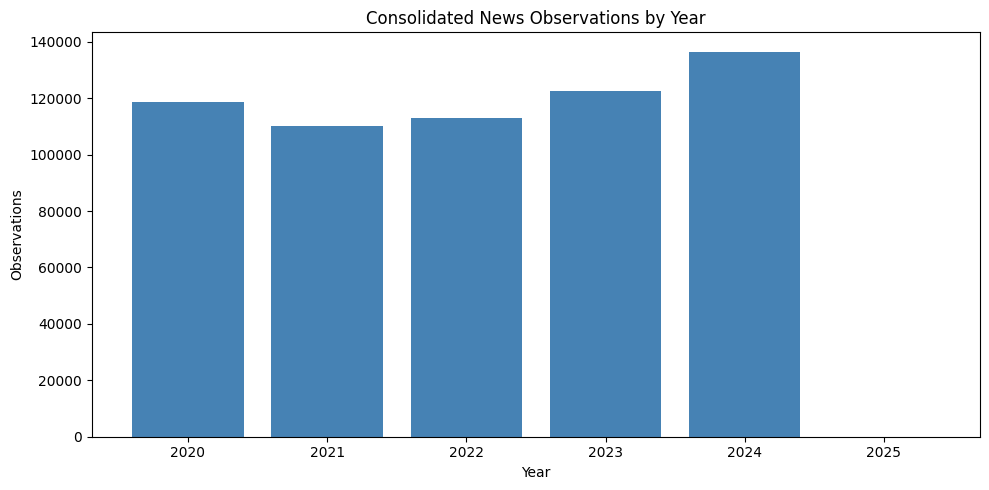

In [75]:
# 9.8.2 Visualize Annual Observation Counts

plt.figure(figsize=(10, 5))

plt.bar(

    annual_summary.index.astype(str),

    annual_summary["observations"],

    color="steelblue"

)

plt.title(
    "Consolidated News Observations by Year"
)

plt.xlabel("Year")

plt.ylabel("Observations")

plt.tight_layout()

plt.show()

In [76]:
# 9.9 Examine Modeling Period Coverage

modeling_periods = {

    "Training": (
        "2020-01-01",
        "2023-01-01"
    ),

    "Validation": (
        "2023-01-01",
        "2024-01-01"
    ),

    "Testing": (
        "2024-01-01",
        "2025-01-01"
    )

}

period_results = []

for period, (start, end) in modeling_periods.items():

    start_date = pd.Timestamp(
        start,
        tz="UTC"
    )

    end_date = pd.Timestamp(
        end,
        tz="UTC"
    )

    mask = (

        (
            full_feature_df["timestamp_utc"] >=
            start_date
        ) &

        (
            full_feature_df["timestamp_utc"] <
            end_date
        )

    )

    period_results.append({

        "Period": period,

        "Start Date": start,

        "End Date (Exclusive)": end,

        "Observations": int(mask.sum()),

        "Unique Securities":
            full_feature_df.loc[
                mask, "cusip"
            ].nunique(),

        "News Categories":
            full_feature_df.loc[
                mask, "model_category"
            ].nunique()

    })

modeling_period_summary = pd.DataFrame(
    period_results
)

modeling_period_summary["Percentage (%)"] = (

    modeling_period_summary["Observations"] /
    len(full_feature_df) * 100

)

display(modeling_period_summary.round(4))

print(
    "Observations within modeling periods:",
    f"{modeling_period_summary['Observations'].sum():,}"
)

print(
    "Observations outside modeling periods:",
    len(full_feature_df) -
    modeling_period_summary["Observations"].sum()
)

modeling_period_summary.to_csv(

    summary_folder /
    "modeling_period_summary.csv",

    index=False

)

,Period,Start Date,End Date (Exclusive),Observations,Unique Securities,News Categories,Percentage (%)
0,Training,2020-01-01,2023-01-01,341821,527,22,56.8899
1,Validation,2023-01-01,2024-01-01,122500,534,22,20.3879
2,Testing,2024-01-01,2025-01-01,136511,539,22,22.7198


Observations within modeling periods: 600,832
Observations outside modeling periods: 15


### 9.9.1 Interpretation of Final Dataset Results

The final processed news dataset contains 600,847
unique security-event observations across 537
companies and 541 securities.

The dataset contains 75 variables, including
53 baseline news predictors, eight identification
variables, and 14 supporting variables.

A total of 522,952 unique news stories and all
22 standardized news categories are represented.

The preliminary chronological analysis identified
341,821 training observations, 122,500 validation
observations, and 136,511 testing observations.

An additional 15 observations dated January 1,
2025, fall outside the specified modeling periods.

All standardized news categories are represented
within each modeling period.

All consolidation, source, feature, and export
validation checks were satisfied.

The processed dataset occupies approximately
42.55 MB and is suitable for the subsequent
integration of financial market information.

In [77]:
# 9.10.1 Update the Final Validation Report

final_validation_report = pd.concat(
    [
        combined_validation_report,
        export_validation_report.assign(
            Stage="Export Validation"
        )
    ],
    ignore_index=True
)

final_validation_report = final_validation_report[
    [
        "Stage",
        "Validation Check",
        "Passed"
    ]
]

final_validation_report.to_csv(
    validation_report_path,
    index=False
)

print(
    "Total validation checks:",
    len(final_validation_report)
)

print(
    "Passed validation checks:",
    final_validation_report["Passed"].sum()
)

print(
    "Failed validation checks:",
    (~final_validation_report["Passed"]).sum()
)

print(
    "Overall validation:",
    final_validation_report["Passed"].all()
)

Total validation checks: 33
Passed validation checks: 33
Failed validation checks: 0
Overall validation: True


### 9.10 Reusable News Preprocessing Script

A reusable Python script is developed to support
the reproducibility of the news preprocessing
methodology.

The script applies the standardized category mapping,
consolidates redundant security-event observations,
constructs the 53 baseline predictors, and exports
the processed news dataset.

The exploratory analysis remains documented in
the preprocessing notebook, while the script
contains the essential transformation procedures
required for financial data integration.

In [78]:
%%writefile RP_news.py

"""
RavenPack News Preprocessing

Purpose:
    Transform RavenPack news observations into a
    consolidated security-event dataset containing
    53 baseline machine learning predictors.

Inputs:
    Original RavenPack CSV
    Standardized category mapping

Outputs:
    Processed RavenPack Parquet dataset
    Baseline feature list
    Security reference mapping
"""

import argparse
from pathlib import Path

import pandas as pd
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq
import duckdb


# --------------------------------------------------
# 1. Define the feature structure
# --------------------------------------------------

TARGET_CATEGORIES = [
    "earnings_beat",
    "earnings_miss",
    "revenue_beat",
    "revenue_miss",
    "earnings_guidance",
    "dividend_changes",
    "share_repurchases",
    "equity_issuance",
    "debt_issuance",
    "credit_rating_changes",
    "default_bankruptcy",
    "mergers_acquisitions",
    "asset_purchases_sales",
    "analyst_recommendation_changes",
    "analyst_price_target_changes",
    "management_changes",
    "insider_transactions",
    "lawsuits",
    "regulatory_actions",
    "product_launches",
    "product_recalls",
    "partnerships_contracts"
]

NUMERICAL_FEATURES = [
    "relevance",
    "event_sentiment_score",
    "event_relevance",
    "event_similarity_days"
]

FACT_FEATURES = [
    "is_fact",
    "is_forecast",
    "is_opinion"
]

NOVELTY_FEATURES = [
    "novel_1day",
    "novel_7days"
]

INTERACTION_FEATURES = [
    f"{category}_sentiment"
    for category in TARGET_CATEGORIES
]

BASELINE_FEATURES = (
    TARGET_CATEGORIES +
    NUMERICAL_FEATURES +
    FACT_FEATURES +
    NOVELTY_FEATURES +
    INTERACTION_FEATURES
)

IDENTIFIER_COLUMNS = [
    "rp_entity_id",
    "cusip",
    "rp_story_id",
    "rp_story_event_index",
    "timestamp_utc",
    "category",
    "model_category",
    "event_similarity_key"
]

SUPPORTING_FEATURES = [
    "fact_level",
    "news_type",
    "rp_source_id",
    "source_name",
    "css",
    "nip",
    "peq",
    "bee",
    "bmq",
    "bam",
    "bca",
    "ber",
    "anl_chg",
    "mcq"
]

DISCRETE_SIGNALS = [
    "peq", "bee", "bmq", "bam",
    "bca", "ber", "anl_chg", "mcq"
]

EVENT_KEY = [
    "rp_story_id",
    "cusip",
    "rp_entity_id",
    "rp_story_event_index",
    "category",
    "timestamp_utc"
]

SOURCE_COLUMNS = (
    IDENTIFIER_COLUMNS +
    NUMERICAL_FEATURES +
    SUPPORTING_FEATURES
)

FINAL_COLUMNS = (
    IDENTIFIER_COLUMNS +
    BASELINE_FEATURES +
    SUPPORTING_FEATURES
)


# --------------------------------------------------
# 2. Extract mapped news observations
# --------------------------------------------------

def extract_mapped_news(
    file_path,
    mapping_path,
    output_path,
    chunk_size=100_000
):

    mapping_df = pd.read_parquet(mapping_path)

    assert mapping_df["category"].is_unique

    category_mapping = (
        mapping_df
        .set_index("category")["model_category"]
        .to_dict()
    )

    original_columns = pd.read_csv(
        file_path,
        nrows=0
    ).columns.tolist()

    assert set(SOURCE_COLUMNS) - {"model_category"} <= set(
        original_columns
    )

    assert {"ticker", "isin", "entity_name"} <= set(
        original_columns
    )

    schema = pa.schema([
        (col, pa.string())
        for col in original_columns + ["model_category"]
    ])

    temporary_path = output_path.with_suffix(".tmp.parquet")

    rows_processed = 0
    rows_mapped = 0

    with pq.ParquetWriter(
        temporary_path,
        schema,
        compression="snappy"
    ) as writer:

        for i, chunk in enumerate(
            pd.read_csv(
                file_path,
                chunksize=chunk_size,
                dtype="string"
            ),
            start=1
        ):

            rows_processed += len(chunk)

            chunk["model_category"] = (
                chunk["category"].map(category_mapping)
            )

            mapped_chunk = chunk.loc[
                chunk["model_category"].isin(
                    TARGET_CATEGORIES
                )
            ]

            rows_mapped += len(mapped_chunk)

            if not mapped_chunk.empty:

                writer.write_table(
                    pa.Table.from_pandas(
                        mapped_chunk,
                        schema=schema,
                        preserve_index=False
                    )
                )

            if i % 50 == 0:

                print(
                    f"Processed: {rows_processed:,} | "
                    f"Mapped: {rows_mapped:,}"
                )

    if rows_mapped == 0:
        raise ValueError("No mapped news records found.")

    temporary_path.replace(output_path)

    print(f"Original observations: {rows_processed:,}")
    print(f"Mapped observations: {rows_mapped:,}")

    return rows_mapped


# --------------------------------------------------
# 3. Consolidate redundant event records
# --------------------------------------------------

def consolidate_news(
    mapped_path,
    consolidated_path,
    reference_path
):

    temp_folder = (
        consolidated_path.parent / "duckdb_temp"
    )

    temp_folder.mkdir(
        parents=True,
        exist_ok=True
    )

    con = duckdb.connect(":memory:")

    try:

        con.execute("SET memory_limit = '6GB'")
        con.execute("SET threads = 2")

        con.execute(
            "SET temp_directory = ?",
            [str(temp_folder.resolve())]
        )

        con.execute(
            "SET preserve_insertion_order = false"
        )

        con.read_parquet(
            str(mapped_path.resolve())
        ).create_view("mapped_news")

        original_count = con.execute("""
            SELECT COUNT(*)
            FROM mapped_news
        """).fetchone()[0]

        # Preserve security reference combinations

        reference_df = con.execute("""
            SELECT DISTINCT
                rp_entity_id,
                entity_name,
                cusip,
                ticker,
                isin
            FROM mapped_news
        """).df()

        reference_df.to_parquet(
            reference_path,
            index=False
        )

        # Preserve all remaining news information

        all_columns = con.execute("""
            DESCRIBE SELECT * FROM mapped_news
        """).df()["column_name"].tolist()

        retained_columns = [
            col for col in all_columns
            if col not in ["ticker", "isin"]
        ]

        retained_sql = ", ".join(
            '"' + col.replace('"', '""') + '"'
            for col in retained_columns
        )

        key_sql = ", ".join(EVENT_KEY)

        temporary_path = consolidated_path.with_suffix(
            ".tmp.parquet"
        )

        temporary_path.unlink(missing_ok=True)

        sql_path = str(
            temporary_path.resolve()
        ).replace("'", "''")

        con.execute(f"""
            COPY (
                SELECT DISTINCT {retained_sql}
                FROM mapped_news
            )
            TO '{sql_path}'
            (
                FORMAT PARQUET,
                COMPRESSION SNAPPY
            )
        """)

        con.read_parquet(
            str(temporary_path.resolve())
        ).create_view("consolidated_news")

        consolidated_count = con.execute("""
            SELECT COUNT(*)
            FROM consolidated_news
        """).fetchone()[0]

        unique_event_count = con.execute(f"""
            SELECT COUNT(*)
            FROM (
                SELECT DISTINCT {key_sql}
                FROM consolidated_news
            )
        """).fetchone()[0]

        # Stop if conflicting event records remain

        if unique_event_count != consolidated_count:

            raise ValueError(
                "Conflicting security-event records "
                "remain after consolidation."
            )

        # Verify complete retained information

        missing_records = con.execute(f"""
            SELECT COUNT(*)
            FROM (
                SELECT {retained_sql}
                FROM mapped_news

                EXCEPT

                SELECT {retained_sql}
                FROM consolidated_news
            )
        """).fetchone()[0]

        if missing_records != 0:

            raise ValueError(
                "Distinct news information was lost."
            )

    finally:

        con.close()

    temporary_path.replace(consolidated_path)

    print(
        f"Consolidated observations: "
        f"{consolidated_count:,}"
    )

    print(
        f"Redundant observations removed: "
        f"{original_count - consolidated_count:,}"
    )

    return consolidated_count


# --------------------------------------------------
# 4. Construct baseline news predictors
# --------------------------------------------------

def construct_features(consolidated_path):

    df = pd.read_parquet(
        consolidated_path,
        columns=SOURCE_COLUMNS
    )

    # Convert numerical data

    for col in NUMERICAL_FEATURES + ["css", "nip"]:

        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        ).astype("float64")

    for col in DISCRETE_SIGNALS:

        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        ).astype("Int8")

    # Preserve UTC timestamps

    df["timestamp_utc"] = pd.to_datetime(
        df["timestamp_utc"],
        format="mixed",
        errors="coerce",
        utc=True
    )

    # Preserve security identifiers as strings

    df["cusip"] = df["cusip"].astype("string")

    # Convert categorical information

    for col in [
        "category",
        "model_category",
        "fact_level",
        "news_type",
        "source_name"
    ]:

        df[col] = df[col].astype("category")

    # Validate source variables

    assert df[EVENT_KEY].notna().all().all()

    assert not df[EVENT_KEY].astype(
        "string"
    ).apply(
        lambda col: col.str.strip().eq("")
    ).any().any()

    assert df["model_category"].isin(
        TARGET_CATEGORIES
    ).all()

    assert df["fact_level"].isin(
        ["fact", "forecast", "opinion"]
    ).all()

    assert df["relevance"].between(0, 100).all()

    assert df["event_relevance"].between(0, 100).all()

    assert df["event_sentiment_score"].between(
        -1, 1
    ).all()

    assert df["event_similarity_days"].between(
        0, 365
    ).all()

    # News category indicators

    for category in TARGET_CATEGORIES:

        df[category] = (
            df["model_category"] == category
        ).astype("int8")

    # Fact-level indicators

    for value in ["fact", "forecast", "opinion"]:

        df[f"is_{value}"] = (
            df["fact_level"] == value
        ).astype("int8")

    # Novelty indicators

    df["novel_1day"] = (
        df["event_similarity_days"] >= 1
    ).astype("int8")

    df["novel_7days"] = (
        df["event_similarity_days"] >= 7
    ).astype("int8")

    # Category-specific sentiment interactions

    for category in TARGET_CATEGORIES:

        df[f"{category}_sentiment"] = np.where(
            df[category] == 1,
            df["event_sentiment_score"],
            0.0
        ).astype("float32")

    # Validate the final feature structure

    assert len(BASELINE_FEATURES) == 53

    assert len(set(BASELINE_FEATURES)) == 53

    assert len(FINAL_COLUMNS) == 75

    assert len(set(FINAL_COLUMNS)) == 75

    assert df[BASELINE_FEATURES].notna().all().all()

    assert all(
        np.isfinite(
            df[col].to_numpy(dtype=float)
        ).all()
        for col in BASELINE_FEATURES
    )

    assert (
        df[TARGET_CATEGORIES].sum(axis=1) == 1
    ).all()

    assert (
        df[FACT_FEATURES].sum(axis=1) == 1
    ).all()

    assert (
        df["novel_7days"] <= df["novel_1day"]
    ).all()

    assert np.allclose(
        df[INTERACTION_FEATURES].sum(axis=1),
        df["event_sentiment_score"],
        atol=1e-7
    )

    assert not df.duplicated(
        subset=EVENT_KEY
    ).any()

    # Organize the final dataset

    df = df[FINAL_COLUMNS]

    df = df.sort_values([
        "timestamp_utc",
        "cusip",
        "rp_story_id",
        "rp_story_event_index"
    ]).reset_index(drop=True)

    return df


# --------------------------------------------------
# 5. Run the preprocessing pipeline
# --------------------------------------------------

def main():

    parser = argparse.ArgumentParser(
        description="RavenPack news preprocessing"
    )

    parser.add_argument(
        "--input",
        default="News Ml Project Data .csv"
    )

    parser.add_argument(
        "--mapping",
        default="data/ravenpack_category_mapping.parquet"
    )

    parser.add_argument(
        "--output-dir",
        default="data"
    )

    parser.add_argument(
        "--from-consolidated",
        default=None
    )

    args = parser.parse_args()

    output_folder = Path(args.output_dir)

    output_folder.mkdir(
        parents=True,
        exist_ok=True
    )

    if args.from_consolidated:

        consolidated_path = Path(
            args.from_consolidated
        )

    else:

        mapped_path = (
            output_folder /
            "ravenpack_full_mapped.parquet"
        )

        consolidated_path = (
            output_folder /
            "ravenpack_consolidated.parquet"
        )

        reference_path = (
            output_folder /
            "ravenpack_security_reference.parquet"
        )

        extract_mapped_news(
            Path(args.input),
            Path(args.mapping),
            mapped_path
        )

        consolidate_news(
            mapped_path,
            consolidated_path,
            reference_path
        )

    df = construct_features(consolidated_path)

    final_path = (
        output_folder /
        "ravenpack_processed.parquet"
    )

    temporary_path = final_path.with_suffix(
        ".tmp.parquet"
    )

    df.to_parquet(
        temporary_path,
        index=False,
        compression="snappy"
    )

    metadata = pq.ParquetFile(temporary_path)

    assert metadata.metadata.num_rows == len(df)

    assert metadata.schema_arrow.names == FINAL_COLUMNS

    temporary_path.replace(final_path)

    pd.DataFrame({
        "feature": BASELINE_FEATURES
    }).to_csv(
        output_folder /
        "ravenpack_baseline_features.csv",
        index=False
    )

    print("\nPreprocessing completed successfully.")

    print(f"Observations: {len(df):,}")
    print(f"Variables: {len(df.columns)}")
    print(f"Baseline predictors: {len(BASELINE_FEATURES)}")

    print(
        "Constant baseline predictors:",
        [
            col for col in BASELINE_FEATURES
            if df[col].nunique() <= 1
        ]
    )

    print(f"Output: {final_path}")


if __name__ == "__main__":

    main()

Writing RP_news.py


In [79]:
# 9.10.3 Verify the Python Script

import py_compile

script_path = Path("RP_news.py")

print("Script exists:", script_path.exists())

py_compile.compile(
    str(script_path),
    doraise=True
)

print("Python syntax validation: Passed")

Script exists: True
Python syntax validation: Passed


In [80]:
# 9.10.4 Test the Reusable Script

import subprocess
import sys

subprocess.run(
    [
        sys.executable,
        "RP_news.py",
        "--from-consolidated",
        "data/ravenpack_consolidated.parquet",
        "--output-dir",
        "data/script_test"
    ],
    check=True
)


Preprocessing completed successfully.
Observations: 600,847
Variables: 75
Baseline predictors: 53
Constant baseline predictors: ['debt_issuance_sentiment']
Output: data/script_test/ravenpack_processed.parquet


CompletedProcess(args=['/opt/miniconda3/bin/python', 'RP_news.py', '--from-consolidated', 'data/ravenpack_consolidated.parquet', '--output-dir', 'data/script_test'], returncode=0)

In [81]:
# 9.10.5 Compare Notebook and Script Results

test_output_path = Path(
    "data/script_test/ravenpack_processed.parquet"
)

script_df = pd.read_parquet(
    test_output_path
)

comparison_checks = {

    "Matching Observation Count":
        len(script_df) == len(full_feature_df),

    "Matching Variable Count":
        len(script_df.columns) ==
        len(full_feature_df.columns),

    "Matching Column Order":
        script_df.columns.tolist() ==
        full_feature_df.columns.tolist()

}

# Compare records in a deterministic event-key order

notebook_comparison = (
    full_feature_df
    .sort_values(event_key)
    .reset_index(drop=True)
)

script_comparison = (
    script_df
    .sort_values(event_key)
    .reset_index(drop=True)
)

matching_columns = []

for col in final_column_order:

    pd.testing.assert_series_equal(
        notebook_comparison[col],
        script_comparison[col],
        check_dtype=False,
        check_categorical=False,
        check_exact=True
    )

    matching_columns.append(col)

comparison_checks["All Variable Values Match"] = (
    len(matching_columns) == 75
)

script_validation_report = pd.DataFrame({

    "Validation Check":
        list(comparison_checks.keys()),

    "Passed":
        list(comparison_checks.values())

})

display(script_validation_report)

print(
    "Overall script validation:",
    script_validation_report["Passed"].all()
)

print(
    "Matching variables:",
    len(matching_columns),
    "/ 75"
)

del script_df
del notebook_comparison
del script_comparison

gc.collect()

,Validation Check,Passed
0,Matching Observation Count,True
1,Matching Variable Count,True
2,Matching Column Order,True
3,All Variable Values Match,True


Overall script validation: True
Matching variables: 75 / 75


23837

In [82]:
# 9.10.7 Save Reproducibility Results

complete_validation_report = pd.concat(
    [
        final_validation_report,
        script_validation_report.assign(
            Stage="Script Reproducibility"
        )
    ],
    ignore_index=True
)

complete_validation_report.to_csv(
    validation_report_path,
    index=False
)

print(
    "Total validation checks:",
    len(complete_validation_report)
)

print(
    "Passed validation checks:",
    complete_validation_report["Passed"].sum()
)

print(
    "Failed validation checks:",
    (~complete_validation_report["Passed"]).sum()
)

print(
    "Overall validation:",
    complete_validation_report["Passed"].all()
)

Total validation checks: 37
Passed validation checks: 37
Failed validation checks: 0
Overall validation: True


## 9.11 Conclusion

The objective of this preprocessing analysis was
to transform the original RavenPack financial news
dataset into a structured dataset suitable for
machine learning applications in quantitative
equity trading.

The original dataset consisted of 50,999,638
observations and 55 variables. Through the
standardization of financial news categories,
7,628,809 observations belonging to the 22
selected news categories were identified.

Further investigation revealed substantial
redundancy within the mapped dataset. Although
no completely identical observations were
identified across all original variables,
observations sharing the same security-event
identifiers differed exclusively in ticker
and ISIN information.

The consolidation of this redundant reference
information reduced the dataset to 600,847
unique security-event observations without
losing distinct information across the
54 retained variables.

The statistical analysis demonstrated that
redundant observations influenced the relative
representation of news categories, sentiment
distributions, and several descriptive statistics.
The updated analysis was therefore conducted
using the consolidated dataset.

A total of 53 baseline news predictors were
constructed, including financial event indicators,
numerical news characteristics, fact-level
indicators, novelty indicators, and category-specific
sentiment interactions.

The final dataset contains 75 variables covering
537 companies, 541 securities, and 522,952
unique news stories.

All consolidation, source, feature, and export
validation checks were satisfied. The processed
dataset was exported in Parquet format alongside
a feature dictionary, predictor list, and
statistical summaries.

The resulting dataset provides the foundation
for integrating financial news information
with traditional financial market predictors.

The next stage of the project will involve
historical security matching, trading-session
alignment, return-target construction, and
the evaluation of machine learning models
using chronological training, validation,
and testing periods.